# Eigenwerte und Eigenvektoren

Das Notebook erklärt, was Eigenwerte und Eigenvektoren sind, warum sie fast überall auftauchen und wie man sie berechnet und misst, und rechnet jede Aussage mit numpy, scipy und sympy nach: die Geometrie von $A\mathbf v = \lambda\mathbf v$, Potenzen und Markov-Ketten, Stabilität linearer Differentialgleichungen in der Spur-Determinanten-Ebene, Normalmoden einer Federkette und ihre Messung im Spektrum, Hauptkomponentenanalyse von Ziffernbildern; Spur, Determinante und Spektralmomente, was Diagonale und Nebendiagonale über die Eigenwerte verraten (Gershgorin, Schur–Horn, Störungstheorie, Jacobi-Verfahren); die numerischen Verfahren Potenzmethode, Rayleigh-Quotienten-Iteration, QR-Algorithmus und Lanczos und die Empfindlichkeit nicht normaler Matrizen. Der Quantenteil behandelt Eigenwerte als Messwerte und die Dichtematrix in der Eigenbasis, Spektroskopie mit dem Hadamard-Test, Quantenphasenschätzung, den HHL-Algorithmus für lineare Gleichungssysteme und den Variational Quantum Eigensolver, jeweils als Zustandsvektor-Simulation mit Messrauschen.

Was ist ein Eigenwert, warum steckt er in so vielen Problemen, wie berechnet und misst man ihn, was sagen Spur, Diagonale und Nebendiagonale einer Matrix über ihre Eigenwerte, und wie misst ein Quantencomputer Eigenwerte?

#### **Hintergrund**

Eine Matrix $A$ bildet Vektoren auf Vektoren ab und verdreht und streckt sie dabei im Allgemeinen. Ein **Eigenvektor** ist ein Vektor $\mathbf v\neq0$, dessen Richtung dabei erhalten bleibt: $A\mathbf v = \lambda\mathbf v$. Die Zahl $\lambda$, der **Eigenwert**, sagt, um welchen Faktor er gestreckt wird; bei $\lambda<0$ wird er zusätzlich umgeklappt, und bei komplexem $\lambda$ dreht $A$ eine ganze Ebene. Hat man genug Eigenvektoren, kann man sie als Koordinatensystem nehmen. In diesem System ist $A$ diagonal: Jede Koordinate wird nur mit ihrem Eigenwert multipliziert, und die Koordinaten beeinflussen sich nicht mehr gegenseitig. Das ist der Grund, warum Eigenwerte überall auftauchen. Ein gekoppeltes System (Massen an Federn, Wahrscheinlichkeiten in einer Markov-Kette, Amplituden eines Quantensystems) zerfällt in der Eigenbasis in unabhängige einfache Teile, und das Verhalten jedes Teils steht in einer einzigen Zahl: Wachstum oder Zerfall bei $A^k$ und $e^{tA}$, Frequenzen bei Schwingungen, Varianzen bei Daten, Energien und Messwerte in der Quantenmechanik.

Die Wörter „Eigenwert“ und „Eigenfunktion“ hat Hilbert 1904 geprägt; die Sache ist älter. Euler und Lagrange untersuchten Hauptachsen starrer Körper und Schwingungen, Lagrange und Laplace die „säkulare Gleichung“ der Planetenbahnen, Cauchy bewies 1829, dass symmetrische Matrizen reelle Eigenwerte haben, und Jacobi gab 1846 das erste Rechenverfahren an. Mit der Quantenmechanik (Heisenberg, Schrödinger 1925–26) wurden die Eigenwerte des Hamilton-Operators zu den messbaren Energien. Seit 1961 berechnet man Eigenwerte mit dem QR-Algorithmus (Francis, Kublanovskaya), große dünnbesetzte Matrizen mit Krylov-Verfahren (Lanczos 1950). Im maschinellen Lernen stecken Eigenwerte in der Hauptkomponentenanalyse, in PageRank, in der Krümmung von Verlustlandschaften (Hesse-Matrix) und in spektralen Methoden auf Graphen. Auf Quantencomputern ist das Messen von Eigenwerten eine Kernaufgabe: Phasenschätzung ist der Baustein von Shors Algorithmus, von Algorithmen der Quantenchemie und von HHL.

„Messen“ hat im Notebook drei Bedeutungen: Eigenwerte **ausrechnen**, wenn man die Matrix kennt (Numerik), Eigenwerte **im Experiment ablesen**, als Resonanzfrequenzen oder Spektrallinien, und Eigenwerte **quantenmechanisch messen**, wo jede einzelne Messung genau einen Eigenwert liefert.

Landkarte:

- **Grundlagen: was Eigenwerte sind und wozu man sie braucht**
  - Geometrie (Exp. 1): Eigenrichtungen bleiben auf ihrer Geraden; symmetrische Matrizen haben senkrechte Eigenvektoren, Scherungen zu wenige, Drehungen komplexe Eigenwerte.
  - Potenzen (Exp. 2): $A^k\mathbf x$ wird vom größten Eigenwert beherrscht; eine Markov-Kette konvergiert mit der Rate $\vert\lambda_2\vert$; Fibonacci wächst mit dem goldenen Schnitt.
  - Differentialgleichungen (Exp. 3): Spur und Determinante legen die beiden Eigenwerte einer 2×2-Matrix fest und damit, ob $\dot{\mathbf x} = A\mathbf x$ stabil ist und ob es schwingt.
  - Schwingungen (Exp. 4): Normalmoden sind Eigenvektoren, Eigenfrequenzen sind $\sqrt\lambda$; im Spektrum einer Bewegung liest man sie als Spitzen ab.
  - Daten (Exp. 5): Hauptkomponenten sind Eigenvektoren der Kovarianzmatrix, die Eigenwerte sind die Varianzen.
- **Spur, Diagonale und Nebendiagonale**
  - Spur und Determinante (Exp. 6): $\mathrm{tr}A = \sum\lambda$, $\det A = \prod\lambda$, unabhängig vom Koordinatensystem; die Spuren von $A^k$ bestimmen alle Eigenwerte.
  - Diagonale (Exp. 7): Gershgorin-Kreise um die Diagonaleinträge enthalten alle Eigenwerte; Schur–Horn sagt genau, welche Diagonalen bei festen Eigenwerten möglich sind.
  - Nebendiagonale (Exp. 8): Eine Kopplung $g$ schiebt Niveaus auseinander (vermiedene Kreuzung) und mischt die Eigenvektoren; Störungstheorie in $g$.
  - Jacobi-Verfahren (Exp. 9): Diagonalisieren heißt, die Nebendiagonale wegzudrehen; ihre Quadratsumme wandert in die Diagonale.
- **Berechnen**
  - Potenzmethode und Rayleigh-Quotient (Exp. 10): Rate $\vert\lambda_2/\lambda_1\vert$; mit Shift und Rayleigh-Quotient kubische Konvergenz.
  - QR-Algorithmus (Exp. 11): das Standardverfahren; ohne Shift fällt jeder Nebendiagonaleintrag mit $(\lambda_{i+1}/\lambda_i)^k$, mit Shift genügen wenige Schritte pro Eigenwert.
  - Lanczos (Exp. 12): für riesige dünnbesetzte Matrizen; die Ränder des Spektrums konvergieren zuerst (Heisenberg-Kette mit 16 384 Zuständen).
  - Empfindlichkeit (Exp. 13): Symmetrische Eigenwerte verschieben sich höchstens um $\Vert E\Vert$, die eines Jordan-Blocks um $\Vert E\Vert^{1/n}$.
- **Quanten**
  - Messwerte (Exp. 14): Eine Messung liefert einen Eigenwert der Observablen; die Diagonale der Dichtematrix in der Eigenbasis sind die Wahrscheinlichkeiten, die Nebendiagonale die Kohärenzen.
  - Spektroskopie (Exp. 15): Der Hadamard-Test misst $\langle\psi\vert e^{-iHt}\vert\psi\rangle$; die Fourier-Transformation zeigt die Energien.
  - Phasenschätzung (Exp. 16): QPE liest die Phase $\varphi$ eines Eigenwerts $e^{2\pi i\varphi}$ von $U$ auf $t$ Bits ab, mit einem Fehler $\propto1/M$ statt $1/\sqrt M$.
  - HHL (Exp. 17): $A^{-1}\vert b\rangle$ durch Teilen jeder Eigenkomponente durch ihren Eigenwert; die Genauigkeit hängt an der QPE, der Aufwand an der Kondition.
  - VQE (Exp. 18): kleinster Eigenwert über das Variationsprinzip, mit Messrauschen; jeder Schuss liefert einen Eigenwert einer Pauli-Summe.

Verwandte Notebooks: Matrixexponential und Oszillator-Eigenwerte stehen in [Differentialgleichungen](https://github.com/deltorobarba/science/blob/main/maths/differentialequations.ipynb), Eigenwertverteilungen großer Zufallsmatrizen (Halbkreis, Niveauabstoßung) in [Zufallsmatrizen](https://github.com/deltorobarba/science/blob/main/maths/randommatrices.ipynb), Spektren von Graphen in [Komplexe Netzwerke](https://github.com/deltorobarba/science/blob/main/maths/complexnetworks.ipynb), Hesse-Matrizen und der Hutchinson-Schätzer für die Spur in [Vektoranalysis](https://github.com/deltorobarba/science/blob/main/maths/vectorcalculus.ipynb), Fensterfunktionen für die Phasenschätzung in [Testfunktionen](https://github.com/deltorobarba/science/blob/main/maths/testfunctions.ipynb). Spektralsatz und Born-Regel ausführlich: [Born Rule and Projective Measurement](https://github.com/deltorobarba/science/blob/main/quantum/bornrule.ipynb); allgemeine Messungen: [Quantum Measurement](https://github.com/deltorobarba/science/blob/main/quantum/quantummeasurement.ipynb); Dequantisierung von Algorithmen wie HHL: [QML with classical data](https://github.com/deltorobarba/science/blob/main/quantum/qml.md).

#### **Theorie**

##### *1. Eigenwert, Eigenvektor, charakteristisches Polynom*

Für eine quadratische Matrix $A\in\mathbb C^{n\times n}$ heißt $\lambda\in\mathbb C$ **Eigenwert** und $\mathbf v\neq0$ **Eigenvektor**, wenn $A\mathbf v = \lambda\mathbf v$. Gleichbedeutend: $(A - \lambda I)\mathbf v = 0$ hat eine Lösung $\mathbf v\neq0$, also ist $A - \lambda I$ nicht invertierbar, also
$$p(\lambda) = \det(A - \lambda I) = 0 .$$
$p$ ist das **charakteristische Polynom**, ein Polynom vom Grad $n$; nach dem Fundamentalsatz der Algebra hat es, mit Vielfachheit gezählt, genau $n$ komplexe Nullstellen. Die Menge der Eigenwerte heißt **Spektrum** $\sigma(A)$. Zu jedem Eigenwert gehört der **Eigenraum** $E_\lambda = \ker(A - \lambda I)$. Die **algebraische Vielfachheit** ist die Vielfachheit von $\lambda$ als Nullstelle von $p$, die **geometrische** die Dimension von $E_\lambda$; es gilt $1\le$ geometrische $\le$ algebraische Vielfachheit. Ein Eigenwert, dessen geometrische Vielfachheit größer als 1 ist, heißt **entartet**.

Nützliche Sonderfälle: Die Eigenwerte einer Dreiecksmatrix sind ihre Diagonaleinträge. Eine reelle Matrix hat reelle Eigenwerte oder Paare $\lambda, \bar\lambda$. Für $n = 2$ ist $p(\lambda) = \lambda^2 - \tau\lambda + \Delta$ mit der Spur $\tau$ und der Determinante $\Delta$, also
$$\lambda_{1,2} = \frac{\tau\pm\sqrt{\tau^2 - 4\Delta}}2 .$$
Ein **linker Eigenvektor** erfüllt $\mathbf w^TA = \lambda\mathbf w^T$; er ist ein Eigenvektor von $A^T$ zum selben Eigenwert. Bei Markov-Ketten ist die stationäre Verteilung ein linker Eigenvektor.

##### *2. Diagonalisierung, Jordan-Form und Funktionen von Matrizen*

Hat $A$ $n$ linear unabhängige Eigenvektoren, schreibt man sie als Spalten in $V$ und die Eigenwerte in $\Lambda = \mathrm{diag}(\lambda_1, \dots, \lambda_n)$:
$$A = V\Lambda V^{-1},\qquad A^k = V\Lambda^kV^{-1},\qquad e^{tA} = Ve^{t\Lambda}V^{-1},\qquad f(A) = Vf(\Lambda)V^{-1} .$$
In den Koordinaten $\mathbf y = V^{-1}\mathbf x$ wirkt $A$ komponentenweise: $y_j\to\lambda_jy_j$. Das ist die **Entkopplung**, wegen der man Eigenwerte überhaupt ausrechnet. Verschiedene Eigenwerte haben immer linear unabhängige Eigenvektoren; Probleme gibt es nur bei mehrfachen Eigenwerten. Eine Matrix mit zu wenigen Eigenvektoren heißt **defekt**; statt der Diagonalform gibt es dann die **Jordan-Normalform** $A = VJV^{-1}$ aus Blöcken $J_m(\lambda) = \lambda I + N$, wobei $N$ Einsen auf der ersten oberen Nebendiagonale hat und $N^m = 0$. In $J^k$ und $e^{tJ}$ tauchen dann Terme wie $k\lambda^{k-1}$ und $te^{\lambda t}$ auf.

Zwei Matrizen $A$ und $B = SAS^{-1}$ heißen **ähnlich**; sie beschreiben dieselbe lineare Abbildung in verschiedenen Basen, haben dasselbe charakteristische Polynom und dieselben Eigenwerte, und die Eigenvektoren gehen mit $S$ über: $B(S\mathbf v) = \lambda S\mathbf v$. Numerisch wichtiger als die Jordan-Form ist die **Schur-Zerlegung**: Jede Matrix ist unitär ähnlich zu einer oberen Dreiecksmatrix, $A = QTQ^\dagger$, und auf der Diagonale von $T$ stehen die Eigenwerte. Sie existiert immer und lässt sich stabil berechnen; der QR-Algorithmus (Abschnitt 8) berechnet genau sie.

##### *3. Spektralsatz: hermitesche, unitäre und normale Matrizen*

Eine Matrix heißt **hermitesch**, wenn $A = A^\dagger$ ($A^\dagger$ = transponiert und komplex konjugiert; reell: **symmetrisch**). Dann gilt der **Spektralsatz**: Alle Eigenwerte sind reell, Eigenvektoren zu verschiedenen Eigenwerten stehen senkrecht aufeinander, und es gibt eine Orthonormalbasis aus Eigenvektoren:
$$A = U\Lambda U^\dagger = \sum_k\lambda_kP_k,\qquad U^\dagger U = I,$$
mit den **Projektoren** $P_k$ auf die Eigenräume. Allgemeiner ist eine Matrix genau dann unitär diagonalisierbar, wenn sie **normal** ist ($AA^\dagger = A^\dagger A$). Unitäre Matrizen ($U^\dagger U = I$) sind normal und haben Eigenwerte vom Betrag 1, $\lambda = e^{i\phi}$. **Positiv semidefinite** Matrizen ($\mathbf x^\dagger A\mathbf x\ge0$ für alle $\mathbf x$, zum Beispiel Kovarianz-, Gram- und Dichtematrizen) haben Eigenwerte $\ge0$.

Für hermitesches $A$ ist der **Rayleigh-Quotient**
$$R(\mathbf x) = \frac{\mathbf x^\dagger A\mathbf x}{\mathbf x^\dagger\mathbf x}$$
eine gewichtete Mittelung der Eigenwerte: Mit $\mathbf x = \sum_kc_k\mathbf u_k$ ist $R = \sum_k\vert c_k\vert^2\lambda_k/\sum_k\vert c_k\vert^2$. Daraus folgt alles Wichtige. $R$ liegt zwischen $\lambda_{\min}$ und $\lambda_{\max}$ und nimmt diese Werte genau an den Eigenvektoren an (**Variationsprinzip**: $\lambda_{\min} = \min_{\mathbf x}R(\mathbf x)$). Allgemeiner ist der $k$-kleinste Eigenwert $\lambda_k = \min_{\dim S = k}\max_{\mathbf x\in S}R(\mathbf x)$ (**Courant–Fischer**). Und $R$ ist an Eigenvektoren stationär: Ist $\mathbf x$ ein Eigenvektor mit einem Fehler $\varepsilon$, ist $R(\mathbf x)$ der Eigenwert mit einem Fehler $O(\varepsilon^2)$.

Nicht quadratische Matrizen haben keine Eigenwerte, aber **Singulärwerte**: $A = U\Sigma V^\dagger$ mit unitären $U, V$ und $\Sigma$ diagonal, $\sigma_i\ge0$. Die $\sigma_i^2$ sind die Eigenwerte von $A^\dagger A$; für hermitesche Matrizen ist $\sigma_i = \vert\lambda_i\vert$. Die Halbachsen des Bildes der Einheitskugel sind die Singulärwerte, nicht die Eigenwerte.

##### *4. Spur und Determinante*

Vergleicht man die Koeffizienten von $\det(A - \lambda I) = \prod_k(\lambda_k - \lambda)$, erhält man
$$\mathrm{tr}A = \sum_ia_{ii} = \sum_k\lambda_k,\qquad\det A = \prod_k\lambda_k .$$
Beide hängen nicht von der Basis ab. Für die Spur folgt das auch aus der zyklischen Vertauschbarkeit $\mathrm{tr}(XY) = \mathrm{tr}(YX)$: $\mathrm{tr}(SAS^{-1}) = \mathrm{tr}(AS^{-1}S) = \mathrm{tr}A$. Die einzelnen Diagonaleinträge dagegen ändern sich mit der Basis; nur ihre Summe ist fest.

Die **Potenzsummen** $p_k = \mathrm{tr}A^k = \sum_j\lambda_j^k$ (die **Spektralmomente**, geteilt durch $n$) bestimmen das charakteristische Polynom und damit alle Eigenwerte. Schreibt man $p(\lambda) = (-1)^n(\lambda^n - e_1\lambda^{n-1} + e_2\lambda^{n-2} - \dots + (-1)^ne_n)$, sind die $e_k$ die elementarsymmetrischen Funktionen der Eigenwerte ($e_1 = \mathrm{tr}A$, $e_n = \det A$), und die **Newton-Identitäten** $ke_k = \sum_{i=1}^k(-1)^{i-1}e_{k-i}p_i$ (mit $e_0 = 1$) berechnen sie aus den ersten $n$ Spuren. Weitere Identitäten: $\det e^A = e^{\mathrm{tr}A}$; für positiv definite $A$ ist $\log\det A = \mathrm{tr}\log A = \sum_k\log\lambda_k$ (Gauß-Likelihood, Normalizing Flows). Die **Frobenius-Norm** ist $\Vert A\Vert_F^2 = \sum_{ij}\vert a_{ij}\vert^2 = \mathrm{tr}(A^\dagger A)$; für normale Matrizen ist sie $\sum_k\vert\lambda_k\vert^2$, sonst größer (Ungleichung von Schur).

Geometrisch ist $\vert\det A\vert$ der Faktor, um den $A$ Volumina streckt, und die Spur die Rate der Volumenänderung: $\det e^{tA} = e^{t\,\mathrm{tr}A}$ (Satz von Liouville, die Divergenz eines linearen Feldes ist seine Spur). Die Spur lässt sich auch ohne die Matrix schätzen, nur mit Produkten $A\mathbf z$: $\mathrm{tr}A = \mathbb E[\mathbf z^TA\mathbf z]$ für Zufallsvektoren mit $\mathbb E[\mathbf z\mathbf z^T] = I$ (Hutchinson). In der Quanteninformation ist $\mathrm{tr}\rho = 1$, und die **Reinheit** $\mathrm{tr}\rho^2 = \sum_kp_k^2$ lässt sich mit zwei Kopien des Zustands und einem Swap-Test messen, ohne die Eigenwerte $p_k$ zu kennen.

##### *5. Diagonale und Nebendiagonale*

Die Einträge einer Matrix hängen von der Basis ab: $a_{ij} = \mathbf e_i^\dagger A\mathbf e_j$. Ein **Diagonaleintrag** $a_{ii}$ ist der Rayleigh-Quotient des Basisvektors $\mathbf e_i$, also ein Mittelwert der Eigenwerte; für hermitesche Matrizen gilt deshalb $\lambda_{\min}\le a_{ii}\le\lambda_{\max}$. Ein **Nebendiagonaleintrag** $a_{ij}$ ($i\neq j$) sagt, wie stark $A$ den Basisvektor $\mathbf e_j$ in Richtung $\mathbf e_i$ abbildet: eine **Kopplung** oder Übergangsamplitude zwischen den beiden. $A$ ist genau dann diagonal, wenn die Basisvektoren Eigenvektoren sind; dann sind die Diagonaleinträge die Eigenwerte. Ein Maß dafür, wie weit eine Matrix von der Diagonalform entfernt ist, ist
$$\mathrm{off}(A) = \Big(\sum_{i\neq j}\vert a_{ij}\vert^2\Big)^{1/2},\qquad\text{für hermitesches }A:\quad\sum_ia_{ii}^2 + \mathrm{off}(A)^2 = \Vert A\Vert_F^2 = \sum_k\lambda_k^2 .$$
Diagonalisieren schiebt also Gewicht aus der Nebendiagonale in die Diagonale (Jacobi-Verfahren, Exp. 9).

Was man aus Diagonale und Nebendiagonale über die Eigenwerte schließen kann:
- **Gershgorin (1931):** Jeder Eigenwert liegt in mindestens einem der Kreise $D_i = \lbrace z:\vert z - a_{ii}\vert\le R_i\rbrace$ mit $R_i = \sum_{j\neq i}\vert a_{ij}\vert$. Eine zusammenhängende Gruppe von $k$ Kreisen, die die übrigen nicht berührt, enthält genau $k$ Eigenwerte. Kleine Nebendiagonale heißt also: Eigenwerte nahe der Diagonale.
- **Schur–Horn:** Die Diagonale $\mathbf d$ einer hermiteschen Matrix wird von ihren Eigenwerten $\boldsymbol\lambda$ **majorisiert**: Nach absteigender Sortierung ist $d_1 + \dots + d_k\le\lambda_1 + \dots + \lambda_k$ für alle $k$, mit Gleichheit bei $k = n$. Umgekehrt kommt jede solche Diagonale vor. Geometrisch liegt $\mathbf d$ in der konvexen Hülle der Permutationen von $\boldsymbol\lambda$.
- **Störungstheorie** (Abschnitt 6): Bei kleiner Nebendiagonale sind die Eigenwerte die Diagonaleinträge plus Korrekturen, die quadratisch in der Kopplung sind.

In der Quantenmechanik haben Diagonale und Nebendiagonale eine physikalische Bedeutung, die von der Basis abhängt. Für die Dichtematrix $\rho$ in der Eigenbasis einer Observablen sind die Diagonaleinträge die **Besetzungen** (Messwahrscheinlichkeiten), die Nebendiagonaleinträge die **Kohärenzen** (feste Phasenbeziehungen einer Überlagerung). Für einen Hamilton-Operator in der Rechenbasis ist die Diagonale die klassische Energie jeder Konfiguration (etwa $-\sum Z_iZ_{i+1}$ im Ising-Modell), die Nebendiagonale die Quantenfluktuation, die Konfigurationen verbindet (Transversalfeld, Hüpfen von Teilchen).

##### *6. Störungstheorie, Kopplung und Empfindlichkeit*

Sei $A(g) = D + gW$ hermitesch mit diagonalem $D$ und verschiedenen Einträgen $d_i$. Dann ist
$$\lambda_i(g) = d_i + gW_{ii} + g^2\sum_{j\neq i}\frac{\vert W_{ij}\vert^2}{d_i - d_j} + O(g^3),\qquad\mathbf v_i(g) = \mathbf e_i + g\sum_{j\neq i}\frac{W_{ji}}{d_i - d_j}\mathbf e_j + O(g^2) .$$
Der Term zweiter Ordnung schiebt jedes Niveau von den anderen weg (**Niveauabstoßung**), und Eigenvektoren mischen am stärksten, wenn $d_i\approx d_j$. Beim 2×2-Beispiel $\begin{pmatrix}\varepsilon & g\\ g & -\varepsilon\end{pmatrix}$ sind die Eigenwerte $\pm\sqrt{\varepsilon^2 + g^2}$: Bei $\varepsilon = 0$ bleibt eine Lücke $2g$, eine **vermiedene Kreuzung**. Nach von Neumann und Wigner (1929) braucht eine Kreuzung zweier Eigenwerte einer reellen symmetrischen Matrix zwei Bedingungen ($d_i = d_j$ und $W_{ij} = 0$); mit einem einzigen Parameter erreicht man sie im Allgemeinen nicht. Die Ableitung eines nicht entarteten Eigenwerts nach einem Parameter ist $d\lambda/dp = \mathbf v^\dagger(\partial A/\partial p)\mathbf v$ (**Hellmann–Feynman**).

Wie empfindlich Eigenwerte auf eine Störung $E$ reagieren, hängt davon ab, ob $A$ normal ist:
- **Weyl:** Für hermitesche $A$, $E$ verschiebt sich jeder (sortierte) Eigenwert höchstens um $\Vert E\Vert_2$.
- **Bauer–Fike:** Ist $A = V\Lambda V^{-1}$ diagonalisierbar, liegt jeder Eigenwert von $A + E$ höchstens $\kappa(V)\Vert E\Vert_2$ von einem Eigenwert von $A$ entfernt, mit der **Konditionszahl** $\kappa(V) = \Vert V\Vert\,\Vert V^{-1}\Vert$. Für normale Matrizen ist $\kappa(V) = 1$.
- **Jordan-Block:** Bei $J_n(0)$ gibt eine Störung $\varepsilon$ im Eintrag unten links das Polynom $\lambda^n - \varepsilon$ und Eigenwerte vom Betrag $\varepsilon^{1/n}$.

Das **$\varepsilon$-Pseudospektrum** ist die Menge der $z$, die Eigenwert irgendeiner Matrix $A + E$ mit $\Vert E\Vert\le\varepsilon$ sind. Für normale Matrizen besteht es aus Kreisen vom Radius $\varepsilon$ um die Eigenwerte, für stark nicht normale aus viel größeren Gebieten. Dort sagen die Eigenwerte allein wenig über das Verhalten: $\Vert e^{tA}\Vert$ kann vorübergehend stark wachsen, obwohl alle Eigenwerte negativen Realteil haben.

##### *7. Wofür man Eigenwerte braucht*

- **Iterationen:** $\mathbf x_{k+1} = A\mathbf x_k$ gibt $\mathbf x_k = \sum_jc_j\lambda_j^k\mathbf v_j$. Der **Spektralradius** $\rho(A) = \max\vert\lambda_j\vert$ entscheidet: Für $\rho<1$ geht alles gegen null, und der betragsgrößte Eigenwert setzt sich gegen die anderen mit der Rate $\vert\lambda_2/\lambda_1\vert$ durch. Bei einer **Markov-Kette** mit zeilenstochastischer Übergangsmatrix $P$ ist $\lambda_1 = 1$, die **stationäre Verteilung** $\boldsymbol\pi$ ist der linke Eigenvektor ($\boldsymbol\pi P = \boldsymbol\pi$), und die **Spektrallücke** $1 - \vert\lambda_2\vert$ bestimmt die Mischzeit. **PageRank** ist $\boldsymbol\pi$ für die gedämpfte Matrix $G = \alpha P + (1 - \alpha)\frac1n\mathbf 1\mathbf 1^T$; dort ist $\vert\lambda_2\vert\le\alpha$.
- **Differentialgleichungen:** $\dot{\mathbf x} = A\mathbf x$ hat die Lösung $\mathbf x(t) = \sum_jc_je^{\lambda_jt}\mathbf v_j$. Asymptotisch stabil heißt $\mathrm{Re}\,\lambda_j<0$ für alle $j$; Imaginärteile geben Schwingungen. Bei nichtlinearen Systemen gilt das für die Jacobi-Matrix am Fixpunkt.
- **Schwingungen:** $M\ddot{\mathbf x} = -K\mathbf x$ mit Massenmatrix $M$ und Steifigkeitsmatrix $K$ führt auf das **verallgemeinerte Eigenwertproblem** $K\mathbf v = \omega^2M\mathbf v$; die Eigenvektoren sind die **Normalmoden**, die $\omega$ die **Eigenfrequenzen**. Gemessen werden sie als Resonanzen (Modalanalyse, Infrarot- und Raman-Spektroskopie).
- **Daten und maschinelles Lernen:** Die Eigenvektoren der Kovarianzmatrix sind die **Hauptkomponenten**, die Eigenwerte die Varianzen entlang dieser Richtungen; der Fehler der besten Näherung vom Rang $k$ ist die Summe der übrigen Eigenwerte (**Eckart–Young**). Die Eigenwerte der **Hesse-Matrix** einer Verlustfunktion sind ihre Krümmungen; Gradientenabstieg auf einer quadratischen Funktion konvergiert nur für Schrittweiten unter $2/\lambda_{\max}$, und die Kondition $\lambda_{\max}/\lambda_{\min}$ bestimmt, wie langsam. Die Eigenvektoren der **Laplace-Matrix** eines Graphen zerlegen ihn in Cluster (spektrales Clustering).
- **Quantenmechanik:** Abschnitt 9.

##### *8. Wie man Eigenwerte berechnet*

Für Polynome vom Grad $\ge5$ gibt es keine allgemeine Lösungsformel in Wurzeln (Abel–Ruffini), also auch keine für Eigenwerte von Matrizen mit $n\ge5$: Jedes allgemeine Verfahren ist iterativ. Die Nullstellen des charakteristischen Polynoms numerisch zu suchen ist eine schlechte Idee, weil sie sehr empfindlich auf die Koeffizienten reagieren (Wilkinson: Das Polynom mit den Nullstellen $1, \dots, 20$ bekommt komplexe Nullstellen, wenn man einen Koeffizienten um $2^{-23}$ ändert). Die Standardverfahren:

- **Potenzmethode:** $\mathbf x_{k+1} = A\mathbf x_k/\Vert A\mathbf x_k\Vert$ konvergiert gegen den Eigenvektor zum betragsgrößten Eigenwert, mit dem Fehler $\propto\vert\lambda_2/\lambda_1\vert^k$; der Rayleigh-Quotient konvergiert bei hermiteschen Matrizen doppelt so schnell. Braucht nur Produkte $A\mathbf x$.
- **Inverse Iteration** mit Shift $\sigma$: Potenzmethode mit $(A - \sigma I)^{-1}$, findet den Eigenwert nächst an $\sigma$. **Rayleigh-Quotienten-Iteration:** $\sigma_k = R(\mathbf x_k)$ in jedem Schritt; bei hermiteschen Matrizen kubische Konvergenz.
- **QR-Algorithmus** (Francis, Kublanovskaya 1961): $A_k = Q_kR_k$, $A_{k+1} = R_kQ_k = Q_k^\dagger A_kQ_k$. Jeder Schritt ist eine unitäre Ähnlichkeitstransformation; $A_k$ konvergiert gegen die Schur-Form, und der Eintrag $a_{i+1,i}$ fällt wie $\vert\lambda_{i+1}/\lambda_i\vert^k$. In der Praxis bringt man $A$ zuerst auf **Hessenberg-Form** (bei hermiteschem $A$ tridiagonal), verwendet **Shifts** (Wilkinson-Shift, bei reellen Matrizen den impliziten Doppelshift von Francis) und trennt konvergierte Eigenwerte ab (**Deflation**). Aufwand $O(n^3)$ für alle Eigenwerte. Das steckt in LAPACK und damit in `numpy.linalg.eig`; `numpy.linalg.eigh` behandelt die Tridiagonalmatrix mit einem Divide-and-Conquer-Verfahren.
- **Jacobi-Verfahren** (1846): Drehungen in der $(p, q)$-Ebene machen $a_{pq}$ zu null; $\mathrm{off}(A)$ fällt monoton und zuletzt quadratisch. Langsamer als QR, aber sehr genau und gut parallelisierbar.
- **Krylov-Verfahren:** Für große dünnbesetzte Matrizen, bei denen man nur $A\mathbf v$ ausrechnen kann. Der **Krylov-Raum** $\mathcal K_m = \mathrm{span}\lbrace\mathbf v, A\mathbf v, \dots, A^{m-1}\mathbf v\rbrace$ enthält gute Näherungen der äußeren Eigenvektoren. Das **Lanczos-Verfahren** (hermitesch) baut eine Orthonormalbasis $V_m$ mit einer dreigliedrigen Rekursion, in der $A$ die Tridiagonalmatrix $T_m = V_m^\dagger AV_m$ ist; deren Eigenwerte, die **Ritz-Werte**, nähern die Eigenwerte am Rand des Spektrums zuerst. **Arnoldi** ist die Version für nicht hermitesche Matrizen; ARPACK (`scipy.sparse.linalg.eigsh`, `eigs`) startet beide implizit neu. In Gleitkommarechnung verlieren die Lanczos-Vektoren ihre Orthogonalität, und es entstehen Kopien konvergierter Eigenwerte (Paige); dagegen hilft Reorthogonalisierung.

##### *9. Eigenwerte in der Quantenmechanik*

- **Observablen** sind hermitesche Operatoren $A = \sum_ka_kP_k$. Eine Messung liefert immer einen Eigenwert $a_k$, mit der Wahrscheinlichkeit $p_k = \mathrm{tr}(\rho P_k)$, bei einem reinen Zustand $\vert\langle a_k\vert\psi\rangle\vert^2$ (**Born-Regel**); danach ist der Zustand $P_k\vert\psi\rangle$ (normiert). Der **Erwartungswert** ist $\langle A\rangle = \mathrm{tr}(\rho A) = \sum_ka_kp_k$. Eine einzelne Messung gibt einen Eigenwert, nie den Erwartungswert; diesen schätzt man aus $N$ Wiederholungen mit dem Fehler $\sigma_A/\sqrt N$. Vertauschende Observablen haben eine gemeinsame Eigenbasis und lassen sich gleichzeitig messen.
- **Dichtematrix in der Eigenbasis:** Die Diagonale $\langle a_k\vert\rho\vert a_k\rangle$ sind die Messwahrscheinlichkeiten, die Nebendiagonale die Kohärenzen. Die Statistik von $A$ hängt nur von der Diagonale ab; Kohärenzen zeigen sich erst bei Observablen, die nicht mit $A$ vertauschen. **Dekohärenz** (Dephasierung) zerstört sie. Die Eigenwerte von $\rho$ selbst sind die Gewichte eines Gemischs; aus ihnen folgen Reinheit $\sum p_k^2$ und von-Neumann-Entropie $-\sum p_k\log p_k$.
- **Hamilton-Operator:** Seine Eigenwerte $E_k$ sind die Energieniveaus, seine Eigenvektoren die stationären Zustände. Die Zeitentwicklung ist in der Eigenbasis eine reine Phasendrehung, $e^{-iHt}\vert\psi\rangle = \sum_kc_ke^{-iE_kt}\vert E_k\rangle$ ($\hbar = 1$); Erwartungswerte schwingen mit den Bohr-Frequenzen $E_j - E_k$, die man als Spektrallinien sieht. Der kleinste Eigenwert, die **Grundzustandsenergie**, ist die zentrale Größe in Quantenchemie und Festkörperphysik; ihn zu bestimmen ist im Allgemeinen selbst für Quantencomputer schwer (das Local-Hamiltonian-Problem ist QMA-vollständig, Kitaev).
- **Unitäre Operatoren** haben Eigenwerte $e^{2\pi i\varphi}$; die Phase $\varphi$ liest die Phasenschätzung ab. **Pauli-Operatoren** $X, Y, Z$ und ihre Tensorprodukte haben die Eigenwerte $\pm1$; eine Pauli-Messung ist eine Paritätsmessung.

##### *10. Eigenwerte messen auf einem Quantencomputer*

- **Direkte Messung:** Kennt man eine Schaltung, die in die Eigenbasis von $A$ dreht (für Pauli-Strings ein $H$- oder $S^\dagger H$-Gatter pro Qubit), liefert die Messung in der Rechenbasis die Eigenwerte. Ein Hamilton-Operator $H = \sum_jc_jP_j$ wird so gruppenweise gemessen; das ergibt $\langle H\rangle$ im präparierten Zustand, nicht die Eigenwerte selbst.
- **Hadamard-Test:** Ein Hilfsqubit in $\vert+\rangle$ steuert $U$, danach $H$ auf dem Hilfsqubit und Messung: $P(0) = \tfrac12(1 + \mathrm{Re}\langle\psi\vert U\vert\psi\rangle)$, mit einem $S^\dagger$ davor der Imaginärteil. Mit $U = e^{-iHt}$ für viele $t$ misst man $g(t) = \sum_j\vert c_j\vert^2e^{-iE_jt}$; die Fourier-Transformation zeigt die Eigenwerte mit der Auflösung $2\pi/t_{\max}$ (Nyquist: Schrittweite $\Delta t<\pi/\Vert H\Vert$). Darauf beruhen Verfahren für frühe fehlerkorrigierte Quantencomputer, etwa von Lin und Tong, die die Grundzustandsenergie aus solchen Zeitreihen schätzen.
- **Quantenphasenschätzung (QPE)** (Kitaev 1995; Abrams und Lloyd 1999 für Eigenwerte von Hamilton-Operatoren): $t$ Register-Qubits in $\vert+\rangle$, Register-Qubit $i$ steuert $U^{2^i}$, dann die inverse Quanten-Fourier-Transformation und Messung des Registers. Ergebnis $j$, Schätzung $\varphi\approx j/2^t$; exakt, wenn $\varphi$ auf das Gitter passt, sonst mit Wahrscheinlichkeit $\ge4/\pi^2$ der nächste Gitterwert. Ist die Eingabe $\sum_kc_k\vert u_k\rangle$, erhält man $\varphi_k$ mit Wahrscheinlichkeit $\vert c_k\vert^2$, und das System kollabiert in $\vert u_k\rangle$: QPE ist eine projektive Messung in der Eigenbasis. Die Kosten sind $2^t - 1$ kontrollierte Anwendungen von $U$ für einen Fehler $\sim2^{-t}$, also Fehler $\propto1/M$ (**Heisenberg-Grenze**) statt $1/\sqrt M$ bei unabhängigen Wiederholungen (**Standardquantengrenze**). Voraussetzungen: tiefe, kohärente Schaltungen (also Fehlerkorrektur) und ein Anfangszustand mit gutem Überlapp zum gesuchten Eigenzustand. Die **iterative Phasenschätzung** kommt mit einem Hilfsqubit aus und misst die Bits nacheinander.
- **Variational Quantum Eigensolver (VQE)** (Peruzzo u. a. 2014): Eine parametrisierte Schaltung präpariert $\vert\psi(\boldsymbol\theta)\rangle$, $\langle H\rangle$ wird über die Pauli-Zerlegung gemessen, und ein klassischer Optimierer minimiert. Nach dem Variationsprinzip ist jedes Ergebnis eine obere Schranke für $E_0$. Vorteil: kurze Schaltungen. Nachteile: Viele Messungen ($\propto\mathrm{Var}/\varepsilon^2$ pro Energieschätzung), die Güte hängt am Ansatz, die Optimierung kann in lokalen Minima oder flachen Landschaften (Barren Plateaus) stecken bleiben, und man weiß nicht, wie weit man noch über $E_0$ liegt.
- Weitere Verfahren: Quanten-Krylov-Methoden (Teilraumdiagonalisierung aus Überlappen $\langle\psi\vert e^{-iHt_j}\vert\psi\rangle$), adiabatische Zustandspräparation, Eigenwertfilter mit Quantum Signal Processing.

##### *11. HHL: lineare Gleichungssysteme über Eigenwerte*

Gesucht ist $\mathbf x$ mit $A\mathbf x = \mathbf b$ für eine hermitesche $N\times N$-Matrix $A$ (sonst nimmt man $\begin{pmatrix}0 & A\\ A^\dagger & 0\end{pmatrix}$). Harrow, Hassidim und Lloyd (2009) nutzen $A^{-1} = \sum_j\lambda_j^{-1}\vert u_j\rangle\langle u_j\vert$. Mit $\vert b\rangle = \sum_j\beta_j\vert u_j\rangle$:

1. QPE mit $U = e^{iAt_0}$ schreibt den Eigenwert in ein Register: $\sum_j\beta_j\vert\tilde\lambda_j\rangle\vert u_j\rangle$.
2. Ein Hilfsqubit wird abhängig vom Register gedreht: $\vert0\rangle\to\sqrt{1 - C^2/\tilde\lambda^2}\,\vert0\rangle + \frac C{\tilde\lambda}\vert1\rangle$, mit einer Konstante $C\le\lambda_{\min}$.
3. QPE rückwärts setzt das Register zurück.
4. Wird das Hilfsqubit als 1 gemessen, ist das System $\propto\sum_j\beta_j\frac C{\lambda_j}\vert u_j\rangle\propto A^{-1}\vert b\rangle$.

Die Erfolgswahrscheinlichkeit ist $\Vert CA^{-1}\mathbf b\Vert^2$, im ungünstigsten Fall $1/\kappa^2$ mit der **Konditionszahl** $\kappa = \lambda_{\max}/\lambda_{\min}$; mit Amplitudenverstärkung braucht man etwa $\kappa$ Wiederholungen. Die QPE muss die Eigenwerte auf einen relativen Fehler $\varepsilon$ bezogen auf $\lambda_{\min}$ auflösen, also braucht man etwa $\log_2(\kappa/\varepsilon)$ Register-Qubits. Die Laufzeit des Originals ist $\tilde O(\log(N)s^2\kappa^2/\varepsilon)$ für $s$-dünnbesetzte $A$; spätere Verfahren erreichen $O(\kappa\log(1/\varepsilon))$ (Childs, Kothari, Somma 2017; Costa u. a. 2022). HHL haben außerdem gezeigt, dass Matrixinversion in diesem Sinn BQP-vollständig ist.

Das „exponentiell schneller“ gilt nur unter Bedingungen (Aaronson 2015, „Read the fine print“): $\vert b\rangle$ muss sich effizient präparieren lassen, $e^{iAt}$ effizient simulieren (dünnbesetzt oder anders strukturiert), $\kappa$ muss klein sein, und man bekommt den Quantenzustand $\vert x\rangle$, nicht den Vektor $\mathbf x$: Auslesen kann man nur Erwartungswerte $\langle x\vert M\vert x\rangle$ oder Stichproben. Für Matrizen niedrigen Rangs mit Stichprobenzugriff auf die Daten gibt es klassische „dequantisierte“ Algorithmen mit ähnlicher Abhängigkeit von $N$ (Tang 2019; Chia u. a. 2022); ein Vorteil bleibt vor allem für dünnbesetzte, gut konditionierte Probleme hoher Dimension, bei denen nur eine Kenngröße der Lösung gebraucht wird.

#### **Code**

Werkzeuge: Haar-zufällige orthogonale und unitäre Matrizen, symmetrische Matrizen mit vorgegebenem Spektrum, die Norm der Nebendiagonale, kurze Ausgabe komplexer Zahlen, Tensorprodukte von Pauli-Matrizen für Spinketten (dicht und dünnbesetzt), das Lanczos-Verfahren mit Ritz-Werten, die Verteilung der Phasenschätzung für einen Eigenzustand und die Lehrbuch-Phasenschätzung als Zustandsvektor (vorwärts und rückwärts, für HHL). Was nur ein Experiment braucht (Jacobi-Drehung, QR mit Shift, HHL, der VQE-Ansatz), steht dort.

In [1]:
# numpy, scipy, matplotlib, sympy und scikit-learn (nur für den Ziffern-Datensatz in Experiment 5) sind in Colab
# vorinstalliert; installiert wird nichts.
import sys
try:
    import numpy as np
    import scipy
    import sympy as sp
    import matplotlib.pyplot as plt
    from sklearn.datasets import load_digits
except ImportError as e:
    raise ImportError(f"{e.name} fehlt; bitte lokal selbst installieren, am besten mit conda (conda-forge)") from None

import time
from itertools import permutations
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Circle, Ellipse, Polygon
from scipy.integrate import solve_ivp
from scipy.linalg import expm, hessenberg
from scipy.optimize import minimize
from scipy.signal import find_peaks
import scipy.sparse as sps
import scipy.sparse.linalg as spsl

rng = np.random.default_rng(2026)
t_start = time.time()

PAULI_I = np.eye(2, dtype=complex)
PAULI_X = np.array([[0, 1], [1, 0]], dtype=complex)
PAULI_Y = np.array([[0, -1j], [1j, 0]])
PAULI_Z = np.array([[1, 0], [0, -1]], dtype=complex)
HADAMARD = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)


def zufalls_orthogonal(n, rng):
    """Haar-verteilte orthogonale Matrix (QR einer Gauß-Matrix, Vorzeichen der Diagonale von R korrigiert)."""
    Q, R = np.linalg.qr(rng.standard_normal((n, n)))
    return Q * np.sign(np.diag(R))


def zufalls_unitaer(n, rng):
    """Haar-verteilte unitäre Matrix."""
    Q, R = np.linalg.qr((rng.standard_normal((n, n)) + 1j * rng.standard_normal((n, n))) / np.sqrt(2))
    return Q * (np.diag(R) / np.abs(np.diag(R)))


def mit_spektrum(eigenwerte, rng):
    """Symmetrische Matrix Q diag(λ) Qᵀ mit vorgegebenen Eigenwerten und zufälligen Eigenvektoren."""
    Q = zufalls_orthogonal(len(eigenwerte), rng)
    return (Q * np.asarray(eigenwerte, dtype=float)) @ Q.T


def nebendiagonal_norm(A):
    """off(A): Wurzel aus der Quadratsumme aller Einträge außerhalb der Diagonale."""
    return np.linalg.norm(A - np.diag(np.diag(A)))


def zahl(z, stellen=3):
    """Komplexe Zahl kurz und lesbar: 0.45 + 0.78i, reelle ohne Imaginärteil."""
    z = complex(z)
    if abs(z.imag) < 1e-12:
        return f"{z.real:.{stellen}g}"
    return f"{z.real:.{stellen}g} {'+' if z.imag > 0 else '−'} {abs(z.imag):.{stellen}g}i"


def operator_kette(ops, n, sparse=False):
    """Tensorprodukt über n Qubits; ops ist ein dict {Platz: 2×2-Matrix}, an den übrigen Plätzen steht die Eins."""
    out = sps.identity(1, dtype=complex, format="csr") if sparse else np.ones((1, 1), dtype=complex)
    for i in range(n):
        m = ops.get(i, PAULI_I)
        out = sps.kron(out, sps.csr_matrix(m), format="csr") if sparse else np.kron(out, m)
    return out


def lanczos(matvec, v0, m):
    """m Schritte Lanczos mit vollständiger Reorthogonalisierung. Rückgabe: Diagonale α und Nebendiagonale β der
    Tridiagonalmatrix T_m; ihre Eigenwerte sind die Ritz-Werte."""
    V = np.zeros((m, len(v0)), dtype=v0.dtype)
    alpha, beta = np.zeros(m), np.zeros(m - 1)
    v = v0 / np.linalg.norm(v0)
    for j in range(m):
        V[j] = v
        w = matvec(v)
        alpha[j] = np.real(np.vdot(v, w))
        for _ in range(2):                                   # Gram–Schmidt gegen alle bisherigen Vektoren, zweimal
            w = w - V[:j + 1].T @ (V[:j + 1].conj() @ w)
        if j < m - 1:
            beta[j] = np.linalg.norm(w)
            v = w / beta[j]
    return alpha, beta


def ritz_werte(alpha, beta):
    """Eigenwerte der Tridiagonalmatrix mit Diagonale α und Nebendiagonale β."""
    return np.linalg.eigvalsh(np.diag(alpha) + np.diag(beta, 1) + np.diag(beta, -1))


def qpe_verteilung(phi, t):
    """Verteilung der Registerwerte j = 0 … 2^t − 1 der Phasenschätzung für einen Eigenzustand mit der Phase φ
    (U|u⟩ = e^(2πiφ)|u⟩): Amplitude (1/T) Σ_k e^(2πik(φ − j/T)), T = 2^t."""
    T = 2**t
    return np.abs(np.fft.fft(np.exp(2j * np.pi * phi * np.arange(T))) / T)**2


def phasenschaetzung(U, psi, t):
    """Lehrbuch-Phasenschätzung als Zustandsvektor: Register aus t Qubits (T = 2^t Werte), System im Zustand ψ.
    Nach den Hadamard-Gattern und den kontrollierten U^(2^i) steht Σ_k |k⟩ U^k|ψ⟩/√T im Speicher, danach kommt die
    inverse QFT. Rückgabe: Feld der Form (T, d); Zeile j ist der (nicht normierte) Systemzustand zum Registerwert j,
    der die Phase j/T anzeigt."""
    T = 2**t
    zustand = np.empty((T, len(psi)), dtype=complex)
    v = np.asarray(psi, dtype=complex) / np.sqrt(T)
    for k in range(T):
        zustand[k] = v
        v = U @ v
    return np.fft.fft(zustand, axis=0) / np.sqrt(T)          # inverse QFT: |k⟩ → Σ_j e^(−2πi jk/T)|j⟩/√T


def phasenschaetzung_rueckwaerts(zustand, U):
    """Die Umkehrung (QFT, kontrollierte U^(−k), Hadamard-Gatter). Rückgabe: der Systemzustand, der danach zum
    Register |0…0⟩ gehört."""
    T, d = zustand.shape
    z = np.fft.ifft(zustand, axis=0) * np.sqrt(T)
    v, W, Uinv = np.zeros(d, dtype=complex), np.eye(d, dtype=complex), U.conj().T
    for k in range(T):
        v += W @ z[k]
        W = Uinv @ W
    return v / np.sqrt(T)

#### **Experimente**

##### *1. Eigenvektoren sehen*

Welche Richtungen behält eine 2×2-Matrix bei, und was passiert, wenn es zu wenige oder keine reellen Eigenvektoren gibt? Vorher überlegen: Hat eine Drehung um 60° einen Vektor, der seine Richtung behält?

Vier Matrizen werden auf den Einheitskreis angewendet: die symmetrische $\begin{pmatrix}2&1\\1&2\end{pmatrix}$, die nicht symmetrische Dreiecksmatrix $\begin{pmatrix}1&3/2\\0&2\end{pmatrix}$, die Scherung $\begin{pmatrix}1&1\\0&1\end{pmatrix}$ und eine Drehung um 60° mit der Streckung 0.9. Sympy berechnet charakteristisches Polynom, Eigenwerte und Eigenvektoren exakt. Für jede Richtung $\theta$ auf dem Kreis wird der Winkel zwischen $\mathbf x$ und $A\mathbf x$ bestimmt: Wo er null (oder ±180°) ist, ist $\mathbf x$ ein Eigenvektor.

**Hintergrund & Fachbegriffe:**
- **Eigenvektor und Eigenwert:** $A\mathbf v = \lambda\mathbf v$ mit $\mathbf v\neq0$. Der Vektor bleibt auf seiner Geraden durch den Ursprung und wird um $\lambda$ gestreckt; jedes Vielfache $c\mathbf v$ ist ebenfalls Eigenvektor.
- **Charakteristisches Polynom:** $p(\lambda) = \det(A - \lambda I)$. Seine Nullstellen sind die Eigenwerte, weil $A - \lambda I$ genau dann einen Vektor $\neq0$ auf null abbildet, wenn die Determinante verschwindet.
- **Algebraische und geometrische Vielfachheit:** wie oft $\lambda$ Nullstelle von $p$ ist und wie viele linear unabhängige Eigenvektoren dazugehören. Ist die geometrische kleiner, heißt die Matrix **defekt** (nicht diagonalisierbar).
- **Komplexe Eigenwerte:** Eine reelle Matrix kann ein Paar $re^{\pm i\alpha}$ haben; dann gibt es keine reelle Eigenrichtung, und $A$ wirkt in der Ebene wie eine Drehung um $\alpha$ mit der Streckung $r$. Die Eigenvektoren sind dann komplex, etwa $(\pm i, 1)$.
- **Bild des Einheitskreises:** Eine invertierbare 2×2-Matrix macht aus dem Kreis eine Ellipse. Ihre Halbachsen sind die Singulärwerte, nicht die Eigenwerte; beide stimmen nur bei symmetrischen positiv definiten Matrizen überein.

symmetrisch: det(A − λI) = λ^2 - 4·λ + 3
    λ = 1 (algebraisch 1, geometrisch 1, Eigenvektor (-1, 1))
    λ = 3 (algebraisch 1, geometrisch 1, Eigenvektor (1, 1))
nicht symmetrisch: det(A − λI) = λ^2 - 3·λ + 2
    λ = 1 (algebraisch 1, geometrisch 1, Eigenvektor (1, 0))
    λ = 2 (algebraisch 1, geometrisch 1, Eigenvektor (3/2, 1))
Scherung: det(A − λI) = λ^2 - 2·λ + 1
    λ = 1 (algebraisch 2, geometrisch 1, Eigenvektor (1, 0))
Drehstreckung (60°, Faktor 0.9): det(A − λI) = λ^2 - 9·λ/10 + 81/100
    λ = 9/20 - 9·sqrt(3)·i/20 (algebraisch 1, geometrisch 1, Eigenvektor (-i, 1))
    λ = 9/20 + 9·sqrt(3)·i/20 (algebraisch 1, geometrisch 1, Eigenvektor (i, 1))


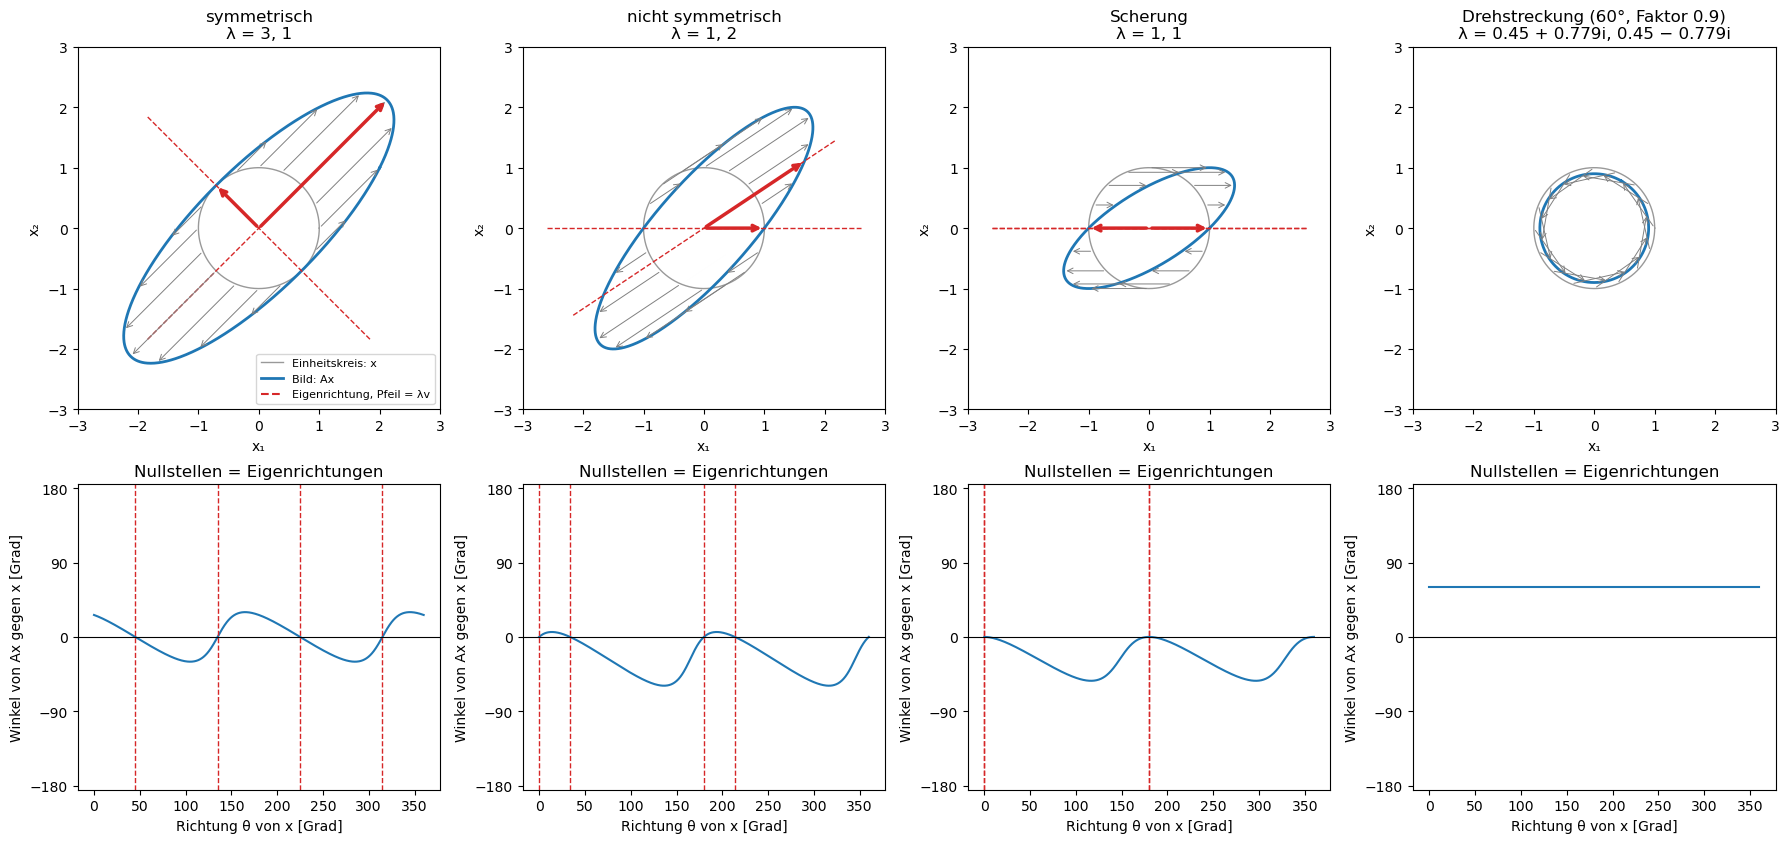

In [2]:
lam = sp.symbols("lambda")
drehung = sp.Rational(9, 10) * sp.Matrix([[sp.cos(sp.pi / 3), -sp.sin(sp.pi / 3)], [sp.sin(sp.pi / 3), sp.cos(sp.pi / 3)]])
matrizen1 = {
    "symmetrisch": sp.Matrix([[2, 1], [1, 2]]),
    "nicht symmetrisch": sp.Matrix([[1, sp.Rational(3, 2)], [0, 2]]),
    "Scherung": sp.Matrix([[1, 1], [0, 1]]),
    "Drehstreckung (60°, Faktor 0.9)": drehung,
}
for name, M in matrizen1.items():
    p = sp.expand((M - lam * sp.eye(2)).det())
    schoen = lambda e: str(e).replace("lambda", "λ").replace("**", "^").replace("*", "·").replace("I", "i")
    teile = [f"λ = {schoen(sp.nsimplify(w))} (algebraisch {a}, geometrisch {len(v)}, "
             f"Eigenvektor ({', '.join(schoen(sp.simplify(c)) for c in v[0])}))" for w, a, v in M.eigenvects()]
    print(f"{name}: det(A − λI) = {schoen(p)}\n    " + "\n    ".join(teile))

fig, axes = plt.subplots(2, 4, figsize=(18, 8.5), gridspec_kw={"height_ratios": [1.25, 1]})
theta = np.linspace(0, 2 * np.pi, 721)
kreis = np.array([np.cos(theta), np.sin(theta)])
for spalte, (name, M) in enumerate(matrizen1.items()):
    A = np.array(M.evalf(), dtype=float)
    ax = axes[0, spalte]
    bild = A @ kreis
    ax.plot(*kreis, color="0.6", lw=1, label="Einheitskreis: x")
    ax.plot(*bild, color="tab:blue", lw=2, label="Bild: Ax")
    for th in np.linspace(0, 2 * np.pi, 16, endpoint=False):
        x0 = np.array([np.cos(th), np.sin(th)])
        ax.annotate("", A @ x0, x0, arrowprops=dict(arrowstyle="->", color="0.5", lw=0.7))
    ew, ev = np.linalg.eig(A)
    for k in range(2):
        if abs(ew[k].imag) < 1e-12:
            v = np.real(ev[:, k])
            ax.plot([-2.6 * v[0], 2.6 * v[0]], [-2.6 * v[1], 2.6 * v[1]], "--", color="tab:red", lw=1)
            ax.annotate("", ew[k].real * v, (0, 0), arrowprops=dict(arrowstyle="->", color="tab:red", lw=2.5))
    ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_aspect("equal")
    ax.set_title(f"{name}\nλ = " + ", ".join(zahl(w) for w in ew))
    ax.set_xlabel("x₁"); ax.set_ylabel("x₂")
    if spalte == 0:
        ax.plot([], [], "--", color="tab:red", label="Eigenrichtung, Pfeil = λv")
        ax.legend(loc="lower right", fontsize=8)
    ax = axes[1, spalte]
    dreh = (np.degrees(np.arctan2(bild[1], bild[0]) - theta) + 180) % 360 - 180
    ax.plot(np.degrees(theta), dreh, color="tab:blue")
    ax.axhline(0, color="k", lw=0.8)
    for k in range(2):
        if abs(ew[k].imag) < 1e-12:
            richtung = np.degrees(np.arctan2(ev[1, k].real, ev[0, k].real)) % 180
            for r in (richtung, richtung + 180):
                ax.axvline(r, color="tab:red", ls="--", lw=1)
    ax.set_ylim(-185, 185); ax.set_yticks([-180, -90, 0, 90, 180])
    ax.set_xlabel("Richtung θ von x [Grad]"); ax.set_ylabel("Winkel von Ax gegen x [Grad]")
    ax.set_title("Nullstellen = Eigenrichtungen")
plt.tight_layout()
plt.show()

* In der **oberen Reihe** ist der graue Kreis die Menge aller Einheitsvektoren $\mathbf x$, die blaue Ellipse ihr Bild $A\mathbf x$; die grauen Pfeile verbinden einige $\mathbf x$ mit ihren Bildern. Die roten gestrichelten Geraden sind die Eigenrichtungen, die roten Pfeile die Vektoren $\lambda\mathbf v$. Bei der **symmetrischen** Matrix ($p = \lambda^2 - 4\lambda + 3$, $\lambda = 3$ und $1$) stehen die Eigenrichtungen $(1, 1)$ und $(-1, 1)$ senkrecht aufeinander und sind zugleich die Achsen der Ellipse. Bei der **nicht symmetrischen** Dreiecksmatrix ($\lambda = 1, 2$, die Diagonaleinträge) stehen die Eigenrichtungen $(1, 0)$ und $(3/2, 1)$ schief zueinander, und die Achsen der Ellipse liegen woanders.
* Die **Scherung** hat $p = (\lambda - 1)^2$: algebraische Vielfachheit 2, aber nur den Eigenvektor $(1, 0)$, geometrische Vielfachheit 1. Jeder andere Vektor wird nach rechts geschoben. Die **Drehstreckung** hat $p = \lambda^2 - 0.9\lambda + 0.81$ mit den Nullstellen $0.45\pm0.779i = 0.9\,e^{\pm i\pi/3}$ und den komplexen Eigenvektoren $(\pm i, 1)$; kein reeller Vektor behält seine Richtung, der Kreis wird nur verkleinert und gedreht.
* Die **untere Reihe** zeigt den Winkel von $A\mathbf x$ gegen $\mathbf x$ für alle Richtungen $\theta$. Die Nullstellen (rot gestrichelt) sind die Eigenrichtungen, jeweils zweimal, weil $\mathbf v$ und $-\mathbf v$ auf derselben Geraden liegen. Bei der Scherung berührt die Kurve die Null bei 0° und 180° nur, ohne sie zu kreuzen: das Bild der doppelten Nullstelle. Bei der Drehstreckung ist der Winkel überall 60°, es gibt keine Nullstelle.

##### *2. Potenzen: wer auf lange Sicht gewinnt*

Warum wird $A^k\mathbf x$ für großes $k$ vom größten Eigenwert beherrscht, und wie schnell vergisst eine Markov-Kette ihren Startzustand? Vorher überlegen: Braucht eine Kette aus zwei Gruppen von Zuständen, zwischen denen man selten wechselt, länger als eine gut gemischte?

Zuerst exakt mit sympy: $\begin{pmatrix}1&1\\1&0\end{pmatrix}^{30}$ enthält die Fibonacci-Zahlen, und die Eigenwerte $(1\pm\sqrt5)/2$ erklären ihr Wachstum. Dann drei Markov-Ketten auf sechs Zuständen: eine mit zufälligen Übergangswahrscheinlichkeiten („gut gemischt“), eine aus zwei Gruppen von je drei Zuständen mit vier schwachen Brücken (Gewicht 0.04 vor dem Normieren der Zeilen) und dieselbe mit der Dämpfung 0.85 aus PageRank. Gestartet wird in Zustand 0; verfolgt wird der Abstand $\Vert\mathbf p_k - \boldsymbol\pi\Vert_1$ der Verteilung nach $k$ Schritten zur stationären Verteilung. Zum Schluss läuft eine Irrfahrt 200 000 Schritte, und ihre Besuchshäufigkeiten werden mit $\boldsymbol\pi$ verglichen.

**Hintergrund & Fachbegriffe:**
- **Potenzen in der Eigenbasis:** Ist $\mathbf x = \sum_jc_j\mathbf v_j$, dann ist $A^k\mathbf x = \sum_jc_j\lambda_j^k\mathbf v_j$. Der Term mit dem größten $\vert\lambda_j\vert$ wächst am schnellsten und setzt sich durch; der relative Rest fällt wie $\vert\lambda_2/\lambda_1\vert^k$.
- **Markov-Kette und Übergangsmatrix:** $P_{ij}$ ist die Wahrscheinlichkeit, von Zustand $i$ nach $j$ zu springen; jede Zeile summiert sich zu 1 (**zeilenstochastisch**). Die Verteilung entwickelt sich als Zeilenvektor: $\mathbf p_{k+1} = \mathbf p_kP$.
- **Stationäre Verteilung:** $\boldsymbol\pi P = \boldsymbol\pi$, ein **linker Eigenvektor** zum Eigenwert 1. Alle Eigenwerte haben $\vert\lambda\vert\le1$; sind alle Einträge positiv, ist der Eigenwert 1 einfach und alle anderen haben $\vert\lambda\vert<1$ (Perron–Frobenius), also konvergiert die Kette gegen $\boldsymbol\pi$.
- **Spektrallücke:** $1 - \vert\lambda_2\vert$. Je kleiner sie ist, desto langsamer die Konvergenz. Zwei schwach verbundene Gruppen geben ein $\lambda_2$ nahe 1, weil der Ausgleich zwischen den Gruppen lange dauert.
- **PageRank-Dämpfung:** $G = \alpha P + (1 - \alpha)\frac1n\mathbf 1\mathbf 1^T$: Mit Wahrscheinlichkeit $1 - \alpha$ springt der Zufallssurfer auf eine beliebige Seite. Alle Eigenwerte außer der 1 werden dabei mit $\alpha$ multipliziert, also $\vert\lambda_2(G)\vert\le\alpha$, und die Potenzmethode konvergiert schnell.
- **Ergodensatz:** Für eine solche Kette nähern sich die Besuchshäufigkeiten einer einzigen langen Irrfahrt den Werten $\boldsymbol\pi$.

Fibonacci: [[1, 1], [1, 0]]^30 = [[1346269, 832040], [832040, 514229]]  Eigenwerte [1/2 - sqrt(5)/2, 1/2 + sqrt(5)/2]
  F_30 = 832040,  φ^30/√5 = 832040.000000
gut gemischt: Eigenwerte 1, -0.213, 0.173, -0.11, 0.0221 + 0.0674i, 0.0221 − 0.0674i
    π = [0.1447 0.1615 0.1693 0.1801 0.1846 0.1598], |λ₂| = 0.2133, gemessene Rate von ‖p_k − π‖₁: 0.2042; Abstand nach 20 Schritten 1.8e-14, nach 79 Schritten 6.7e-16
zwei Gruppen: Eigenwerte 1, 0.983, 0.0751, -0.0538, 0.00476 + 0.0224i, 0.00476 − 0.0224i
    π = [0.1564 0.208  0.1712 0.1618 0.1599 0.1427], |λ₂| = 0.9825, gemessene Rate von ‖p_k − π‖₁: 0.9825; Abstand nach 20 Schritten 6.5e-01, nach 79 Schritten 2.3e-01
zwei Gruppen + Dämpfung 0.85: Eigenwerte 1, 0.835, 0.0638, -0.0457, 0.00405 + 0.019i, 0.00405 − 0.019i
    π = [0.1499 0.1909 0.1622 0.1718 0.1703 0.155 ], |λ₂| = 0.8352, gemessene Rate von ‖p_k − π‖₁: 0.8352; Abstand nach 20 Schritten 2.7e-02, nach 79 Schritten 6.5e-07
Irrfahrt mit 200 000 Schritten (zwei Gruppen): Häufigkeiten

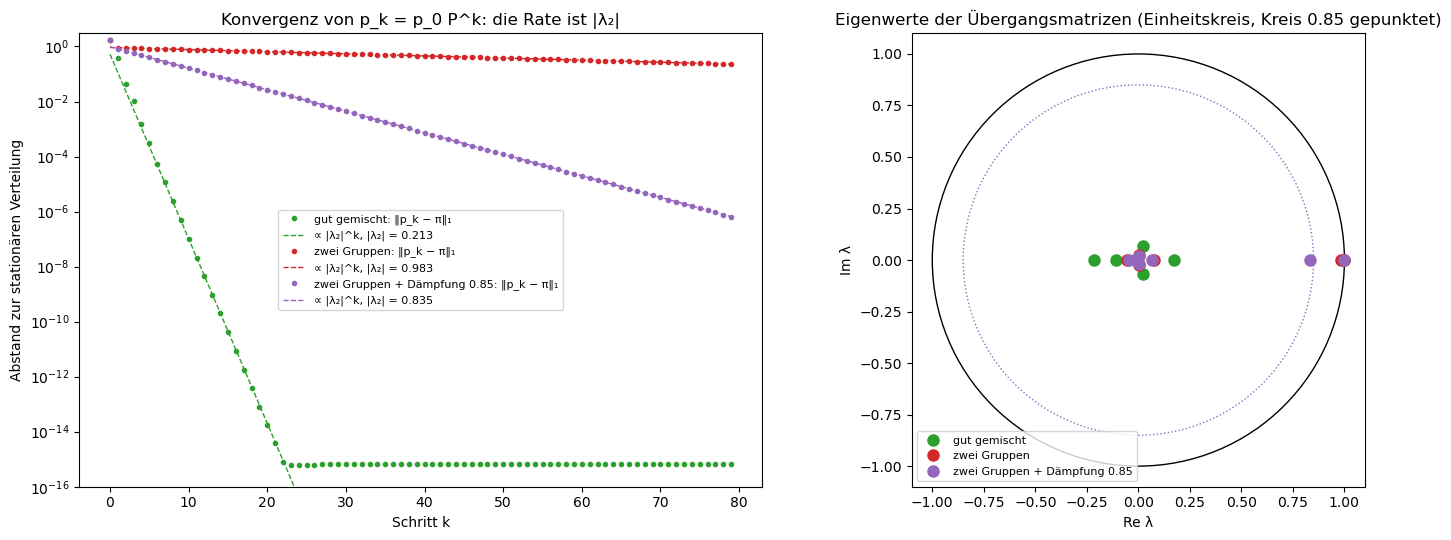

In [3]:
fib = sp.Matrix([[1, 1], [1, 0]])
goldener_schnitt = (1 + sp.sqrt(5)) / 2
print("Fibonacci: [[1, 1], [1, 0]]^30 =", (fib**30).tolist(), " Eigenwerte", list(fib.eigenvals()))
print(f"  F_30 = {(fib**30)[0, 1]},  φ^30/√5 = {float(goldener_schnitt**30 / sp.sqrt(5)):.6f}")

n2 = 6
P_schnell = rng.random((n2, n2))
P_schnell /= P_schnell.sum(axis=1, keepdims=True)
P_langsam = np.zeros((n2, n2))
P_langsam[:3, :3] = rng.random((3, 3)) + 0.5
P_langsam[3:, 3:] = rng.random((3, 3)) + 0.5
P_langsam[0, 4] = P_langsam[2, 3] = P_langsam[3, 1] = P_langsam[5, 2] = 0.04   # schwache Brücken zwischen den Gruppen
P_langsam /= P_langsam.sum(axis=1, keepdims=True)
daempfung = 0.85
P_google = daempfung * P_langsam + (1 - daempfung) / n2                    # PageRank: mit 15 % zufällig springen
ketten = {"gut gemischt": P_schnell, "zwei Gruppen": P_langsam, "zwei Gruppen + Dämpfung 0.85": P_google}

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for (name, P), farbe in zip(ketten.items(), ["tab:green", "tab:red", "tab:purple"]):
    ew, links = np.linalg.eig(P.T)                                           # linke Eigenvektoren: π P = π
    ordnung = np.argsort(-np.abs(ew))
    ew, links = ew[ordnung], links[:, ordnung]
    pi = np.real(links[:, 0]) / np.real(links[:, 0]).sum()
    p, abstand = np.eye(n2)[0], []
    for k in range(80):
        abstand.append(np.abs(p - pi).sum())
        p = p @ P
    abstand = np.array(abstand)
    l2 = np.abs(ew[1])
    gueltig = np.arange(3, 80)[abstand[3:] > 1e-12]                         # oberhalb der Rundungsgrenze
    rate = np.exp(np.polyfit(gueltig, np.log(abstand[gueltig]), 1)[0])
    print(f"{name}: Eigenwerte " + ", ".join(zahl(w) for w in ew)
          + f"\n    π = {np.round(pi, 4)}, |λ₂| = {l2:.4f}, gemessene Rate von ‖p_k − π‖₁: {rate:.4f};"
          f" Abstand nach 20 Schritten {abstand[20]:.1e}, nach 79 Schritten {abstand[79]:.1e}")
    axes[0].semilogy(abstand, "o", ms=3, color=farbe, label=f"{name}: ‖p_k − π‖₁")
    k_anker = gueltig[len(gueltig) // 2]
    axes[0].semilogy(np.arange(80), abstand[k_anker] * l2**(np.arange(80) - k_anker), "--", color=farbe, lw=1,
                     label=f"∝ |λ₂|^k, |λ₂| = {l2:.3f}")
    axes[1].plot(ew.real, ew.imag, "o", ms=8, color=farbe, label=name)

# Ergodensatz: die Häufigkeiten einer langen Irrfahrt gegen π
zustand, besuche = 0, np.zeros(n2)
kumuliert = np.cumsum(P_langsam, axis=1)
zufall = rng.random(200_000)
for u in zufall:
    zustand = min(int(np.searchsorted(kumuliert[zustand], u)), n2 - 1)
    besuche[zustand] += 1
ew_l, links_l = np.linalg.eig(P_langsam.T)
pi_l = np.real(links_l[:, np.argmax(np.real(ew_l))]); pi_l /= pi_l.sum()
print(f"Irrfahrt mit 200 000 Schritten (zwei Gruppen): Häufigkeiten {np.round(besuche / besuche.sum(), 4)}, π = {np.round(pi_l, 4)}")

axes[0].set_ylim(1e-16, 3); axes[0].set_xlabel("Schritt k"); axes[0].set_ylabel("Abstand zur stationären Verteilung")
axes[0].set_title("Konvergenz von p_k = p_0 P^k: die Rate ist |λ₂|"); axes[0].legend(fontsize=8)
axes[1].add_patch(Circle((0, 0), 1, fill=False, color="k", lw=1))
axes[1].add_patch(Circle((0, 0), daempfung, fill=False, color="tab:purple", ls=":", lw=1))
axes[1].set_aspect("equal"); axes[1].set_xlim(-1.1, 1.1); axes[1].set_ylim(-1.1, 1.1)
axes[1].set_xlabel("Re λ"); axes[1].set_ylabel("Im λ"); axes[1].legend(fontsize=8, loc="lower left")
axes[1].set_title("Eigenwerte der Übergangsmatrizen (Einheitskreis, Kreis 0.85 gepunktet)")
plt.tight_layout()
plt.show()

* **Fibonacci:** $\begin{pmatrix}1&1\\1&0\end{pmatrix}^{30} = \begin{pmatrix}1346269 & 832040\\ 832040 & 514229\end{pmatrix}$, also $F_{30} = 832040$. Die Eigenwerte sind $\varphi = (1 + \sqrt5)/2 = 1.618$ und $-1/\varphi = -0.618$. Weil $(1/\varphi)^{30}$ winzig ist, ist $F_{30} = \varphi^{30}/\sqrt5$ bis auf Rundung auf sechs Nachkommastellen (832040.000000).
* Das **linke Bild** zeigt den Abstand zur stationären Verteilung gegen die Zahl der Schritte, logarithmisch. Jede Kette gibt eine Gerade, deren Steigung $\vert\lambda_2\vert$ ist (gestrichelt). Die gut gemischte Kette ($\vert\lambda_2\vert = 0.213$; gemessen 0.204, weil der nächste Eigenwert 0.173 nicht viel kleiner ist) ist nach 20 Schritten bei $2\cdot10^{-14}$, kurz darauf an der Rundungsgrenze. Die Kette mit zwei Gruppen hat $\vert\lambda_2\vert = 0.9825$; gemessene Rate und Eigenwert stimmen auf vier Stellen überein, und nach 79 Schritten ist der Abstand noch 0.23. Mit Dämpfung wird $\vert\lambda_2\vert = 0.835 = 0.85\cdot0.9825$, und nach 79 Schritten ist der Abstand $6.5\cdot10^{-7}$.
* Das **rechte Bild** zeigt die Eigenwerte der drei Übergangsmatrizen in der komplexen Ebene. Alle liegen im Einheitskreis, jede Matrix hat genau einen Eigenwert 1. Bei der Kette mit zwei Gruppen liegt der zweite Eigenwert (rot) dicht neben der 1; die Dämpfung zieht ihn (lila) auf 0.835, knapp innerhalb des gepunkteten Kreises vom Radius 0.85. Die übrigen Eigenwerte liegen nahe 0.
* Die Irrfahrt mit 200 000 Schritten besucht die sechs Zustände mit den Häufigkeiten 0.159, 0.212, 0.171, 0.161, 0.157, 0.140; die stationäre Verteilung ist 0.156, 0.208, 0.171, 0.162, 0.160, 0.143. Abweichungen bis 0.004 sind für 200 000 Schritte viel: Wegen $\lambda_2\approx0.98$ bleibt die Irrfahrt lange in einer Gruppe, aufeinanderfolgende Zustände sind stark korreliert, und die Zahl der effektiv unabhängigen Stichproben ist nur etwa $200\,000\cdot(1 - \lambda_2)/(1 + \lambda_2)\approx1800$.

##### *3. Lineare Differentialgleichungen: Spur und Determinante entscheiden*

Wie verhalten sich die Lösungen von $\dot{\mathbf x} = A\mathbf x$ in der Ebene, und kann man das aus Spur und Determinante ablesen, ohne die Eigenwerte auszurechnen? Vorher überlegen: Was passiert bei $\mathrm{tr}A = 0$ und $\det A>0$?

Für sechs Matrizen werden Spur $\tau$, Determinante $\Delta$ und die Eigenwerte berechnet, einmal mit `numpy.linalg.eigvals` und einmal mit der Formel $\lambda = (\tau\pm\sqrt{\tau^2 - 4\Delta})/2$. Die Phasenporträts zeigen die Stromlinien des Feldes $A\mathbf x$, die roten Geraden die reellen Eigenrichtungen. Links steht die Spur-Determinanten-Ebene mit den Orten der sechs Matrizen.

**Hintergrund & Fachbegriffe:**
- **Lösung in der Eigenbasis:** $\mathbf x(t) = \sum_jc_je^{\lambda_jt}\mathbf v_j$. Der Realteil von $\lambda_j$ entscheidet über Wachstum ($>0$) oder Zerfall ($<0$), der Imaginärteil gibt eine Drehung mit der Kreisfrequenz $\mathrm{Im}\,\lambda_j$.
- **Spur und Determinante einer 2×2-Matrix:** $\tau = \lambda_1 + \lambda_2$, $\Delta = \lambda_1\lambda_2$; die Eigenwerte sind die Nullstellen von $\lambda^2 - \tau\lambda + \Delta$. Die **Diskriminante** $\tau^2 - 4\Delta$ entscheidet zwischen reellen ($>0$) und komplexen ($<0$) Eigenwerten.
- **Knoten, Sattel, Strudel, Zentrum:** reelle Eigenwerte gleichen Vorzeichens (alle Bahnen laufen in den Ursprung hinein oder aus ihm heraus); reelle Eigenwerte verschiedenen Vorzeichens, $\Delta<0$ (nur entlang einer Richtung hinein, entlang der anderen hinaus); komplexe Eigenwerte mit Realteil $\neq0$ (Spiralen); rein imaginäre Eigenwerte, $\tau = 0$ und $\Delta>0$ (geschlossene Ellipsen).
- **Asymptotisch stabil:** alle Bahnen laufen in den Ursprung; in der Ebene genau dann, wenn $\tau<0$ und $\Delta>0$. Für nichtlineare Systeme gilt dasselbe für die **Jacobi-Matrix** am Fixpunkt (Linearisierung), solange kein Eigenwert den Realteil null hat.

1 stabiler Knoten (Senke): τ = -3.00, Δ = +2.00, τ² − 4Δ = +1.00 → λ = -2, -1; aus τ und Δ: -1, -2
2 instabiler Knoten (Quelle): τ = +3.00, Δ = +2.00, τ² − 4Δ = +1.00 → λ = 2, 1; aus τ und Δ: 2, 1
3 Sattel: τ = +0.00, Δ = -2.00, τ² − 4Δ = +8.00 → λ = 1.41, -1.41; aus τ und Δ: 1.41, -1.41


4 stabiler Strudel: τ = -1.00, Δ = +4.25, τ² − 4Δ = -16.00 → λ = -0.5 + 2i, -0.5 − 2i; aus τ und Δ: -0.5 + 2i, -0.5 − 2i
5 instabiler Strudel: τ = +0.60, Δ = +4.09, τ² − 4Δ = -16.00 → λ = 0.3 + 2i, 0.3 − 2i; aus τ und Δ: 0.3 + 2i, 0.3 − 2i
6 Zentrum: τ = +0.00, Δ = +2.00, τ² − 4Δ = -8.00 → λ = 0 + 1.41i, 0 − 1.41i; aus τ und Δ: 0 + 1.41i, 0 − 1.41i


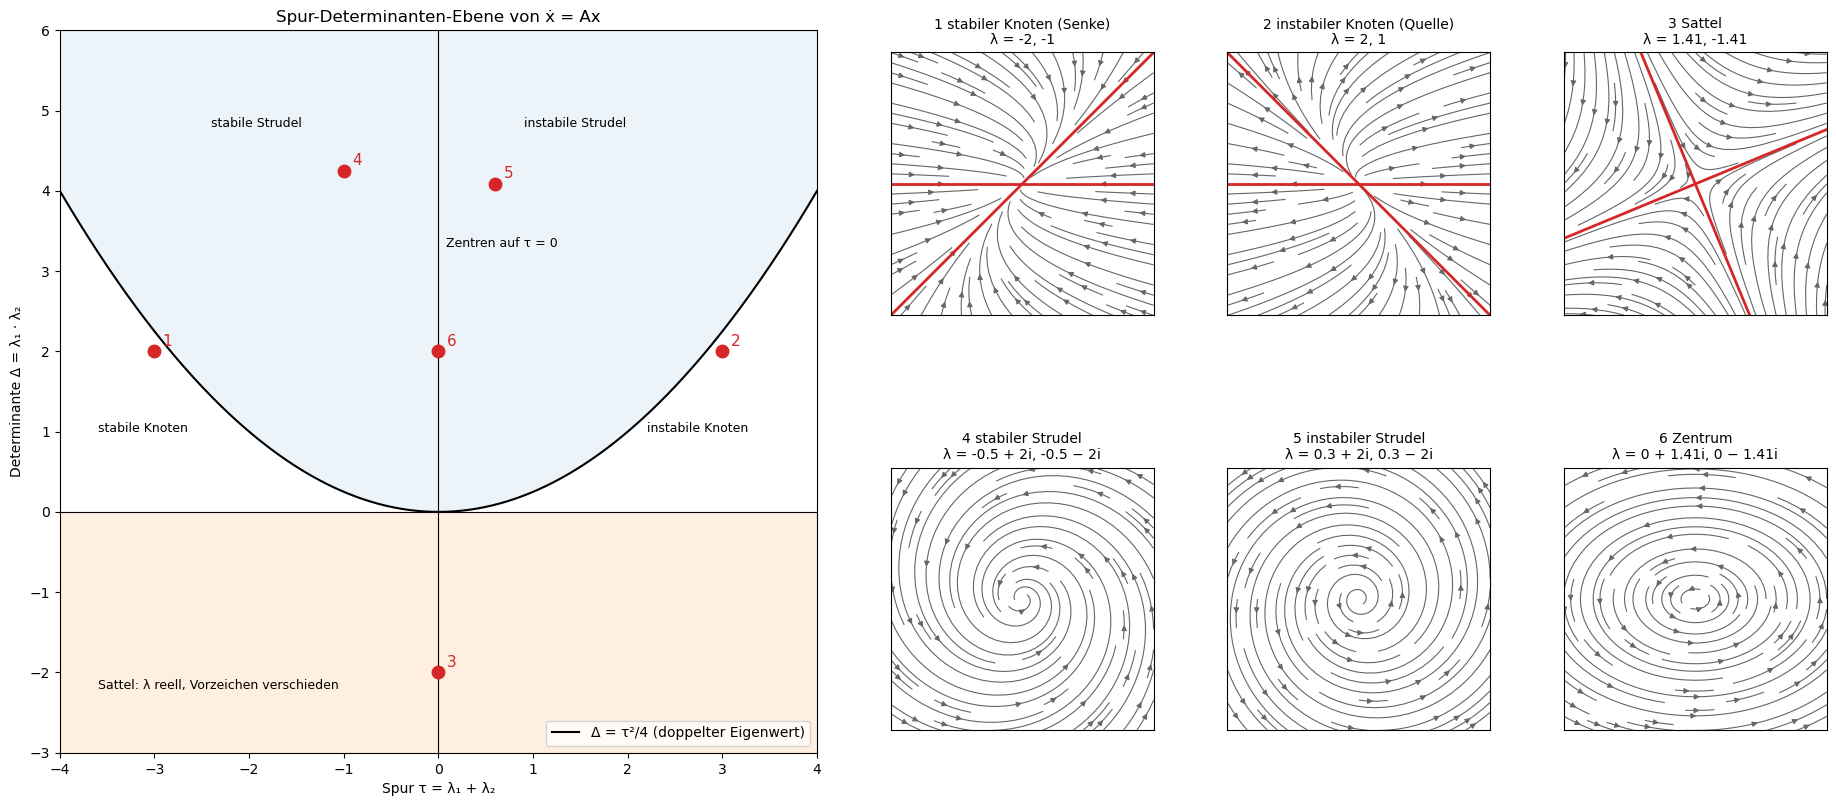

In [4]:
beispiele3 = {
    "1 stabiler Knoten (Senke)": np.array([[-2.0, 1.0], [0.0, -1.0]]),
    "2 instabiler Knoten (Quelle)": np.array([[2.0, 1.0], [0.0, 1.0]]),
    "3 Sattel": np.array([[1.0, 1.0], [1.0, -1.0]]),
    "4 stabiler Strudel": np.array([[-0.5, -2.0], [2.0, -0.5]]),
    "5 instabiler Strudel": np.array([[0.3, -2.0], [2.0, 0.3]]),
    "6 Zentrum": np.array([[0.0, -2.0], [1.0, 0.0]]),
}
fig = plt.figure(figsize=(19, 8.5))
gs = GridSpec(2, 5, figure=fig, width_ratios=[1.3, 1.3, 1, 1, 1], hspace=0.35)
ax0 = fig.add_subplot(gs[:, :2])
tau = np.linspace(-4, 4, 400)
ax0.plot(tau, tau**2 / 4, color="k", lw=1.5, label="Δ = τ²/4 (doppelter Eigenwert)")
ax0.axhline(0, color="k", lw=0.8); ax0.axvline(0, color="k", lw=0.8)
ax0.fill_between(tau, -3, 0, color="tab:orange", alpha=0.12)
ax0.fill_between(tau, tau**2 / 4, 6, color="tab:blue", alpha=0.08)
for text, xy in [("Sattel: λ reell, Vorzeichen verschieden", (-3.6, -2.2)), ("stabile Knoten", (-3.6, 1.0)),
                 ("instabile Knoten", (2.2, 1.0)), ("stabile Strudel", (-2.4, 4.8)), ("instabile Strudel", (0.9, 4.8)),
                 ("Zentren auf τ = 0", (0.08, 3.3))]:
    ax0.text(*xy, text, fontsize=9)
for k, (name, A) in enumerate(beispiele3.items()):
    tr, det = np.trace(A), np.linalg.det(A)
    ew = np.linalg.eigvals(A)
    formel = (tr + np.array([1, -1]) * np.sqrt(complex(tr**2 - 4 * det))) / 2
    print(f"{name}: τ = {tr:+.2f}, Δ = {det:+.2f}, τ² − 4Δ = {tr**2 - 4 * det:+.2f} → λ = " + ", ".join(zahl(z) for z in ew)
          + "; aus τ und Δ: " + ", ".join(zahl(z) for z in formel))
    ax0.plot(tr, det, "o", ms=9, color="tab:red")
    ax0.annotate(name.split()[0], (tr, det), xytext=(6, 4), textcoords="offset points", fontsize=11, color="tab:red")
    ax = fig.add_subplot(gs[k // 3, 2 + k % 3])
    s3 = np.linspace(-2, 2, 41)
    XX, YY = np.meshgrid(s3, s3)
    ax.streamplot(XX, YY, A[0, 0] * XX + A[0, 1] * YY, A[1, 0] * XX + A[1, 1] * YY, density=0.9, color="0.4",
                  linewidth=0.8, arrowsize=0.8)
    w, V = np.linalg.eig(A)
    for j in range(2):
        if abs(w[j].imag) < 1e-12:
            ax.plot([-3 * V[0, j], 3 * V[0, j]], [-3 * V[1, j], 3 * V[1, j]], color="tab:red", lw=2)
    ax.set_xlim(-2, 2); ax.set_ylim(-2, 2); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{name}\nλ = " + ", ".join(zahl(z) for z in w), fontsize=10)
ax0.set_xlim(-4, 4); ax0.set_ylim(-3, 6)
ax0.set_xlabel("Spur τ = λ₁ + λ₂"); ax0.set_ylabel("Determinante Δ = λ₁ · λ₂")
ax0.set_title("Spur-Determinanten-Ebene von ẋ = Ax"); ax0.legend(loc="lower right")
plt.subplots_adjust(left=0.05, right=0.98, top=0.93, bottom=0.08, wspace=0.25)
plt.show()

* Das **linke Bild** ist die Spur-Determinanten-Ebene. Die Parabel $\Delta = \tau^2/4$ trennt reelle Eigenwerte (darunter) von komplexen (darüber, blau). Unterhalb der Achse $\Delta = 0$ (orange) haben die Eigenwerte verschiedene Vorzeichen: Sattel. Links von $\tau = 0$ ist alles stabil, rechts instabil; auf der positiven $\Delta$-Achse liegen die Zentren. Die roten Punkte sind die sechs Beispiele.
* Die **sechs Phasenporträts** bestätigen die Einteilung. Beim stabilen Knoten ($\tau = -3$, $\Delta = 2$, $\lambda = -2, -1$) laufen alle Bahnen in den Ursprung, zuletzt entlang der Eigenrichtung zu $\lambda = -1$, weil der Anteil zu $\lambda = -2$ schneller abklingt. Der instabile Knoten ($\lambda = 2, 1$) ist dasselbe Bild mit umgekehrten Pfeilen. Beim Sattel ($\Delta = -2$, $\lambda = \pm1.41$) kommen die Bahnen entlang der einen roten Geraden herein und laufen entlang der anderen hinaus. Die Strudel ($\lambda = -0.5\pm2i$ und $0.3\pm2i$) drehen sich mit der Kreisfrequenz 2 nach innen oder außen, das Zentrum ($\lambda = \pm1.41i$) hat geschlossene Ellipsen.
* Die Eigenwerte aus der Formel mit $\tau$ und $\Delta$ stimmen bei allen sechs Matrizen mit `eigvals` überein. In zwei Dimensionen reichen also zwei basisunabhängige Zahlen, um das qualitative Verhalten zu kennen; in $n$ Dimensionen braucht man die $n$ Koeffizienten des charakteristischen Polynoms (Experiment 6).

##### *4. Schwingungen: Eigenfrequenzen messen*

Bei welchen Frequenzen schwingt eine Kette aus acht Massen und neun Federn, und kann man diese Eigenwerte aus der Bewegung einer einzigen Masse ablesen, ohne die Matrix zu diagonalisieren? Vorher überlegen: Wie viele Frequenzen erwartet man, und kommen alle in der Bewegung der ersten Masse vor?

Die Bewegungsgleichung ist $\ddot{\mathbf x} = -K\mathbf x$ mit der Steifigkeitsmatrix $K = \mathrm{tridiag}(-1, 2, -1)$ (gleiche Massen $m$ und Federn $k$, feste Enden, Einheiten mit $k/m = 1$). Die Eigenwerte von $K$ geben die Eigenfrequenzen $\omega_k = \sqrt{\lambda_k}$; die Formel dafür ist $2\sin\frac{k\pi}{2(N + 1)}$. Dann wird die Bewegung nach einem zufälligen Anfangsstoß numerisch integriert (Runge–Kutta 8. Ordnung, 600 Zeiteinheiten), nur die Auslenkung der ersten Masse wird aufgezeichnet, und ihr Spektrum wird mit der FFT berechnet. Die Lage jeder Spitze wird mit einer Parabel durch die drei höchsten Punkte verfeinert.

**Hintergrund & Fachbegriffe:**
- **Normalmode:** eine Bewegung, bei der alle Massen mit derselben Frequenz schwingen, $\mathbf x(t) = \mathbf v\cos(\omega t)$. Eingesetzt folgt $K\mathbf v = \omega^2\mathbf v$: Die Moden sind die Eigenvektoren von $K$, die Quadrate der Eigenfrequenzen die Eigenwerte.
- **Allgemeine Bewegung:** Jede Lösung ist eine Überlagerung der Moden; beim Start aus der Ruhe ist $x_1(t) = \sum_kv_k(1)\,(\mathbf v_k\cdot\mathbf x_0)\cos(\omega_kt)$. Im Spektrum von $x_1$ steht deshalb bei jedem $\omega_k$ eine Spitze, deren Höhe sagt, wie stark die Mode angeregt ist und wie stark Masse 1 an ihr teilnimmt.
- **FFT und Fenster:** Die diskrete Fourier-Transformation zerlegt ein abgetastetes Signal in Frequenzen. Ein endliches Messfenster verschmiert jede Spitze; das **Hann-Fenster** dämpft die Ränder und verringert so das Übersprechen zwischen Spitzen (Leckeffekt). Die Auflösung ist etwa $2\pi/T$; Nullauffüllen (Zero-Padding) macht das Frequenzgitter feiner, ohne neue Information hinzuzufügen.
- **Spektroskopie:** So misst man Eigenwerte im Labor. Infrarot- und Raman-Spektren zeigen die Normalmoden von Molekülen, die Modalanalyse von Brücken und Flugzeugflügeln die Eigenfrequenzen der Struktur, Spektrallinien von Atomen die Differenzen der Energieeigenwerte.

Eigenfrequenzen ω_k = √λ_k: [0.3473  0.68404 1.      1.28558 1.53209 1.73205 1.87939 1.96962]
Formel 2 sin(kπ/18), größte Abweichung 1.2e-15


aus dem Spektrum gemessen:       [0.3473  0.68404 1.      1.28558 1.53209 1.73203 1.87939 1.96962]
größte Abweichung 1.8e-05, Auflösung 2π/T = 0.0105
Höhen der Spitzen (relativ zur höchsten): [0.242 0.261 0.659 0.046 0.475 0.177 1.    0.358]


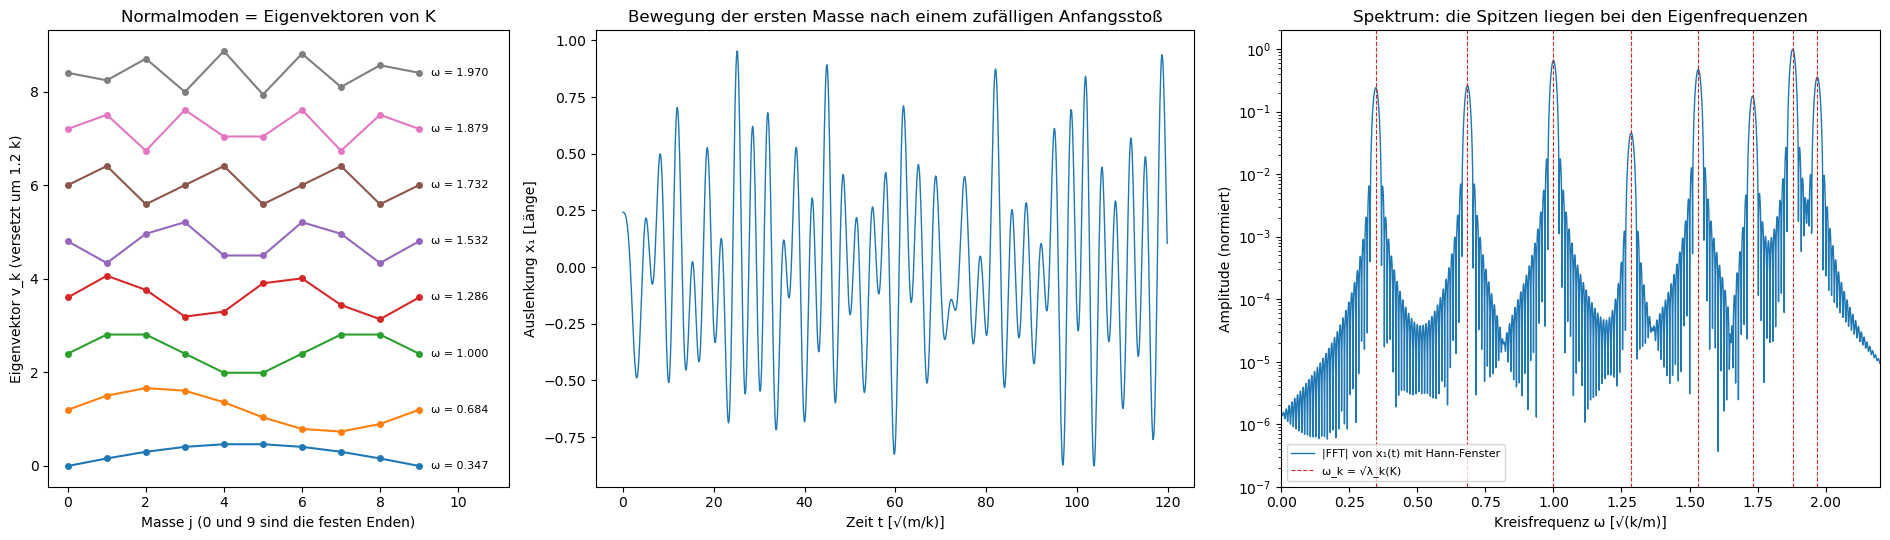

In [5]:
N4 = 8
K4 = 2 * np.eye(N4) - np.eye(N4, k=1) - np.eye(N4, k=-1)               # Federkette mit festen Enden, k/m = 1
w2, moden = np.linalg.eigh(K4)
omega_exakt = np.sqrt(w2)
omega_formel = 2 * np.sin(np.arange(1, N4 + 1) * np.pi / (2 * (N4 + 1)))
print("Eigenfrequenzen ω_k = √λ_k:", np.round(omega_exakt, 5))
print(f"Formel 2 sin(kπ/18), größte Abweichung {np.max(np.abs(omega_exakt - omega_formel)):.1e}")

# Die Bewegung wird numerisch integriert, ohne Eigenwerte; die Frequenzen liest man danach aus dem Spektrum ab.
x0_4 = rng.standard_normal(N4)
dt4, T4 = 0.1, 600.0
t4 = np.arange(0, T4, dt4)
loes = solve_ivp(lambda t, q: np.concatenate([q[N4:], -K4 @ q[:N4]]), (0, T4), np.concatenate([x0_4, np.zeros(N4)]),
                 t_eval=t4, method="DOP853", rtol=1e-10, atol=1e-12)
signal4 = loes.y[0]                                                       # Auslenkung der ersten Masse
fenster = np.hanning(len(signal4))
nfft = 2**18
spektrum = np.abs(np.fft.rfft(signal4 * fenster, nfft))
omega_achse = 2 * np.pi * np.fft.rfftfreq(nfft, dt4)
spitzen, _ = find_peaks(spektrum, height=spektrum.max() * 1e-4, distance=200)
spitzen = np.sort(spitzen[np.argsort(-spektrum[spitzen])][:N4])
gemessen = []
for i in spitzen:                                                         # Parabel durch die drei höchsten Punkte
    a, b, c = np.log(spektrum[i - 1:i + 2])
    gemessen.append(omega_achse[i] + 0.5 * (a - c) / (a - 2 * b + c) * (omega_achse[1] - omega_achse[0]))
gemessen = np.array(gemessen)
print("aus dem Spektrum gemessen:      ", np.round(gemessen, 5))
print(f"größte Abweichung {np.max(np.abs(gemessen - omega_exakt)):.1e}, Auflösung 2π/T = {2 * np.pi / T4:.4f}")
print("Höhen der Spitzen (relativ zur höchsten):", np.round(spektrum[spitzen] / spektrum.max(), 3))

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), gridspec_kw={"width_ratios": [1, 1.3, 1.3]})
ax = axes[0]
for k in range(N4):
    ax.plot(np.arange(N4 + 2), np.concatenate([[0], moden[:, k], [0]]) + 1.2 * k, "o-", ms=4)
    ax.text(N4 + 1.3, 1.2 * k, f"ω = {omega_exakt[k]:.3f}", va="center", fontsize=8)
ax.set_xlim(-0.5, N4 + 3.3); ax.set_xlabel("Masse j (0 und 9 sind die festen Enden)")
ax.set_ylabel("Eigenvektor v_k (versetzt um 1.2 k)"); ax.set_title("Normalmoden = Eigenvektoren von K")
ax = axes[1]
ax.plot(t4[t4 < 120], signal4[t4 < 120], lw=1)
ax.set_xlabel("Zeit t [√(m/k)]"); ax.set_ylabel("Auslenkung x₁ [Länge]")
ax.set_title("Bewegung der ersten Masse nach einem zufälligen Anfangsstoß")
ax = axes[2]
ax.semilogy(omega_achse, spektrum / spektrum.max(), lw=1, label="|FFT| von x₁(t) mit Hann-Fenster")
for k, w in enumerate(omega_exakt):
    ax.axvline(w, color="tab:red", ls="--", lw=0.8, label="ω_k = √λ_k(K)" if k == 0 else None)
ax.set_xlim(0, 2.2); ax.set_ylim(1e-7, 2)
ax.set_xlabel("Kreisfrequenz ω [√(k/m)]"); ax.set_ylabel("Amplitude (normiert)")
ax.set_title("Spektrum: die Spitzen liegen bei den Eigenfrequenzen"); ax.legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

* Das **linke Bild** zeigt die acht Eigenvektoren von $K$ übereinander, mit den festen Enden 0 und 9. Die unterste Mode ($\omega = 0.347$) hat keinen Knoten, alle Massen schwingen gleichsinnig; jede höhere Mode hat einen Vorzeichenwechsel mehr, die oberste ($\omega = 1.970$) wechselt von Masse zu Masse das Vorzeichen. Es sind Sinuskurven $\sin(jk\pi/9)$, an den Massen abgetastet.
* Das **mittlere Bild** zeigt die Auslenkung der ersten Masse in den ersten 120 Zeiteinheiten. Sie sieht unregelmäßig aus, weil acht Schwingungen überlagert sind, deren Frequenzen in keinem einfachen Verhältnis stehen.
* Das **rechte Bild** ist das Spektrum dieses Signals, logarithmisch. Es hat genau acht Spitzen, und jede liegt auf einer roten Linie bei $\sqrt{\lambda_k(K)}$. Die aus dem Spektrum abgelesenen Frequenzen 0.3473, 0.68404, 1.00000, 1.28558, 1.53209, 1.73203, 1.87939, 1.96962 weichen höchstens um $1.8\cdot10^{-5}$ von den Eigenwerten ab, obwohl die Auflösung $2\pi/T = 0.0105$ ist: Die Parabel trifft die Mitte einer glatten, isolierten Spitze viel genauer als das Gitter. Die Höhen sind verschieden; die Spitze bei 1.286 ist etwa zwanzigmal kleiner als die bei 1.879, weil der zufällige Stoß diese Mode kaum angeregt hat. Hätte man nur die Bewegung, aber nicht die Matrix, würde man so die Eigenwerte messen.

##### *5. Daten: Hauptkomponenten sind Eigenvektoren*

In welche Richtungen streuen Daten am stärksten, und wie viel verliert man, wenn man nur die stärksten Richtungen behält? Vorher überlegen: Wie viele der 64 Pixelrichtungen braucht man für 90 % der Varianz handgeschriebener Ziffern?

Zuerst 500 Punkte aus einer Normalverteilung, deren Hauptachse um 30° gedreht ist (Varianzen 9 und 1). Dann der Ziffern-Datensatz aus scikit-learn (1797 Bilder mit 8×8 Pixeln, Grauwerte 0 bis 16, aus dem UCI-Archiv; er wird mit dem Paket geliefert): Kovarianzmatrix der 64 Pixel, ihre Eigenwerte, der erklärte Anteil und der Rekonstruktionsfehler mit $k$ Komponenten.

**Hintergrund & Fachbegriffe:**
- **Kovarianzmatrix:** $C = \frac1{n-1}\sum_i(\mathbf x_i - \bar{\mathbf x})(\mathbf x_i - \bar{\mathbf x})^T$, symmetrisch und positiv semidefinit. Die Varianz der Daten in Richtung eines Einheitsvektors $\mathbf u$ ist $\mathbf u^TC\mathbf u$, ein Rayleigh-Quotient.
- **Hauptkomponentenanalyse (PCA):** Die Richtung größter Varianz maximiert $\mathbf u^TC\mathbf u$; das ist der Eigenvektor zum größten Eigenwert. Die nächste Richtung (senkrecht zur ersten) ist der Eigenvektor zum zweitgrößten, und so weiter. Der Eigenwert ist die Varianz entlang seiner Richtung.
- **Erklärter Anteil:** $\sum_{i\le k}\lambda_i/\mathrm{tr}\,C$; die Spur ist die Gesamtvarianz, die Summe der Varianzen aller Pixel.
- **Rekonstruktionsfehler (Eckart–Young):** Projiziert man die Daten auf die ersten $k$ Eigenvektoren, ist der mittlere quadratische Fehler genau die Summe der weggelassenen Eigenwerte, und kein anderer $k$-dimensionaler Unterraum ist besser.
- **SVD:** Praktisch rechnet man PCA mit der Singulärwertzerlegung der zentrierten Datenmatrix $X = U\Sigma V^T$; die Spalten von $V$ sind die Eigenvektoren von $C$, und $\lambda_i = \sigma_i^2/(n - 1)$.

Punktwolke: Kovarianz-Eigenwerte [8.529 0.912] (wahr 9 und 1), Hauptachse bei 29.2° (wahr 30°)
Ziffern: 1797 Bilder mit 64 Pixeln; Spur der Kovarianz = Gesamtvarianz 1202.1
  k =  2: erklärter Anteil 0.285, Rekonstruktionsfehler  859.4230, Summe der übrigen Eigenwerte  859.4230
  k =  5: erklärter Anteil 0.545, Rekonstruktionsfehler  547.0211, Summe der übrigen Eigenwerte  547.0211
  k = 10: erklärter Anteil 0.738, Rekonstruktionsfehler  314.6901, Summe der übrigen Eigenwerte  314.6901
  k = 20: erklärter Anteil 0.894, Rekonstruktionsfehler  127.0633, Summe der übrigen Eigenwerte  127.0633
  k = 30: erklärter Anteil 0.959, Rekonstruktionsfehler   49.1854, Summe der übrigen Eigenwerte   49.1854
  Pixel, die in allen Bildern gleich sind (Varianz 0): 3
  für 90 % der Varianz braucht man 21 von 64 Komponenten


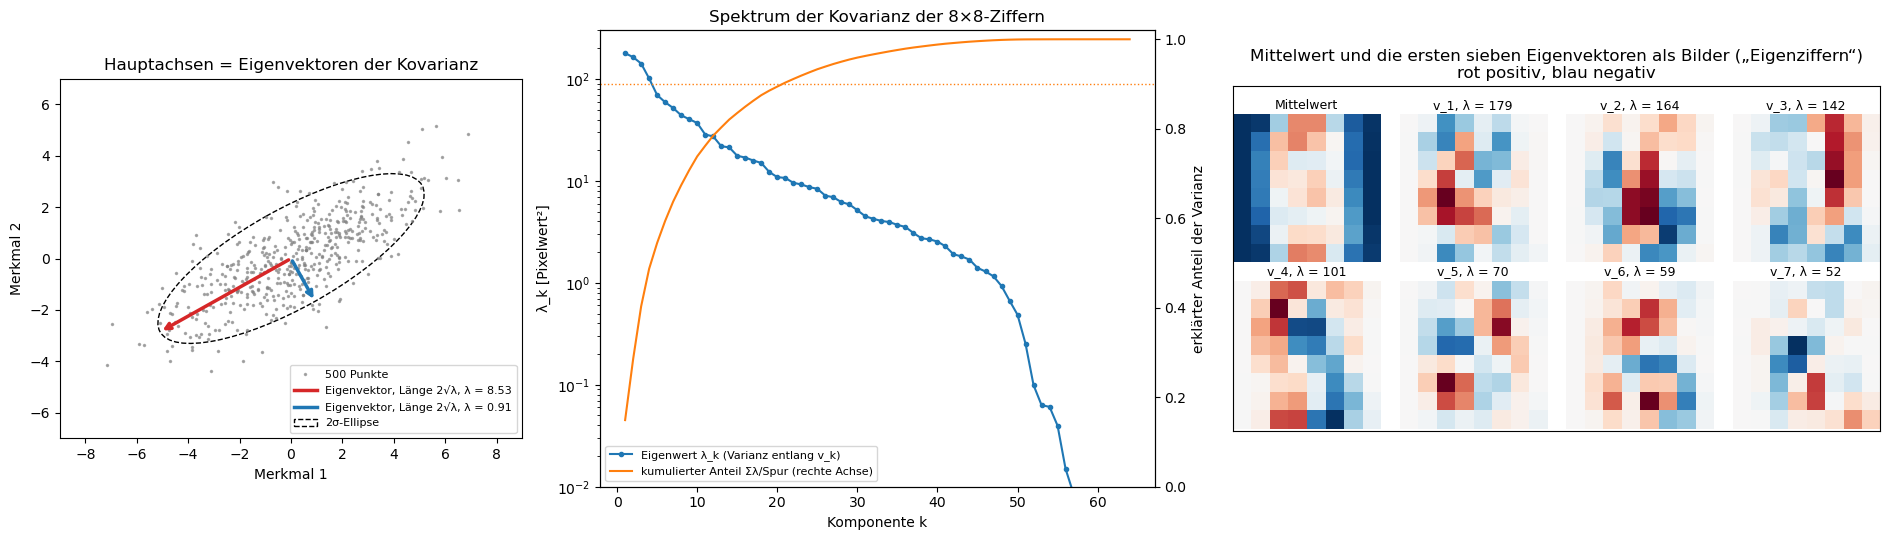

In [6]:
winkel5 = np.radians(30)
R5 = np.array([[np.cos(winkel5), -np.sin(winkel5)], [np.sin(winkel5), np.cos(winkel5)]])
wolke = rng.multivariate_normal([0, 0], R5 @ np.diag([9.0, 1.0]) @ R5.T, size=500)
C5 = np.cov(wolke.T)
l5, V5 = np.linalg.eigh(C5)
print(f"Punktwolke: Kovarianz-Eigenwerte {np.round(l5[::-1], 3)} (wahr 9 und 1), "
      f"Hauptachse bei {np.degrees(np.arctan2(V5[1, 1], V5[0, 1])) % 180:.1f}° (wahr 30°)")

ziffern = load_digits().data                                              # 1797 Bilder, 8×8 = 64 Pixel, Werte 0…16
Xz = ziffern - ziffern.mean(axis=0)
Cz = Xz.T @ Xz / (len(Xz) - 1)
lz, Vz = np.linalg.eigh(Cz)
lz, Vz = lz[::-1], Vz[:, ::-1]
anteil = np.cumsum(lz) / lz.sum()
print(f"Ziffern: {Xz.shape[0]} Bilder mit {Xz.shape[1]} Pixeln; Spur der Kovarianz = Gesamtvarianz {lz.sum():.1f}")
for k in [2, 5, 10, 20, 30]:
    rekon = Xz @ Vz[:, :k] @ Vz[:, :k].T
    fehler = np.sum((Xz - rekon)**2) / (len(Xz) - 1)
    print(f"  k = {k:2d}: erklärter Anteil {anteil[k - 1]:.3f}, Rekonstruktionsfehler {fehler:9.4f}, "
          f"Summe der übrigen Eigenwerte {lz[k:].sum():9.4f}")
print(f"  Pixel, die in allen Bildern gleich sind (Varianz 0): {np.sum(Xz.std(axis=0) == 0)}")
print(f"  für 90 % der Varianz braucht man {np.searchsorted(anteil, 0.9) + 1} von 64 Komponenten")

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), gridspec_kw={"width_ratios": [1, 1.2, 1.4]})
ax = axes[0]
ax.plot(*wolke.T, ".", ms=3, color="0.5", alpha=0.6, label="500 Punkte")
for j, farbe in zip([1, 0], ["tab:red", "tab:blue"]):
    v = V5[:, j] * 2 * np.sqrt(l5[j])
    ax.annotate("", v, (0, 0), arrowprops=dict(arrowstyle="->", color=farbe, lw=2.5))
    ax.plot([], [], color=farbe, lw=2.5, label=f"Eigenvektor, Länge 2√λ, λ = {l5[j]:.2f}")
ax.add_patch(Ellipse((0, 0), 4 * np.sqrt(l5[1]), 4 * np.sqrt(l5[0]), angle=np.degrees(np.arctan2(V5[1, 1], V5[0, 1])),
                     fill=False, color="k", ls="--", label="2σ-Ellipse"))
ax.set_aspect("equal"); ax.set_xlim(-9, 9); ax.set_ylim(-7, 7); ax.legend(fontsize=8, loc="lower right")
ax.set_xlabel("Merkmal 1"); ax.set_ylabel("Merkmal 2"); ax.set_title("Hauptachsen = Eigenvektoren der Kovarianz")
ax = axes[1]
ax.semilogy(np.arange(1, 65), lz, "o-", ms=3, label="Eigenwert λ_k (Varianz entlang v_k)")
ax.set_ylim(1e-2, 300); ax.set_xlabel("Komponente k"); ax.set_ylabel("λ_k [Pixelwert²]")
ax2 = ax.twinx()
ax2.plot(np.arange(1, 65), anteil, color="tab:orange", label="kumulierter Anteil Σλ/Spur (rechte Achse)")
ax2.axhline(0.9, color="tab:orange", ls=":", lw=1)
ax2.set_ylabel("erklärter Anteil der Varianz"); ax2.set_ylim(0, 1.02)
h1, l1 = ax.get_legend_handles_labels(); h2, l2_ = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2_, loc="lower left", fontsize=8)
ax.set_title("Spektrum der Kovarianz der 8×8-Ziffern")
ax = axes[2]
kacheln = [ziffern.mean(axis=0).reshape(8, 8) / 8 - 1] + [Vz[:, k].reshape(8, 8) / np.abs(Vz[:, k]).max() for k in range(7)]
montage = np.full((17, 35), np.nan)
for i, kachel in enumerate(kacheln):
    montage[9 * (i // 4):9 * (i // 4) + 8, 9 * (i % 4):9 * (i % 4) + 8] = kachel
ax.imshow(montage, cmap="RdBu_r", vmin=-1, vmax=1)
for i, text in enumerate(["Mittelwert"] + [f"v_{k + 1}, λ = {lz[k]:.0f}" for k in range(7)]):
    ax.text(9 * (i % 4) + 3.5, 9 * (i // 4) - 0.8, text, ha="center", fontsize=9)
ax.set_xticks([]); ax.set_yticks([]); ax.set_ylim(16.6, -2)
ax.set_title("Mittelwert und die ersten sieben Eigenvektoren als Bilder („Eigenziffern“)\nrot positiv, blau negativ")
plt.tight_layout()
plt.show()

* Das **linke Bild** zeigt die Punktwolke mit den beiden Eigenvektoren der Stichproben-Kovarianz, jeweils mit der Länge $2\sqrt\lambda$ (zwei Standardabweichungen), und die 2σ-Ellipse. Die Eigenwerte 8.53 und 0.91 liegen nahe bei den wahren Varianzen 9 und 1, die Hauptachse bei 29.2° statt 30°; die Abweichungen sind das Rauschen einer Stichprobe von 500 Punkten.
* Das **mittlere Bild** zeigt die 64 Eigenwerte der Ziffern-Kovarianz (blau, logarithmisch) und den kumulierten Anteil (orange, rechte Achse). Die Eigenwerte fallen über mehr als drei Größenordnungen; die letzten drei sind null und liegen unter dem Bildrand, weil drei Randpixel in allen Bildern gleich sind. Die ersten 2 Komponenten erklären 28.5 % der Varianz, die ersten 10 schon 73.8 %, und für 90 % braucht man 21 von 64. Der Rekonstruktionsfehler mit $k = 2, 5, 10, 20, 30$ Komponenten ist 859.4, 547.0, 314.7, 127.1 und 49.2 (Pixelwert² pro Bild, summiert über die Pixel) und stimmt auf alle angezeigten Stellen mit der Summe der übrigen Eigenwerte überein, wie Eckart–Young sagt. Die Gesamtvarianz, die Spur, ist 1202.1.
* Das **rechte Bild** zeigt den Mittelwert und die ersten sieben Eigenvektoren als 8×8-Bilder (rot positiv, blau negativ, mit ihren Eigenwerten 179, 164, 142, …). Die Eigenvektoren sind keine Ziffern, sondern Kontrastmuster: Sie sagen, welche Pixel in den Bildern gemeinsam heller oder dunkler werden. Jedes Bild ist näherungsweise der Mittelwert plus wenige solche Muster mit passenden Gewichten.

##### *6. Spur und Determinante: was nicht vom Koordinatensystem abhängt*

Ändern sich Diagonaleinträge, Spur und Eigenwerte, wenn man dieselbe lineare Abbildung in einem anderen Koordinatensystem schreibt? Kann man die Eigenwerte aus Spuren gewinnen, ohne zu diagonalisieren? Vorher überlegen: Was ist $\mathrm{tr}(A^2)$, ausgedrückt durch die Eigenwerte?

Eine zufällige reelle 4×4-Matrix $A$ wird mit 300 zufälligen invertierbaren Matrizen $S$ in $SAS^{-1}$ umgerechnet; verglichen werden Diagonaleinträge, Spur und Eigenwerte. Dann werden aus den Spuren $\mathrm{tr}A, \dots, \mathrm{tr}A^4$ mit den Newton-Identitäten die Koeffizienten des charakteristischen Polynoms berechnet. Zum Schluss werden die Spektralmomente $\frac1n\mathrm{tr}A^k$ einer symmetrischen Zufallsmatrix (GOE, $n = 400$) nur mit Matrixprodukten bestimmt und mit dem Halbkreisgesetz verglichen.

**Hintergrund & Fachbegriffe:**
- **Ähnlichkeitstransformation:** $B = SAS^{-1}$ ist dieselbe Abbildung in der Basis aus den Spalten von $S^{-1}$. $B$ und $A$ haben dasselbe charakteristische Polynom, also dieselben Eigenwerte, aber im Allgemeinen andere Einträge.
- **Spur und Determinante:** $\mathrm{tr}A = \sum_ia_{ii} = \sum_k\lambda_k$ und $\det A = \prod_k\lambda_k$. Beide sind Koeffizienten des charakteristischen Polynoms und deshalb basisunabhängig; für die Spur folgt das auch direkt aus $\mathrm{tr}(XY) = \mathrm{tr}(YX)$.
- **Potenzsummen und Newton-Identitäten:** $p_k = \mathrm{tr}A^k = \sum_j\lambda_j^k$. Die Koeffizienten des charakteristischen Polynoms $\lambda^n - e_1\lambda^{n-1} + e_2\lambda^{n-2} - \dots$ (die elementarsymmetrischen Funktionen der Eigenwerte) folgen rekursiv aus $ke_k = \sum_{i=1}^k(-1)^{i-1}e_{k-i}p_i$. Die ersten $n$ Spuren legen also alle Eigenwerte fest.
- **Spektralmomente und Halbkreisgesetz:** $\frac1n\mathrm{tr}A^k$ ist das $k$-te Moment der Verteilung der Eigenwerte. Für eine GOE-Matrix (symmetrisch, unabhängige Gauß-Einträge mit Varianz $1/n$ außerhalb der Diagonale) geht diese Verteilung für $n\to\infty$ gegen den Halbkreis auf $[-2, 2]$; seine geraden Momente sind die Catalan-Zahlen $1, 2, 5, 14, 42$, seine ungeraden null.

A: Eigenwerte 2.612, 0.7209, 0.115 + 0.6494i, 0.115 − 0.6494i
   Spur +3.562851 = Σλ +3.562851, det +0.818909 = Πλ +0.818909
300 Ähnlichkeitstransformationen S A S⁻¹: Diagonaleinträge zwischen -9.09 und +9.20, Spur schwankt um 4.9e-15, Eigenwerte um höchstens 2.5e-14
char. Polynom aus den Spuren tr(A^k): [ 1.       -3.562851  3.084247 -1.882355  0.818909]
char. Polynom direkt (np.poly):        [ 1.       -3.562851  3.084247 -1.882355  0.818909]
Momente tr(A^k)/n für k = 2, 4, 6, 8, 10: [ 0.999  1.996  4.986 13.958 41.895]  Catalan-Zahlen: [1, 2, 5, 14, 42]
ungerade Momente k = 1, 3, 5, 7, 9:       [-0.005 -0.03  -0.114 -0.404 -1.411]
  Abweichung tr(A^k)/n gegen Mittel von λ^k: höchstens 1.5e-13


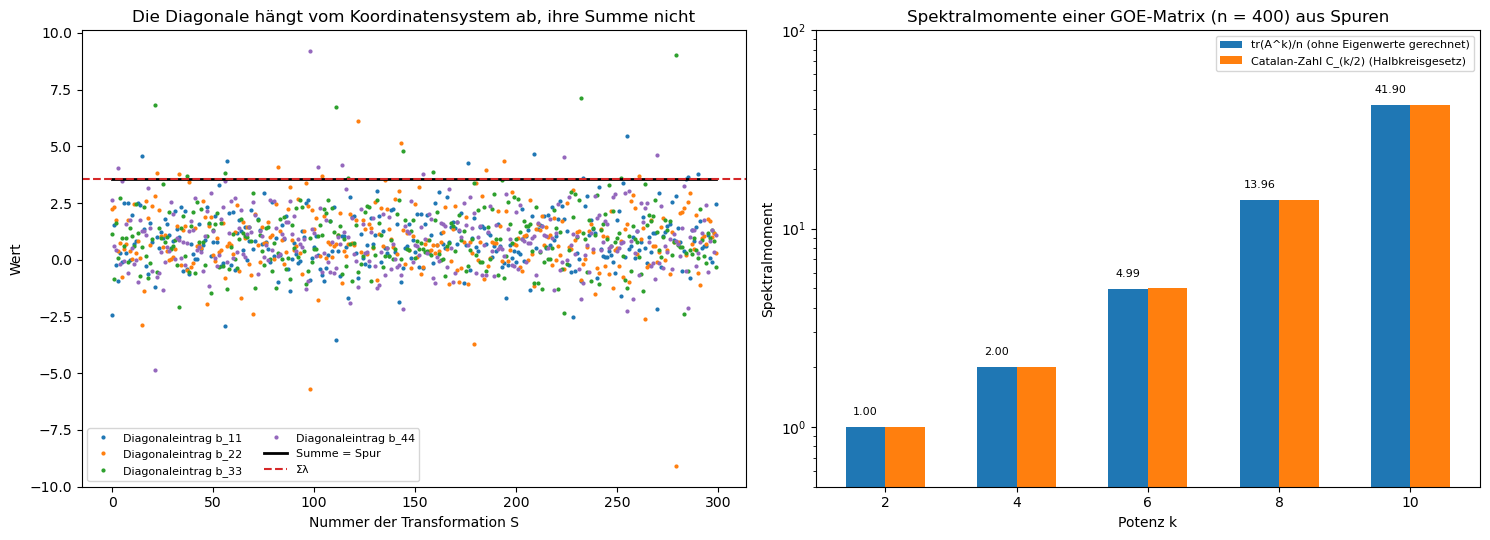

In [7]:
A6 = rng.standard_normal((4, 4))
ew6 = np.linalg.eigvals(A6)
print("A: Eigenwerte " + ", ".join(zahl(w, 4) for w in ew6) + f"\n   Spur {np.trace(A6):+.6f} = Σλ {np.sum(ew6).real:+.6f}, "
      f"det {np.linalg.det(A6):+.6f} = Πλ {np.prod(ew6).real:+.6f}")
diagonalen, spuren, ew_abw = [], [], 0.0
for _ in range(300):
    S = zufalls_orthogonal(4, rng) @ np.diag(np.exp(0.6 * rng.standard_normal(4))) @ zufalls_orthogonal(4, rng)
    B = S @ A6 @ np.linalg.inv(S)                                          # ähnliche Matrix: anderes Koordinatensystem
    diagonalen.append(np.diag(B)); spuren.append(np.trace(B))
    ew_abw = max(ew_abw, np.max(np.abs(np.sort_complex(np.linalg.eigvals(B)) - np.sort_complex(ew6))))
diagonalen = np.array(diagonalen)
print(f"300 Ähnlichkeitstransformationen S A S⁻¹: Diagonaleinträge zwischen {diagonalen.min():+.2f} und {diagonalen.max():+.2f},"
      f" Spur schwankt um {np.ptp(spuren):.1e}, Eigenwerte um höchstens {ew_abw:.1e}")

# Newton-Identitäten: die Koeffizienten des charakteristischen Polynoms aus den Spuren der Potenzen
p_k = [np.trace(np.linalg.matrix_power(A6, k)) for k in range(1, 5)]
e_k = [1.0]
for k in range(1, 5):
    e_k.append(sum((-1)**(i - 1) * e_k[k - i] * p_k[i - 1] for i in range(1, k + 1)) / k)
koeff_newton = [(-1)**k * e for k, e in enumerate(e_k)]
print("char. Polynom aus den Spuren tr(A^k):", np.round(koeff_newton, 6))
print("char. Polynom direkt (np.poly):       ", np.round(np.poly(A6), 6))

n6 = 400
G6 = rng.standard_normal((n6, n6))
A_goe = (G6 + G6.T) / np.sqrt(2 * n6)
momente_spur, momente_ew = [], []
ew_goe = np.linalg.eigvalsh(A_goe)
Ak = np.eye(n6)
for k in range(1, 11):
    Ak = Ak @ A_goe
    momente_spur.append(np.trace(Ak) / n6)
    momente_ew.append(np.mean(ew_goe**k))
catalan = [0 if k % 2 else sp.catalan(k // 2) for k in range(1, 11)]
print("Momente tr(A^k)/n für k = 2, 4, 6, 8, 10:", np.round(momente_spur[1::2], 3), " Catalan-Zahlen:", catalan[1::2])
print("ungerade Momente k = 1, 3, 5, 7, 9:      ", np.round(momente_spur[0::2], 3))
print(f"  Abweichung tr(A^k)/n gegen Mittel von λ^k: höchstens {np.max(np.abs(np.array(momente_spur) - momente_ew)):.1e}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
ax = axes[0]
for i, farbe in enumerate(["tab:blue", "tab:orange", "tab:green", "tab:purple"]):
    ax.plot(diagonalen[:, i], ".", ms=4, color=farbe, label=f"Diagonaleintrag b_{i + 1}{i + 1}")
ax.plot(diagonalen.sum(axis=1), "k-", lw=2, label="Summe = Spur")
ax.axhline(np.sum(ew6).real, color="tab:red", ls="--", label="Σλ")
ax.set_xlabel("Nummer der Transformation S"); ax.set_ylabel("Wert"); ax.legend(fontsize=8, ncol=2)
ax.set_title("Die Diagonale hängt vom Koordinatensystem ab, ihre Summe nicht")
ax = axes[1]
kk = np.arange(2, 11, 2)
ax.bar(kk - 0.3, momente_spur[1::2], width=0.6, label="tr(A^k)/n (ohne Eigenwerte gerechnet)")
ax.bar(kk + 0.3, [float(c) for c in catalan[1::2]], width=0.6, label="Catalan-Zahl C_(k/2) (Halbkreisgesetz)")
for k, m in zip(kk, momente_spur[1::2]):
    ax.text(k - 0.3, m * 1.15, f"{m:.2f}", ha="center", fontsize=8)
ax.set_yscale("log"); ax.set_ylim(0.5, 100); ax.set_xticks(kk)
ax.set_xlabel("Potenz k"); ax.set_ylabel("Spektralmoment"); ax.legend(fontsize=8)
ax.set_title("Spektralmomente einer GOE-Matrix (n = 400) aus Spuren")
plt.tight_layout()
plt.show()

* Das **linke Bild** zeigt die vier Diagonaleinträge von $SAS^{-1}$ für 300 verschiedene $S$. Sie streuen zwischen −9.09 und +9.20 und haben einzeln nichts mit den Eigenwerten $2.612$, $0.721$, $0.115\pm0.649i$ zu tun. Ihre Summe (schwarz) ist aber jedes Mal $3.562851 = \sum\lambda$ (rot gestrichelt), mit Schwankungen von $5\cdot10^{-15}$, und die Eigenwerte ändern sich um höchstens $2.5\cdot10^{-14}$; beides ist Rundung. Die Determinante $0.818909$ ist das Produkt der Eigenwerte.
* Die Newton-Identitäten geben aus den vier Spuren das Polynom $\lambda^4 - 3.562851\lambda^3 + 3.084247\lambda^2 - 1.882355\lambda + 0.818909$, auf sechs Stellen dasselbe wie `np.poly`. Die Spuren der Potenzen enthalten also dieselbe Information wie die Eigenwerte. Ausrechnen sollte man Eigenwerte so nicht (Nullstellen von Polynomen sind numerisch empfindlich, Theorie Abschnitt 8), aber so misst man Eigenwertverteilungen, wenn nur Produkte $A\mathbf v$ verfügbar sind, und so misst man in der Quanteninformation die Reinheit $\mathrm{tr}\rho^2$ und Rényi-Entropien.
* Das **rechte Bild** vergleicht die geraden Momente $\frac1n\mathrm{tr}A^k$ der GOE-Matrix, berechnet ohne Eigenwerte, mit den Catalan-Zahlen: 0.999, 1.996, 4.986, 13.958, 41.895 gegen 1, 2, 5, 14, 42. Die Abweichungen von einigen Promille sind Effekte der endlichen Größe. Die ungeraden Momente sind −0.005, −0.03, −0.11, −0.40, −1.41: klein gegen die geraden, aber mit $k$ wachsend, weil hohe Potenzen die wenigen Eigenwerte am Rand bei ±2 stark gewichten und deren zufällige Lage dann durchschlägt. Momente aus Spuren und aus Eigenwerten stimmen auf $1.5\cdot10^{-13}$ überein.

##### *7. Was die Diagonale über die Eigenwerte verrät: Gershgorin und Schur–Horn*

Wo können die Eigenwerte einer Matrix liegen, wenn man nur ihre Diagonale und die Größe der Nebendiagonaleinträge kennt? Und welche Diagonalen sind bei festen Eigenwerten überhaupt möglich? Vorher überlegen: Kann eine hermitesche Matrix mit den Eigenwerten 1, 2, 4 die Diagonale (3, 3, 1) haben? Und (4.5, 1.5, 1)?

Teil 1: eine nicht symmetrische 5×5-Matrix mit der Diagonale $(-6, -2, 1, 4, 8)$ und kleineren Nebendiagonaleinträgen; nur $a_{34} = 2$ und $a_{43} = -2$ koppeln die Zustände 3 und 4 stark, mit entgegengesetztem Vorzeichen. Gezeichnet werden die Gershgorin-Kreise, die Eigenwerte und die Wege der Eigenwerte, wenn man die Nebendiagonale von null auf ihren vollen Wert hochdreht ($D + sE$, $s = 0\dots1$). Teil 2: 6000 Haar-zufällige unitäre $U$; für jedes wird die Diagonale von $U\,\mathrm{diag}(1, 2, 4)\,U^\dagger$ berechnet und in der Ebene $d_1 + d_2 + d_3 = 7$ eingezeichnet.

**Hintergrund & Fachbegriffe:**
- **Gershgorin-Kreise:** $D_i = \lbrace z\in\mathbb C:\vert z - a_{ii}\vert\le R_i\rbrace$ mit $R_i = \sum_{j\neq i}\vert a_{ij}\vert$. Jeder Eigenwert liegt in mindestens einem Kreis. Bilden $k$ Kreise eine zusammenhängende Gruppe, die die übrigen nicht berührt, liegen darin genau $k$ Eigenwerte. Grund: Ist $A\mathbf v = \lambda\mathbf v$ und $v_i$ der betragsgrößte Eintrag von $\mathbf v$, dann ist $(\lambda - a_{ii})v_i = \sum_{j\neq i}a_{ij}v_j$, also $\vert\lambda - a_{ii}\vert\le R_i$.
- **Diagonaldominanz:** $\vert a_{ii}\vert>R_i$ für alle $i$. Dann liegt 0 in keinem Kreis, und $A$ ist invertierbar.
- **Majorisierung:** $\mathbf d$ wird von $\boldsymbol\lambda$ majorisiert, wenn nach absteigender Sortierung jede Teilsumme $d_1 + \dots + d_k\le\lambda_1 + \dots + \lambda_k$ ist und die Gesamtsummen gleich sind. Geometrisch liegt $\mathbf d$ dann in der konvexen Hülle aller Permutationen von $\boldsymbol\lambda$, in drei Dimensionen einem Sechseck (**Permutaeder**).
- **Satz von Schur–Horn:** Die Diagonale einer hermiteschen Matrix wird von ihren Eigenwerten majorisiert (Schur 1923), und jede majorisierte Diagonale kommt vor (Horn 1954). Insbesondere liegt jeder Diagonaleintrag zwischen $\lambda_{\min}$ und $\lambda_{\max}$.
- **Haar-Maß:** die Gleichverteilung auf der Gruppe der unitären Matrizen; „zufällige Basis ohne bevorzugte Richtung“.

Diagonale: [-6. -2.  1.  4.  8.]  Gershgorin-Radien: [1.  1.6 2.9 2.8 0.8]
Eigenwerte: -6.11, -1.82, 2.46 − 1.26i, 2.46 + 1.26i, 8
  Kreis 1 (Mitte -6, Radius 1.00) enthält 1 Eigenwert(e)
  Kreis 2 (Mitte -2, Radius 1.60) enthält 1 Eigenwert(e)
  Kreis 3 (Mitte +1, Radius 2.90) enthält 3 Eigenwert(e)
  Kreis 4 (Mitte +4, Radius 2.80) enthält 2 Eigenwert(e)
  Kreis 5 (Mitte +8, Radius 0.80) enthält 1 Eigenwert(e)
Schur–Horn: 6000 Diagonalen von UΛU† mit Λ = diag(1, 2, 4): Summe 7.000000000000 … 7.000000000000; größter Eintrag ≤ 4: True, Summe der zwei größten ≤ 6: True
  Anteil der Punkte im inneren Sechseck halber Größe (ein Viertel der Fläche): 0.492


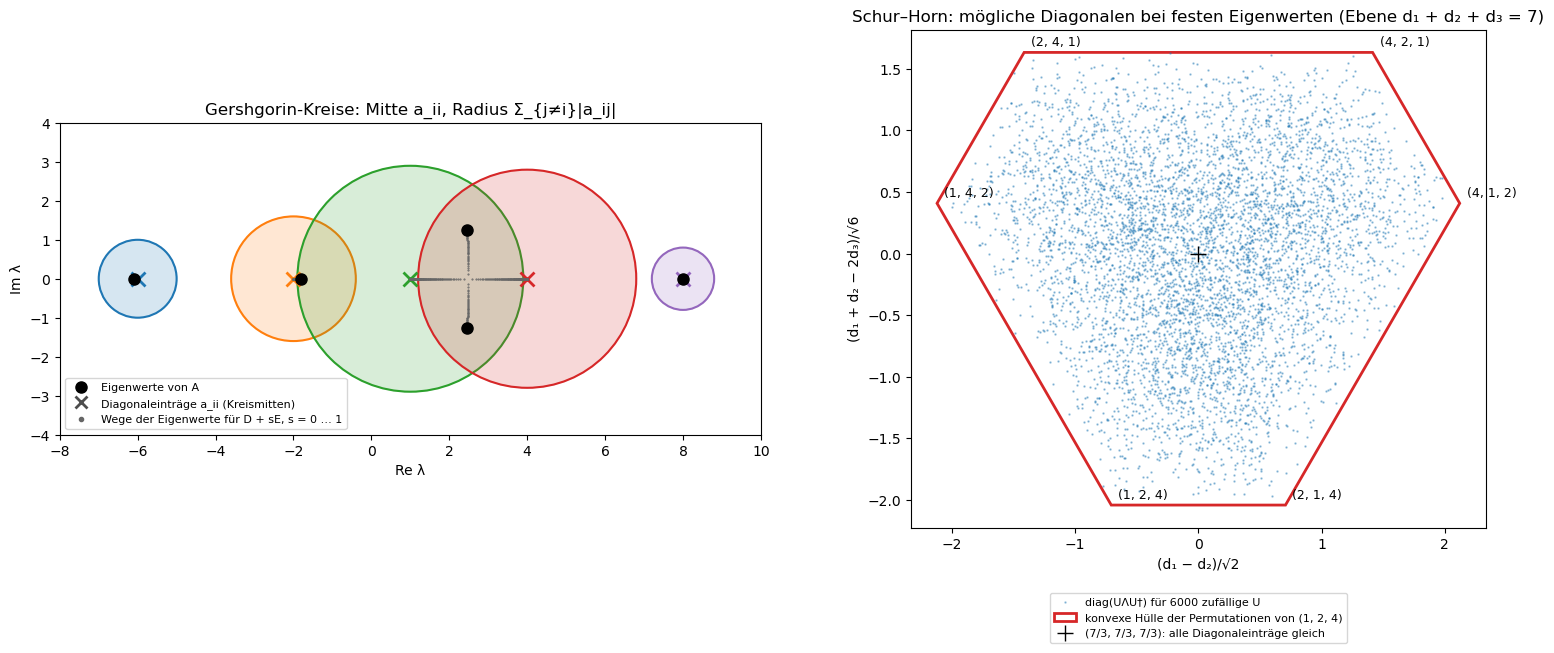

In [8]:
diag7 = np.array([-6.0, -2.0, 1.0, 4.0, 8.0])
E7 = np.array([[0.0, 0.5, 0.3, 0.0, 0.2],
               [0.8, 0.0, 0.6, 0.2, 0.0],
               [0.2, -0.4, 0.0, 2.0, 0.3],
               [0.0, 0.3, -2.0, 0.0, 0.5],
               [0.1, 0.0, 0.4, -0.3, 0.0]])                                # Nebendiagonale; a_34 = −a_43 koppelt 3 und 4 stark
A7 = np.diag(diag7) + E7
radien = np.sum(np.abs(E7), axis=1)
ew7 = np.linalg.eigvals(A7)
print("Diagonale:", diag7, " Gershgorin-Radien:", np.round(radien, 3))
print("Eigenwerte:", ", ".join(zahl(w) for w in np.sort_complex(ew7)))
for i in range(5):
    drin = np.abs(ew7 - diag7[i]) <= radien[i] + 1e-12
    print(f"  Kreis {i + 1} (Mitte {diag7[i]:+.0f}, Radius {radien[i]:.2f}) enthält {drin.sum()} Eigenwert(e)")
pfade = np.array([np.linalg.eigvals(np.diag(diag7) + s * E7) for s in np.linspace(0, 1, 201)])

ew_sh = np.array([1.0, 2.0, 4.0])
punkte = np.array([np.real(np.diag(U @ np.diag(ew_sh) @ U.conj().T)) for U in (zufalls_unitaer(3, rng) for _ in range(6000))])
schluss = np.sort(punkte, axis=1)[:, ::-1]
print(f"Schur–Horn: 6000 Diagonalen von UΛU† mit Λ = diag(1, 2, 4): Summe {punkte.sum(1).min():.12f} … {punkte.sum(1).max():.12f};"
      f" größter Eintrag ≤ 4: {np.all(schluss[:, 0] <= 4 + 1e-12)}, Summe der zwei größten ≤ 6: {np.all(schluss[:, :2].sum(1) <= 6 + 1e-12)}")
ebene = lambda P: np.array([(P[..., 0] - P[..., 1]) / np.sqrt(2), (P[..., 0] + P[..., 1] - 2 * P[..., 2]) / np.sqrt(6)])
# Dichte: Anteil der Punkte im um die Mitte auf halbe Größe verkleinerten Sechseck (ein Viertel der Fläche)
mitte = np.array([7 / 3] * 3)
innen = np.all(np.sort(mitte + 2 * (punkte - mitte), axis=1)[:, ::-1].cumsum(axis=1)[:, :2] <= np.array([4, 6]) + 1e-12, axis=1)
print(f"  Anteil der Punkte im inneren Sechseck halber Größe (ein Viertel der Fläche): {innen.mean():.3f}")
ecken = np.array(list(permutations(ew_sh)))
ecken = ecken[np.argsort(np.arctan2(*ebene(ecken)[::-1]))]

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
ax = axes[0]
for i in range(5):
    ax.add_patch(Circle((diag7[i], 0), radien[i], color=f"C{i}", alpha=0.18))
    ax.add_patch(Circle((diag7[i], 0), radien[i], color=f"C{i}", fill=False, lw=1.5))
    ax.plot(diag7[i], 0, "x", color=f"C{i}", ms=10, mew=2)
ax.plot(pfade.real.ravel(), pfade.imag.ravel(), ".", ms=1, color="0.4")
ax.plot(ew7.real, ew7.imag, "o", color="k", ms=8, label="Eigenwerte von A")
ax.plot([], [], "x", color="0.3", ms=8, mew=2, label="Diagonaleinträge a_ii (Kreismitten)")
ax.plot([], [], ".", color="0.4", label="Wege der Eigenwerte für D + sE, s = 0 … 1")
ax.set_aspect("equal"); ax.set_xlim(-8, 10); ax.set_ylim(-4, 4); ax.legend(fontsize=8, loc="lower left")
ax.set_xlabel("Re λ"); ax.set_ylabel("Im λ"); ax.set_title("Gershgorin-Kreise: Mitte a_ii, Radius Σ_{j≠i}|a_ij|")
ax = axes[1]
ax.plot(*ebene(punkte), ".", ms=1.5, alpha=0.4, color="tab:blue", label="diag(UΛU†) für 6000 zufällige U")
ax.add_patch(Polygon(ebene(ecken).T, closed=True, fill=False, color="tab:red", lw=2, label="konvexe Hülle der Permutationen von (1, 2, 4)"))
for e in ecken:
    ax.annotate(str(tuple(int(v) for v in e)), ebene(e), xytext=(5, 5), textcoords="offset points", fontsize=9)
ax.plot(*ebene(np.array([7 / 3] * 3)), "k+", ms=12, label="(7/3, 7/3, 7/3): alle Diagonaleinträge gleich")
ax.set_aspect("equal"); ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.set_xlabel("(d₁ − d₂)/√2"); ax.set_ylabel("(d₁ + d₂ − 2d₃)/√6")
ax.set_title("Schur–Horn: mögliche Diagonalen bei festen Eigenwerten (Ebene d₁ + d₂ + d₃ = 7)")
plt.tight_layout()
plt.show()

* Das **linke Bild** zeigt die fünf Gershgorin-Kreise (Mittelpunkte × bei den Diagonaleinträgen, Radien 1.0, 1.6, 2.9, 2.8, 0.8) und die Eigenwerte (schwarz): −6.11, −1.82, $2.46\pm1.26i$ und 8.00. Die Kreise um −6 und um 8 berühren keinen anderen und enthalten je genau einen Eigenwert, nahe an ihrem Diagonaleintrag. Die drei Kreise um −2, 1 und 4 überlappen und enthalten zusammen genau drei Eigenwerte. Welcher Eigenwert zu welchem Kreis gehört, ist dann nicht mehr festgelegt: Das komplexe Paar liegt in den Kreisen um 1 und 4, aber kein Eigenwert liegt nahe bei 1 oder 4.
* Die **grauen Wege** zeigen, wie die Eigenwerte von $D + sE$ beim Hochdrehen der Nebendiagonale von den Diagonaleinträgen ($s = 0$) wegwandern. Die beiden, die bei 1 und 4 starten, laufen aufeinander zu, treffen sich auf der reellen Achse bei etwa 2.5 und laufen dann als komplexes Paar senkrecht auseinander. Grund ist $a_{43} = -a_{34}$: Der 2×2-Block $\begin{pmatrix}1 & 2s\\ -2s & 4\end{pmatrix}$ hat die Eigenwerte $2.5\pm\sqrt{2.25 - 4s^2}$, die ab $s = 0.75$ komplex werden. Eine antisymmetrische Kopplung wirkt wie eine Drehung (Experiment 1); eine symmetrische hätte die beiden Eigenwerte auseinandergeschoben (Experiment 8).
* Das **rechte Bild** zeigt die Diagonalen von $U\,\mathrm{diag}(1, 2, 4)\,U^\dagger$ in der Ebene $d_1 + d_2 + d_3 = 7$. Alle 6000 Punkte liegen im roten Sechseck, dessen Ecken die sechs Permutationen von $(1, 2, 4)$ sind: Jede Diagonale wird majorisiert (größter Eintrag ≤ 4, Summe der zwei größten ≤ 6, Summe aller drei 7.000000000000). Die Punkte füllen das Sechseck, aber nicht gleichmäßig: Im um die Mitte auf halbe Größe verkleinerten Sechseck, einem Viertel der Fläche, liegen 49 % der Punkte. Eine typische zufällige Basis mischt die Eigenwerte also gut, und die Diagonale liegt nahe am Mittelwert $(7/3, 7/3, 7/3)$. Die Ecken erreicht nur eine schon diagonale Matrix: Ist die Diagonale eine Permutation der Eigenwerte, ist $\sum_id_i^2 = \sum_k\lambda_k^2 = \Vert A\Vert_F^2$, und für die Nebendiagonale bleibt nichts übrig.

##### *8. Was die Nebendiagonale bewirkt: Kopplung, vermiedene Kreuzung, Störungstheorie*

Was passiert mit zwei Eigenwerten, wenn man zwei Zustände mit den Energien $\pm\varepsilon$ über einen Nebendiagonaleintrag $g$ koppelt, und wie gut ist die Diagonale allein als Näherung der Eigenwerte? Vorher überlegen: Können sich die Eigenwerte bei $g\neq0$ noch kreuzen, wenn man $\varepsilon$ durch null fährt?

Teil 1: $H = \begin{pmatrix}\varepsilon & g\\ g & -\varepsilon\end{pmatrix}$ für $\varepsilon\in[-2, 2]$ und $g = 0, 0.1, 0.3, 0.6$; dazu das Gewicht des Basiszustands $\vert0\rangle$ im unteren Eigenvektor und eine Prüfung der Hellmann–Feynman-Formel. Teil 2: eine 6×6-Matrix aus der Diagonale $D = (0, 1, 2.5, 3.2, 4.5, 6)$ und einer festen zufälligen symmetrischen Kopplung $gW$ ohne Diagonale; der Fehler der Diagonale allein und mit der Korrektur zweiter Ordnung wird für $g$ von $10^{-3}$ bis 0.3 gemessen.

**Hintergrund & Fachbegriffe:**
- **Vermiedene Kreuzung (avoided crossing):** Die Eigenwerte von $H$ sind $\pm\sqrt{\varepsilon^2 + g^2}$. Ohne Kopplung kreuzen sich die Geraden $\pm\varepsilon$ bei $\varepsilon = 0$; mit Kopplung bleibt dort die Lücke $2g$. Nach von Neumann und Wigner kreuzen sich Eigenwerte einer reellen symmetrischen Matrix, die von einem einzigen Parameter abhängt, im Allgemeinen nicht.
- **Mischung der Eigenvektoren:** Weit weg von $\varepsilon = 0$ ist jeder Eigenvektor fast ein Basiszustand; bei $\varepsilon = 0$ sind beide halb-halb gemischt. Der Mischungswinkel erfüllt $\tan2\theta = g/\varepsilon$, der Übergang hat also die Breite $\sim g$.
- **Störungstheorie:** Für $A = D + gW$ mit verschiedenen $d_i$ ist $\lambda_i = d_i + gW_{ii} + g^2\sum_{j\neq i}\frac{\vert W_{ij}\vert^2}{d_i - d_j} + O(g^3)$. Der Term zweiter Ordnung schiebt jedes Niveau von den anderen weg (Niveauabstoßung), am stärksten von nahen Nachbarn.
- **Hellmann–Feynman:** Hängt eine hermitesche Matrix von einem Parameter $p$ ab, ist die Ableitung eines nicht entarteten Eigenwerts $d\lambda/dp = \mathbf v^\dagger(\partial A/\partial p)\mathbf v$ mit dem normierten Eigenvektor $\mathbf v$. In der Physik gibt das Kräfte als Erwartungswerte, im maschinellen Lernen Gradienten von Eigenwerten.
- **Adiabatischer Übergang (Landau–Zener):** Fährt man $\varepsilon$ langsam genug durch, bleibt das System im unteren Eigenzustand und wird dabei von $\vert0\rangle$ nach $\vert1\rangle$ überführt. „Langsam“ heißt hier: $\varepsilon$ ändert sich pro Zeiteinheit viel weniger als $g^2$ ($\hbar = 1$).

g = 0.1: kleinster Abstand der beiden Niveaus 0.2000 (= 2g)
g = 0.3: kleinster Abstand der beiden Niveaus 0.6000 (= 2g)
g = 0.6: kleinster Abstand der beiden Niveaus 1.2000 (= 2g)
Hellmann–Feynman bei ε = 0.4, g = 0.3: dλ₋/dε = -0.80000000, ⟨v₋|σ_z|v₋⟩ = -0.80000000, exakt −ε/√(ε² + g²) = -0.80000000
6×6: Fehler der Diagonale allein ∝ g^1.99, mit zweiter Ordnung Σ|g W_ij|²/(d_i − d_j) ∝ g^3.01


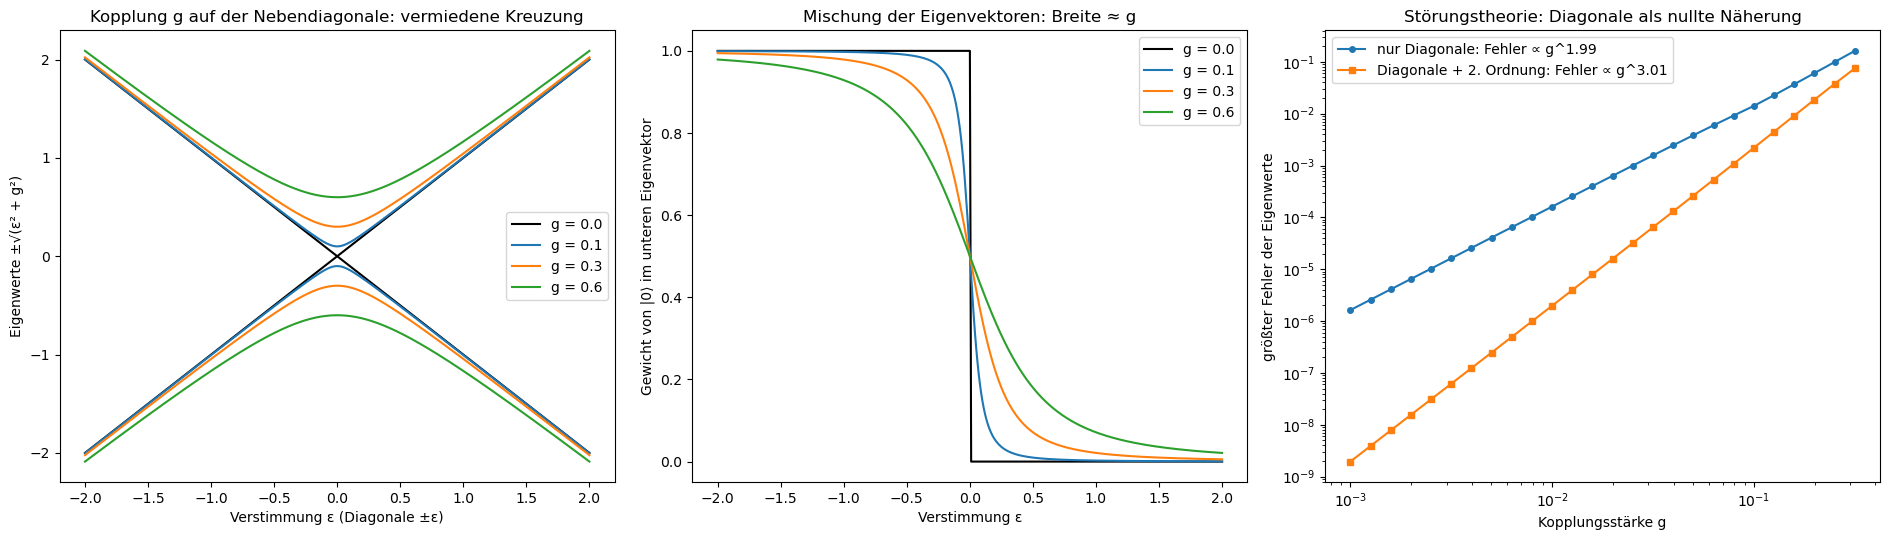

In [9]:
eps8 = np.linspace(-2, 2, 401)
gs8 = [0.0, 0.1, 0.3, 0.6]
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
for g, farbe in zip(gs8, ["k", "tab:blue", "tab:orange", "tab:green"]):
    werte, gewicht = [], []
    for e in eps8:
        w, v = np.linalg.eigh(np.array([[e, g], [g, -e]]))
        werte.append(w); gewicht.append(v[0, 0]**2)
    werte = np.array(werte)
    axes[0].plot(eps8, werte[:, 0], color=farbe, label=f"g = {g}")
    axes[0].plot(eps8, werte[:, 1], color=farbe)
    axes[1].plot(eps8, gewicht, color=farbe, label=f"g = {g}")
    if g > 0:
        print(f"g = {g}: kleinster Abstand der beiden Niveaus {np.min(werte[:, 1] - werte[:, 0]):.4f} (= 2g)")
# Hellmann–Feynman: dλ/dε = ⟨v|∂H/∂ε|v⟩ = ⟨v|σ_z|v⟩
e0, g0, h8 = 0.4, 0.3, 1e-6
w_p = np.linalg.eigvalsh(np.array([[e0 + h8, g0], [g0, -e0 - h8]]))[0]
w_m = np.linalg.eigvalsh(np.array([[e0 - h8, g0], [g0, -e0 + h8]]))[0]
_, v8 = np.linalg.eigh(np.array([[e0, g0], [g0, -e0]]))
print(f"Hellmann–Feynman bei ε = 0.4, g = 0.3: dλ₋/dε = {(w_p - w_m) / (2 * h8):+.8f}, ⟨v₋|σ_z|v₋⟩ = {v8[:, 0] @ np.diag([1, -1]) @ v8[:, 0]:+.8f},"
      f" exakt −ε/√(ε² + g²) = {-e0 / np.hypot(e0, g0):+.8f}")

# Störungstheorie für eine 6×6-Matrix: Diagonale D plus Kopplung g·W
D8 = np.array([0.0, 1.0, 2.5, 3.2, 4.5, 6.0])
W8 = rng.standard_normal((6, 6)); W8 = (W8 + W8.T) / 2; np.fill_diagonal(W8, 0)
g_werte = np.logspace(-3, -0.5, 26)
f0, f2 = [], []
for g in g_werte:
    exakt = np.linalg.eigvalsh(np.diag(D8) + g * W8)
    zweite = D8 + np.array([sum((g * W8[i, j])**2 / (D8[i] - D8[j]) for j in range(6) if j != i) for i in range(6)])
    f0.append(np.max(np.abs(exakt - D8))); f2.append(np.max(np.abs(exakt - np.sort(zweite))))
st0 = np.polyfit(np.log(g_werte[:15]), np.log(f0[:15]), 1)[0]
st2 = np.polyfit(np.log(g_werte[:15]), np.log(f2[:15]), 1)[0]
print(f"6×6: Fehler der Diagonale allein ∝ g^{st0:.2f}, mit zweiter Ordnung Σ|g W_ij|²/(d_i − d_j) ∝ g^{st2:.2f}")
axes[2].loglog(g_werte, f0, "o-", ms=4, label=f"nur Diagonale: Fehler ∝ g^{st0:.2f}")
axes[2].loglog(g_werte, f2, "s-", ms=4, label=f"Diagonale + 2. Ordnung: Fehler ∝ g^{st2:.2f}")
axes[0].set_xlabel("Verstimmung ε (Diagonale ±ε)"); axes[0].set_ylabel("Eigenwerte ±√(ε² + g²)")
axes[0].set_title("Kopplung g auf der Nebendiagonale: vermiedene Kreuzung"); axes[0].legend()
axes[1].set_xlabel("Verstimmung ε"); axes[1].set_ylabel("Gewicht von |0⟩ im unteren Eigenvektor")
axes[1].set_title("Mischung der Eigenvektoren: Breite ≈ g"); axes[1].legend()
axes[2].set_xlabel("Kopplungsstärke g"); axes[2].set_ylabel("größter Fehler der Eigenwerte")
axes[2].set_title("Störungstheorie: Diagonale als nullte Näherung"); axes[2].legend()
plt.tight_layout()
plt.show()

* Das **linke Bild** zeigt die beiden Eigenwerte gegen die Verstimmung $\varepsilon$. Ohne Kopplung (schwarz) kreuzen sich die Geraden $\pm\varepsilon$. Mit Kopplung werden daraus Hyperbeln, die sich nicht mehr berühren; der kleinste Abstand ist 0.2, 0.6 und 1.2, genau $2g$. Weit weg von der Kreuzung ist die Kopplung kaum zu sehen; dort sind die Eigenwerte fast die Diagonaleinträge.
* Das **mittlere Bild** zeigt, wie viel vom Basiszustand $\vert0\rangle$ im unteren Eigenvektor steckt. Ohne Kopplung springt das Gewicht bei $\varepsilon = 0$ von 1 auf 0: Der untere Zustand ist links $\vert0\rangle$ und rechts $\vert1\rangle$. Mit Kopplung wird daraus ein glatter Übergang, umso breiter, je größer $g$; bei $\varepsilon = 0$ sind beide Basiszustände genau zur Hälfte beteiligt. Hellmann–Feynman stimmt: Bei $\varepsilon = 0.4$, $g = 0.3$ geben der Differenzenquotient, $\langle v_-\vert\sigma_z\vert v_-\rangle$ und die Formel $-\varepsilon/\sqrt{\varepsilon^2 + g^2}$ dieselbe Steigung $-0.8$, auf acht Stellen.
* Das **rechte Bild** zeigt für die 6×6-Matrix den größten Fehler der Eigenwerte gegen die Kopplungsstärke, doppelt logarithmisch. Nimmt man nur die Diagonale, ist der Fehler proportional zu $g^{1.99}$: Die erste Ordnung $gW_{ii}$ ist null, weil $W$ keine Diagonale hat, also beginnt der Fehler bei der zweiten. Mit der Korrektur zweiter Ordnung fällt er wie $g^{3.01}$ und ist bei $g = 0.01$ um mehr als zwei Größenordnungen kleiner. Die Störungsreihe funktioniert, solange $g\vert W_{ij}\vert$ klein gegen die Abstände $\vert d_i - d_j\vert$ ist; der kleinste Abstand ist hier 0.7 (zwischen 2.5 und 3.2).

##### *9. Jacobi-Verfahren: die Nebendiagonale wegdrehen*

Kann man eine symmetrische Matrix diagonalisieren, indem man ihre Nebendiagonaleinträge einen nach dem anderen mit Drehungen beseitigt, obwohl jede Drehung die schon beseitigten wieder etwas auffüllt? Vorher überlegen: Was passiert mit der Quadratsumme aller Einträge bei einer Drehung?

Eine zufällige symmetrische 8×8-Matrix wird in Sweeps bearbeitet: In jedem Sweep wird für jedes der 28 Paare $(p, q)$ eine Drehung $J$ in der $(p, q)$-Ebene gewählt, die $a_{pq}$ zu null macht, und $A\to J^TAJ$ gesetzt. Gemessen wird $\mathrm{off}(A)$ nach jeder Drehung; die Diagonale am Ende wird mit `numpy.linalg.eigvalsh` verglichen, das Produkt aller Drehungen mit den Eigenvektoren.

**Hintergrund & Fachbegriffe:**
- **Jacobi-Drehung (Givens-Drehung):** eine Drehung, die nur die Koordinaten $p$ und $q$ mischt. Auf dem 2×2-Block $\begin{pmatrix}a_{pp} & a_{pq}\\ a_{pq} & a_{qq}\end{pmatrix}$ ist sie genau dessen Diagonalisierung; der Winkel folgt aus $\tan2\theta = 2a_{pq}/(a_{qq} - a_{pp})$.
- **Nebendiagonalnorm:** $\mathrm{off}(A) = \big(\sum_{i\neq j}a_{ij}^2\big)^{1/2}$. Eine Drehung ändert die Frobenius-Norm $\Vert A\Vert_F^2 = \sum_{ij}a_{ij}^2 = \sum_k\lambda_k^2$ nicht. Sie verschiebt aber $2a_{pq}^2$ aus der Nebendiagonale in die Diagonale; $\mathrm{off}(A)^2$ sinkt also bei jeder Drehung um genau $2a_{pq}^2$.
- **Sweep und Konvergenz:** Die anderen Einträge in den Zeilen und Spalten $p$ und $q$ werden gemischt, ihre Quadratsumme bleibt aber gleich; deshalb kann $\mathrm{off}(A)$ nur fallen. Nach einigen Sweeps konvergiert das Verfahren quadratisch.
- **Eigenvektoren:** Das Produkt $V = J_1J_2\cdots$ aller Drehungen erfüllt $V^TAV\to\Lambda$; seine Spalten sind die Eigenvektoren.

nach Sweep 1: off(A) = 3.09e+00
nach Sweep 2: off(A) = 6.54e-01
nach Sweep 3: off(A) = 2.68e-02
nach Sweep 4: off(A) = 7.52e-05
nach Sweep 5: off(A) = 1.73e-10
nach Sweep 6: off(A) = 5.43e-16
nach 3 Sweeps liegen die Nebendiagonaleinträge zwischen 5e-19 und 1e-02
Frobenius-Norm² bleibt 36.201891 (Schwankung 6.4e-14); am Ende Σ a_ii² = 36.201891
Diagonale nach Jacobi (sortiert): [-4.56255655 -1.7229343  -1.16719534 -0.88461212  0.23593929  0.60914957
  1.58638522  2.70707104]
np.linalg.eigvalsh:               [-4.56255655 -1.7229343  -1.16719534 -0.88461212  0.23593929  0.60914957
  1.58638522  2.70707104]
‖A V − V diag‖ = 6.2e-15: die Spalten der aufmultiplizierten Drehungen sind die Eigenvektoren


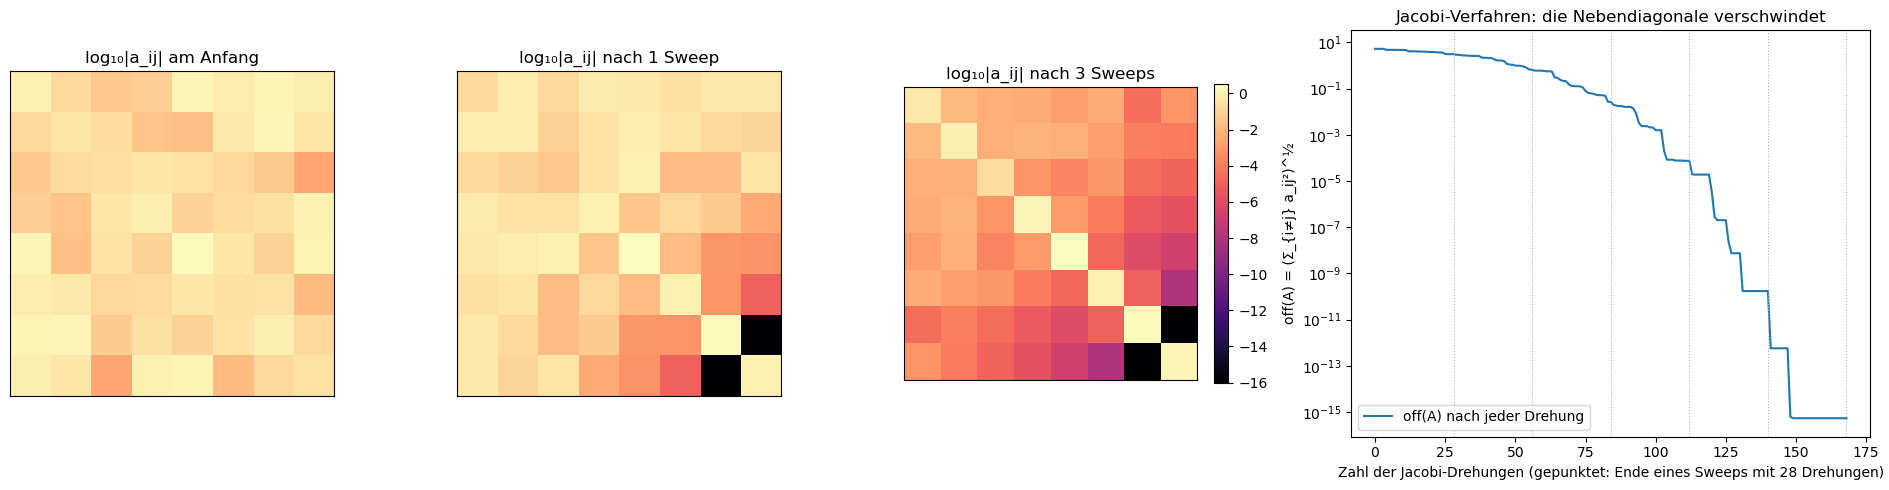

In [10]:
def jacobi_rotation(A, p, q):
    """Eine Jacobi-Drehung in der (p, q)-Ebene, die a_pq zu null macht. Rückgabe: Jᵀ A J und J."""
    if A[p, q] == 0:
        return A, np.eye(len(A))
    tau = (A[q, q] - A[p, p]) / (2 * A[p, q])
    t = np.sign(tau) / (abs(tau) + np.sqrt(1 + tau**2)) if tau != 0 else 1.0
    c = 1 / np.sqrt(1 + t**2); s = t * c
    J = np.eye(len(A)); J[p, p] = J[q, q] = c; J[p, q] = s; J[q, p] = -s
    return J.T @ A @ J, J


n9 = 8
A9 = rng.standard_normal((n9, n9)); A9 = (A9 + A9.T) / 2
B9, V9 = A9.copy(), np.eye(n9)
verlauf, frob, schnapp = [nebendiagonal_norm(B9)], [np.sum(B9**2)], {0: B9.copy()}
for sweep in range(1, 7):
    for p in range(n9 - 1):
        for q in range(p + 1, n9):
            B9, J = jacobi_rotation(B9, p, q)
            V9 = V9 @ J
            verlauf.append(nebendiagonal_norm(B9)); frob.append(np.sum(B9**2))
    schnapp[sweep] = B9.copy()
    print(f"nach Sweep {sweep}: off(A) = {verlauf[-1]:.2e}")
neben3 = np.abs(schnapp[3][~np.eye(n9, dtype=bool)])
print(f"nach 3 Sweeps liegen die Nebendiagonaleinträge zwischen {neben3.min():.0e} und {neben3.max():.0e}")
print(f"Frobenius-Norm² bleibt {frob[0]:.6f} (Schwankung {np.ptp(frob):.1e}); am Ende Σ a_ii² = {np.sum(np.diag(B9)**2):.6f}")
print("Diagonale nach Jacobi (sortiert):", np.round(np.sort(np.diag(B9)), 10))
print("np.linalg.eigvalsh:              ", np.round(np.linalg.eigvalsh(A9), 10))
print(f"‖A V − V diag‖ = {np.linalg.norm(A9 @ V9 - V9 @ np.diag(np.diag(B9))):.1e}: die Spalten der aufmultiplizierten Drehungen sind die Eigenvektoren")

fig = plt.figure(figsize=(19, 5))
gs9 = GridSpec(1, 4, figure=fig, width_ratios=[1, 1, 1, 1.6])
for i, sw in enumerate([0, 1, 3]):
    ax = fig.add_subplot(gs9[0, i])
    im = ax.imshow(np.log10(np.abs(schnapp[sw]) + 1e-17), cmap="magma", vmin=-16, vmax=0.5)
    ax.set_title({0: "log₁₀|a_ij| am Anfang", 1: "log₁₀|a_ij| nach 1 Sweep"}.get(sw, f"log₁₀|a_ij| nach {sw} Sweeps"))
    ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=ax, fraction=0.046)
ax = fig.add_subplot(gs9[0, 3])
ax.semilogy(verlauf, lw=1.5, label="off(A) nach jeder Drehung")
for sw in range(1, 7):
    ax.axvline(sw * n9 * (n9 - 1) // 2, color="0.7", lw=0.8, ls=":")
ax.set_xlabel("Zahl der Jacobi-Drehungen (gepunktet: Ende eines Sweeps mit 28 Drehungen)")
ax.set_ylabel("off(A) = (Σ_{i≠j} a_ij²)^½"); ax.set_title("Jacobi-Verfahren: die Nebendiagonale verschwindet"); ax.legend()
plt.tight_layout()
plt.show()

* Die **drei Bilder links** zeigen $\log_{10}\vert a_{ij}\vert$ am Anfang, nach einem und nach drei Sweeps. Am Anfang sind alle Einträge ähnlich groß. Nach einem Sweep ist die Nebendiagonale noch voll, nur der zuletzt bearbeitete Eintrag $(7, 8)$ ist null; nach drei Sweeps liegen die Nebendiagonaleinträge zwischen $10^{-2}$ und dem Rundungsniveau, und die Diagonale hebt sich hell ab.
* Das **rechte Bild** zeigt $\mathrm{off}(A)$ nach jeder der 168 Drehungen. Es fällt bei jeder Drehung, manchmal kaum, wenn $a_{pq}$ schon klein war. Am Ende der Sweeps ist es 3.09, 0.65, 0.027, $7.5\cdot10^{-5}$, $1.7\cdot10^{-10}$, $5\cdot10^{-16}$. Ab dem dritten Sweep verdoppelt sich ungefähr die Zahl der Nullen hinter dem Komma pro Sweep: quadratische Konvergenz.
* Die Frobenius-Norm² bleibt 36.201891 (Schwankung $6\cdot10^{-14}$); am Ende steckt sie ganz in der Diagonale. Die sortierte Diagonale stimmt mit `eigvalsh` auf zehn Stellen überein, und die aufmultiplizierten Drehungen erfüllen $AV = V\Lambda$ bis auf $6\cdot10^{-15}$.

##### *10. Potenzmethode, Rayleigh-Quotient und Rayleigh-Quotienten-Iteration*

Wie schnell findet man den größten Eigenwert, wenn man nur Matrix-Vektor-Produkte rechnen kann, und wie wird es schneller? Vorher überlegen: Wenn der Eigenvektor nach $k$ Schritten auf $10^{-4}$ genau ist, wie genau ist dann der Eigenwert?

Drei symmetrische 50×50-Matrizen mit $\lambda_1 = 1$, $\lambda_2 = r$ ($r = 0.5, 0.9, 0.99$), 48 weiteren Eigenwerten in $[-0.8r, 0.8r]$ und zufälligen Eigenvektoren. Die Potenzmethode startet von einem Zufallsvektor; gemessen werden der Winkelfehler zum wahren Eigenvektor und der Fehler des Rayleigh-Quotienten. Rechts, für $r = 0.9$, die inverse Iteration mit dem festen Shift $\sigma = 1.05$ und die Rayleigh-Quotienten-Iteration, beide vom selben Startvektor (Eigenvektor plus Rauschen der Größe 0.4).

**Hintergrund & Fachbegriffe:**
- **Potenzmethode:** $\mathbf x_{k+1} = A\mathbf x_k/\Vert A\mathbf x_k\Vert$. Der Anteil des Eigenvektors zum betragsgrößten Eigenwert wächst relativ zu den anderen; der Winkelfehler fällt wie $\vert\lambda_2/\lambda_1\vert^k$. Sie braucht nur Produkte $A\mathbf x$; PageRank wird so berechnet.
- **Rayleigh-Quotient:** $\rho(\mathbf x) = \mathbf x^TA\mathbf x/\mathbf x^T\mathbf x$, die beste Schätzung des Eigenwerts zu einem genäherten Eigenvektor. Für symmetrische $A$ ist sein Fehler quadratisch im Winkelfehler, weil $\rho$ an Eigenvektoren stationär ist: Ein Eigenvektor auf $10^{-4}$ gibt den Eigenwert auf etwa $10^{-8}$.
- **Inverse Iteration mit Shift:** die Potenzmethode mit $(A - \sigma I)^{-1}$. Deren größter Eigenwert ist $1/(\lambda_j - \sigma)$ für den Eigenwert $\lambda_j$ nächst an $\sigma$; die Rate ist $\vert\lambda_j - \sigma\vert/\vert\lambda_{\text{nächster}} - \sigma\vert$. Jeder Schritt löst ein lineares Gleichungssystem.
- **Rayleigh-Quotienten-Iteration (RQI):** wie die inverse Iteration, aber mit dem aktuellen Rayleigh-Quotienten als Shift. Für symmetrische Matrizen konvergiert sie kubisch: Die Zahl der richtigen Stellen verdreifacht sich ungefähr pro Schritt.

λ₂/λ₁ = 0.5: nach 200 Schritten Winkelfehler 3.6e-16 (r^200 = 6.2e-61), Rayleigh-Fehler 4.4e-16 (r^400 = 3.9e-121); unter 1e-14 nach 43 bzw. 19 Schritten
λ₂/λ₁ = 0.9: nach 200 Schritten Winkelfehler 3.8e-11 (r^200 = 7.1e-10), Rayleigh-Fehler 1.0e-17 (r^400 = 5.0e-19); unter 1e-14 nach None bzw. 115 Schritten
λ₂/λ₁ = 0.99: nach 200 Schritten Winkelfehler 4.9e-01 (r^200 = 1.3e-01), Rayleigh-Fehler 2.4e-03 (r^400 = 1.8e-02); unter 1e-14 nach None bzw. None Schritten
inverse Iteration, Shift σ = 1.05: |ρ_k − λ₁| = 1e-01, 5e-04, 2e-05, 2e-06, 2e-07, 2e-08, 3e-09
Rayleigh-Quotienten-Iteration: |ρ_k − λ₁| = 1e-01, 3e-02, 8e-03, 6e-05, 2e-11, 2e-16, 1e-17


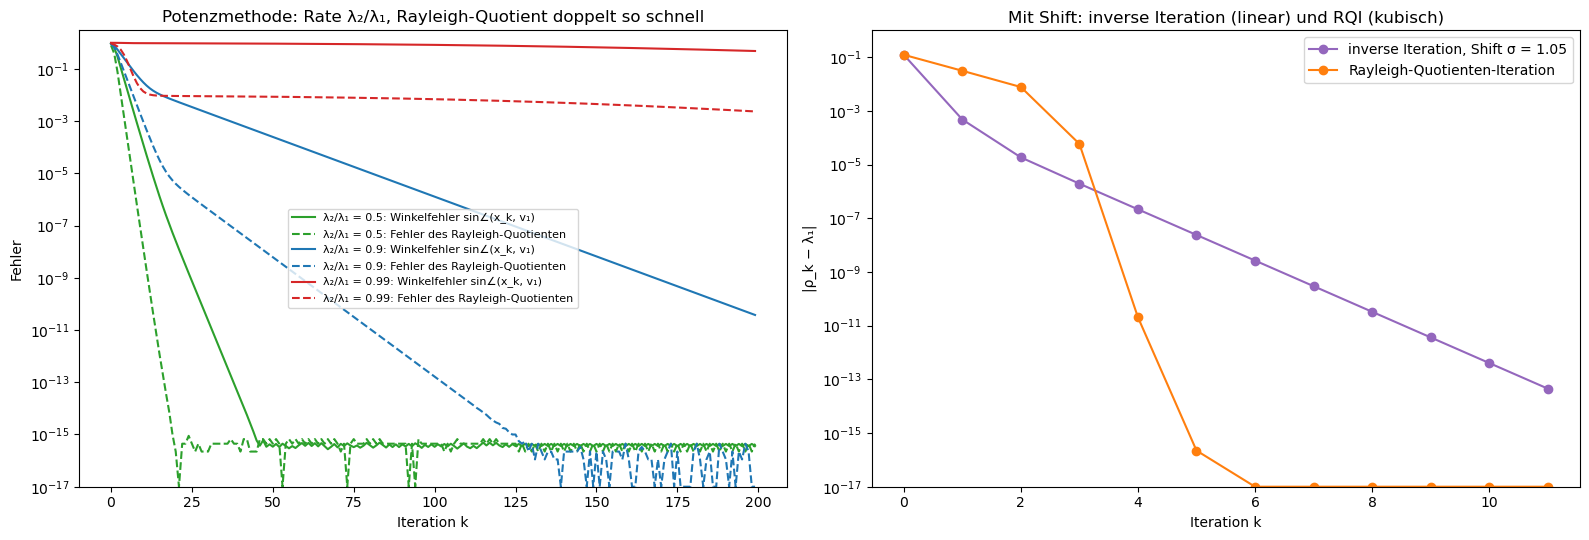

In [11]:
n10 = 50
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for r, farbe in zip([0.5, 0.9, 0.99], ["tab:green", "tab:blue", "tab:red"]):
    spektrum10 = np.concatenate([[1.0, r], rng.uniform(-0.8 * r, 0.8 * r, n10 - 2)])
    Q10 = zufalls_orthogonal(n10, rng)
    A10 = (Q10 * spektrum10) @ Q10.T
    v1 = Q10[:, 0]
    x = rng.standard_normal(n10)
    f_vek, f_ray = [], []
    for k in range(200):
        x = A10 @ x; x /= np.linalg.norm(x)
        f_vek.append(np.linalg.norm(x - (x @ v1) * v1)); f_ray.append(abs(x @ A10 @ x - 1.0))   # Sinus des Winkels
    f_vek, f_ray = np.maximum(f_vek, 1e-17), np.maximum(f_ray, 1e-17)
    axes[0].semilogy(f_vek, color=farbe, label=f"λ₂/λ₁ = {r}: Winkelfehler sin∠(x_k, v₁)")
    axes[0].semilogy(f_ray, color=farbe, ls="--", label=f"λ₂/λ₁ = {r}: Fehler des Rayleigh-Quotienten")
    erst = lambda f: next((k + 1 for k, w in enumerate(f) if w < 1e-14), None)
    print(f"λ₂/λ₁ = {r}: nach 200 Schritten Winkelfehler {f_vek[-1]:.1e} (r^200 = {r**200:.1e}), "
          f"Rayleigh-Fehler {f_ray[-1]:.1e} (r^400 = {r**400:.1e}); unter 1e-14 nach {erst(f_vek)} bzw. {erst(f_ray)} Schritten")
    if r == 0.9:
        A_inv, v1_inv = A10, v1
axes[0].set_ylim(1e-17, 3); axes[0].set_xlabel("Iteration k"); axes[0].set_ylabel("Fehler")
axes[0].set_title("Potenzmethode: Rate λ₂/λ₁, Rayleigh-Quotient doppelt so schnell"); axes[0].legend(fontsize=8)

x_start = v1_inv + 0.4 * rng.standard_normal(n10) / np.sqrt(n10)
x_start /= np.linalg.norm(x_start)
for name, art, farbe in [("inverse Iteration, Shift σ = 1.05", "invers", "tab:purple"), ("Rayleigh-Quotienten-Iteration", "rqi", "tab:orange")]:
    x, fehler = x_start.copy(), []
    for k in range(12):
        rho = x @ A_inv @ x
        fehler.append(abs(rho - 1.0))
        sigma = 1.05 if art == "invers" else rho
        try:
            x = np.linalg.solve(A_inv - sigma * np.eye(n10), x)
        except np.linalg.LinAlgError:
            break
        x /= np.linalg.norm(x)
    fehler = np.maximum(fehler, 1e-17)
    axes[1].semilogy(fehler, "o-", color=farbe, label=name)
    print(f"{name}: |ρ_k − λ₁| = " + ", ".join(f"{f:.0e}" for f in fehler[:7]))
axes[1].set_ylim(1e-17, 1); axes[1].set_xlabel("Iteration k"); axes[1].set_ylabel("|ρ_k − λ₁|")
axes[1].set_title("Mit Shift: inverse Iteration (linear) und RQI (kubisch)"); axes[1].legend()
plt.tight_layout()
plt.show()

* Das **linke Bild** zeigt Winkelfehler (durchgezogen) und Fehler des Rayleigh-Quotienten (gestrichelt) gegen die Iteration. Jede Kurve ist eine Gerade mit der Steigung $\log r$ bzw. $2\log r$, bis sie die Rundungsgrenze erreicht. Bei $r = 0.5$ ist der Rayleigh-Quotient nach 19 Schritten auf $10^{-14}$ genau, der Eigenvektor erst nach 43. Bei $r = 0.9$ braucht der Rayleigh-Quotient 115 Schritte, der Eigenvektor ist nach 200 Schritten auf $4\cdot10^{-11}$ genau. Bei $r = 0.99$ ist der Eigenvektor nach 200 Schritten noch um 0.49 falsch und der Eigenwert um $2.4\cdot10^{-3}$: Bei kleiner Lücke ist die Potenzmethode hoffnungslos langsam.
* Das **rechte Bild** zeigt, was ein Shift bringt. Die inverse Iteration mit $\sigma = 1.05$ hat im Eigenvektor die Rate $0.05/0.15 = 1/3$, im Rayleigh-Quotienten also $1/9$; der Fehler fällt gleichmäßig von 0.1 auf $3\cdot10^{-9}$ in sechs Schritten. Bei der Rayleigh-Quotienten-Iteration bringen die ersten zwei Schritte wenig (0.1, 0.03, 0.008), dann geht es $6\cdot10^{-5}$, $2\cdot10^{-11}$, $2\cdot10^{-16}$: kubische Konvergenz. Der Preis ist ein neues Gleichungssystem in jedem Schritt, und RQI konvergiert zu dem Eigenwert, dessen Eigenvektor dem Start am nächsten ist, nicht unbedingt zum größten.

##### *11. QR-Algorithmus: das Standardverfahren*

Wie berechnen numpy, scipy und Matlab alle Eigenwerte einer dichten Matrix? Vorher überlegen: Wenn man $A$ immer wieder in $QR$ zerlegt und $RQ$ bildet, ändern sich dann die Eigenwerte?

Eine symmetrische 6×6-Matrix mit den Eigenwerten 8, 6, 3, 2.5, 1, 0.5 wird zuerst auf Tridiagonalform gebracht (Householder, `scipy.linalg.hessenberg`). Dann folgen 60 Schritte des QR-Algorithmus ohne Shift; gemessen werden die fünf Nebendiagonaleinträge $\vert a_{i+1,i}\vert$ und ihre Abnahmerate. Zum Vergleich der QR-Algorithmus mit Wilkinson-Shift und Deflation, wie ihn LAPACK benutzt.

**Hintergrund & Fachbegriffe:**
- **QR-Zerlegung:** $A = QR$ mit orthogonalem $Q$ und oberer Dreiecksmatrix $R$ (Gram–Schmidt der Spalten, numerisch mit Householder-Spiegelungen).
- **QR-Schritt:** $A_k = Q_kR_k$, $A_{k+1} = R_kQ_k = Q_k^TA_kQ_k$. Jeder Schritt ist eine orthogonale Ähnlichkeitstransformation, die Eigenwerte bleiben gleich. Ohne Shift ist das eine Potenzmethode mit allen Vektoren gleichzeitig: $A_k$ konvergiert gegen eine obere Dreiecksmatrix (bei symmetrischem $A$ gegen eine Diagonalmatrix) mit den Eigenwerten der Größe nach auf der Diagonale, und $a_{i+1,i}$ fällt wie $\vert\lambda_{i+1}/\lambda_i\vert^k$.
- **Hessenberg- und Tridiagonalform:** Vorab bringt man $A$ mit $O(n^3)$ Operationen auf obere Hessenberg-Form (null unterhalb der ersten Nebendiagonale); bei symmetrischem $A$ ist das eine Tridiagonalmatrix. Die Form bleibt bei QR-Schritten erhalten, und ein Schritt kostet dann nur $O(n^2)$ bzw. $O(n)$.
- **Shift und Deflation:** Man zerlegt $A_k - \mu I$ statt $A_k$. Liegt $\mu$ nahe an einem Eigenwert, fällt der letzte Nebendiagonaleintrag fast sofort. Der **Wilkinson-Shift** ist der Eigenwert des unteren 2×2-Blocks, der näher an $a_{nn}$ liegt; damit konvergiert das Verfahren für symmetrische Matrizen kubisch. Ist $a_{n,n-1}$ klein genug, liest man $a_{nn}$ als Eigenwert ab und macht mit der um eins kleineren Matrix weiter (**Deflation**).

|a_(2,1)|: Rate pro Iteration 0.7501, erwartet λ_2/λ_1 = 0.7500
|a_(3,2)|: Rate pro Iteration 0.4985, erwartet λ_3/λ_2 = 0.5000
|a_(4,3)|: Rate pro Iteration 0.8381, erwartet λ_4/λ_3 = 0.8333
|a_(5,4)|: Rate pro Iteration 0.3989, erwartet λ_5/λ_4 = 0.4000
|a_(6,5)|: Rate pro Iteration 0.5000, erwartet λ_6/λ_5 = 0.5000
Diagonale nach 60 Iterationen: [8.  6.  3.  2.5 1.  0.5]
|a_(m,m−1)| nach jedem Schritt mit Shift: 2e-02, 1e-06, 1e-18, 2e-05, 3e-18, 5e-03, 2e-08, 1e-24, 3e-13, 6e-40, 1e-17
mit Wilkinson-Shift: Eigenwerte [8.  6.  3.  2.5 1.  0.5], Iterationen pro Eigenwert [3, 2, 3, 2, 1] (zusammen 11)


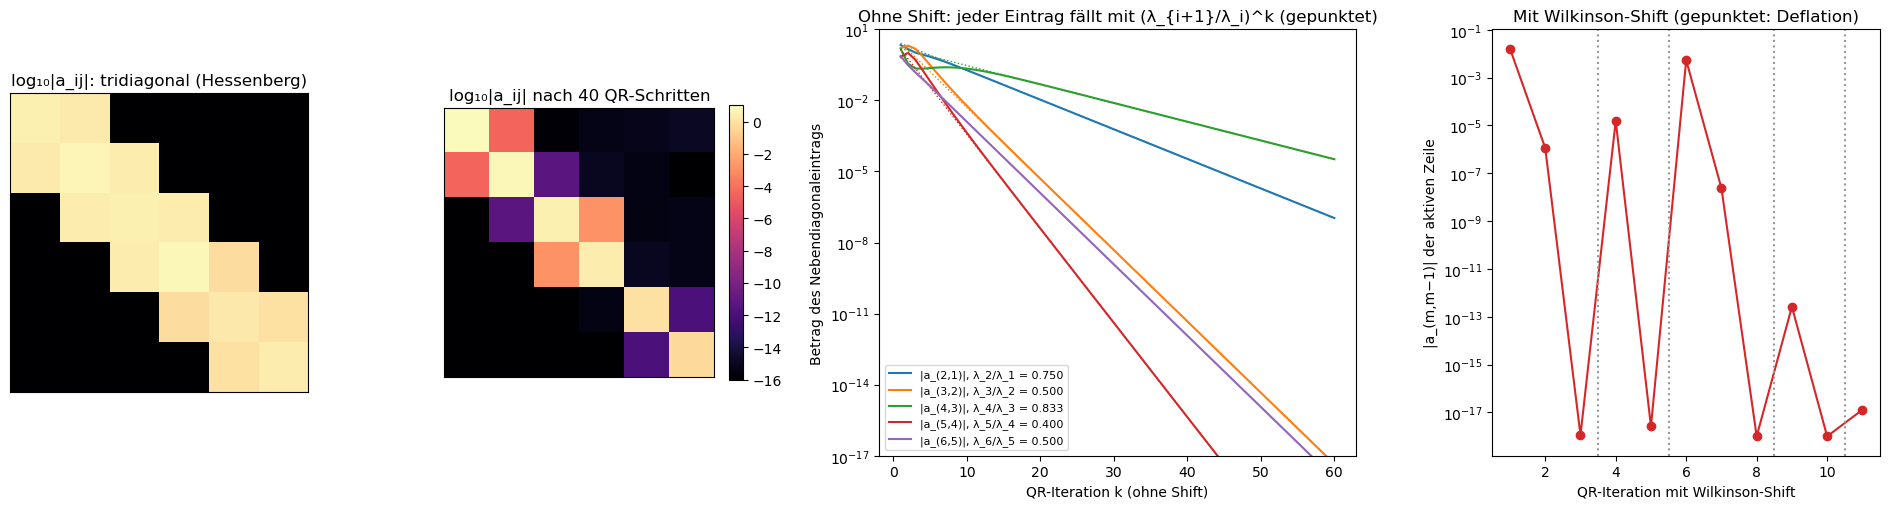

In [12]:
ew11 = np.array([8.0, 6.0, 3.0, 2.5, 1.0, 0.5])
A11 = hessenberg(mit_spektrum(ew11, rng))                                # symmetrisch → tridiagonal
A11 = np.triu(np.tril(A11, 1), -1)                                        # Rundungsreste außerhalb des Bandes löschen
Ak, unten, schnapp11 = A11.copy(), [], {0: A11.copy()}
for k in range(1, 61):
    Q, R = np.linalg.qr(Ak)
    Ak = R @ Q                                                            # A_k = Qᵀ A_(k−1) Q: ähnlich, gleiche Eigenwerte
    unten.append(np.abs(np.diag(Ak, -1)))
    if k in (5, 40):
        schnapp11[k] = Ak.copy()
unten = np.array(unten)
quot = ew11[1:] / ew11[:-1]
for i in range(5):
    rate = np.exp(np.polyfit(np.arange(10, 40), np.log(unten[9:39, i]), 1)[0])
    print(f"|a_({i + 2},{i + 1})|: Rate pro Iteration {rate:.4f}, erwartet λ_{i + 2}/λ_{i + 1} = {quot[i]:.4f}")
print("Diagonale nach 60 Iterationen:", np.round(np.diag(Ak), 8))


def qr_mit_shift(A, tol=1e-14):
    """QR-Verfahren mit Wilkinson-Shift und Deflation für symmetrische Tridiagonalmatrizen; zählt die Iterationen
    pro Eigenwert und protokolliert |a_(m,m−1)|."""
    A = A.copy(); n = len(A); werte, schritte, protokoll = [], [], []
    while n > 1:
        it = 0
        while abs(A[n - 1, n - 2]) > tol * (abs(A[n - 1, n - 1]) + abs(A[n - 2, n - 2])):
            a, b, c = A[n - 2, n - 2], A[n - 1, n - 2], A[n - 1, n - 1]
            d = (a - c) / 2
            mu = c - np.sign(d if d != 0 else 1.0) * b**2 / (abs(d) + np.hypot(d, b))
            Q, R = np.linalg.qr(A[:n, :n] - mu * np.eye(n))
            A[:n, :n] = R @ Q + mu * np.eye(n)
            it += 1; protokoll.append(abs(A[n - 1, n - 2]))
        werte.append(A[n - 1, n - 1]); schritte.append(it); n -= 1
    werte.append(A[0, 0])
    return np.array(werte), schritte, protokoll


werte11, schritte11, prot11 = qr_mit_shift(A11)
print("|a_(m,m−1)| nach jedem Schritt mit Shift:", ", ".join(f"{w:.0e}" for w in prot11))
print(f"mit Wilkinson-Shift: Eigenwerte {np.round(np.sort(werte11)[::-1], 12)}, Iterationen pro Eigenwert {schritte11}"
      f" (zusammen {sum(schritte11)})")

fig = plt.figure(figsize=(19, 5.2))
gs11 = GridSpec(1, 4, figure=fig, width_ratios=[1, 1, 1.6, 1.3])
for i, k in enumerate([0, 40]):
    ax = fig.add_subplot(gs11[0, i])
    im = ax.imshow(np.log10(np.abs(schnapp11[k]) + 1e-17), cmap="magma", vmin=-16, vmax=1)
    ax.set_title(f"log₁₀|a_ij| nach {k} QR-Schritten" if k else "log₁₀|a_ij|: tridiagonal (Hessenberg)")
    ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=ax, fraction=0.046)
ax = fig.add_subplot(gs11[0, 2])
kk = np.arange(1, 61)
for i in range(5):
    ax.semilogy(kk, unten[:, i], color=f"C{i}", label=f"|a_({i + 2},{i + 1})|, λ_{i + 2}/λ_{i + 1} = {quot[i]:.3f}")
    ax.semilogy(kk, unten[19, i] * quot[i]**(kk - 20), color=f"C{i}", ls=":", lw=1)
ax.set_ylim(1e-17, 10); ax.set_xlabel("QR-Iteration k (ohne Shift)"); ax.set_ylabel("Betrag des Nebendiagonaleintrags")
ax.set_title("Ohne Shift: jeder Eintrag fällt mit (λ_{i+1}/λ_i)^k (gepunktet)"); ax.legend(fontsize=8)
ax = fig.add_subplot(gs11[0, 3])
ax.semilogy(np.arange(1, len(prot11) + 1), np.maximum(prot11, 1e-18), "o-", color="tab:red")
grenzen = np.cumsum(schritte11)
for g in grenzen[:-1]:
    ax.axvline(g + 0.5, color="0.6", ls=":")
ax.set_xlabel("QR-Iteration mit Wilkinson-Shift"); ax.set_ylabel("|a_(m,m−1)| der aktiven Zeile")
ax.set_title("Mit Wilkinson-Shift (gepunktet: Deflation)")
plt.tight_layout()
plt.show()

* Die **beiden linken Bilder** zeigen $\log_{10}\vert a_{ij}\vert$ der Tridiagonalmatrix am Anfang und nach 40 QR-Schritten ohne Shift. Außerhalb des Bandes bleibt alles auf Rundungsniveau (schwarz): Die Tridiagonalform bleibt erhalten. Nach 40 Schritten steht auf der Diagonale schon 8, 6, 3, 2.5, 1, 0.5 von oben nach unten; die Nebendiagonale ist verschieden weit abgeklungen, am wenigsten an der Stelle (4, 3) zwischen 3 und 2.5.
* Das **dritte Bild** zeigt die fünf Nebendiagonaleinträge gegen die Zahl der QR-Schritte. Jeder fällt geometrisch, und die gemessenen Raten 0.7501, 0.4985, 0.8381, 0.3989, 0.5000 stimmen mit den Quotienten $\lambda_{i+1}/\lambda_i = 0.75, 0.5, 0.833, 0.4, 0.5$ überein. Der langsamste Eintrag bestimmt die Laufzeit; bei nah beieinanderliegenden Eigenwerten ist das Verfahren ohne Shift so langsam wie die Potenzmethode.
* Das **rechte Bild** zeigt den QR-Algorithmus mit Wilkinson-Shift. Beim ersten Eigenwert fällt der letzte Nebendiagonaleintrag von $2\cdot10^{-2}$ über $10^{-6}$ auf $10^{-18}$, die Exponenten verdreifachen sich ungefähr: kubische Konvergenz. Dann wird der Eigenwert abgetrennt (gepunktete Linie) und der nächste bearbeitet. Für alle sechs Eigenwerte reichen 11 Schritte (3, 2, 3, 2, 1) statt der 60 ohne Shift, und das Ergebnis stimmt auf zwölf Stellen. Nach diesem Prinzip arbeitet `numpy.linalg.eig` (LAPACK, mit dem impliziten Doppelshift von Francis für reelle Matrizen); `numpy.linalg.eigh` behandelt die Tridiagonalmatrix stattdessen mit einem Divide-and-Conquer-Verfahren.

##### *12. Lanczos: Eigenwerte riesiger dünnbesetzter Matrizen*

Wie findet man die kleinsten Eigenwerte einer Matrix mit 16 384 Zeilen, deren dichte Form 2 GB bräuchte? Vorher überlegen: Welche Eigenwerte sollte ein Verfahren zuerst finden, das nur mit $\mathbf v, A\mathbf v, A^2\mathbf v, \dots$ arbeitet?

Der Hamilton-Operator des Heisenberg-Rings aus $N = 14$ Spins ½, $H = J\sum_i\mathbf S_i\cdot\mathbf S_{i+1}$ mit periodischem Rand und $J = 1$, wird als dünnbesetzte Matrix aufgebaut. Dann folgen 120 Lanczos-Schritte von einem Zufallsvektor aus, mit vollständiger Reorthogonalisierung; nach jedem Schritt werden die Ritz-Werte berechnet. Zum Vergleich die acht kleinsten Eigenwerte mit `scipy.sparse.linalg.eigsh` (ARPACK) und die Grundzustandsenergie der unendlich langen Kette.

**Hintergrund & Fachbegriffe:**
- **Dünnbesetzte Matrix:** Fast alle Einträge sind null, gespeichert werden nur die anderen. Hier hat jede Zeile höchstens 15 Einträge ungleich null (die Diagonale und einen Spin-Tausch pro Bindung mit antiparallelen Spins); das Produkt $H\mathbf v$ kostet deshalb nur so viel wie die Länge von $\mathbf v$.
- **Krylov-Raum:** $\mathcal K_m = \mathrm{span}\lbrace\mathbf v, A\mathbf v, \dots, A^{m-1}\mathbf v\rbrace$, alles, was man mit $m - 1$ Matrix-Vektor-Produkten erreicht. Er enthält die Ergebnisse von $m - 1$ Schritten Potenzmethode, aber auch jedes Polynom vom Grad $<m$ in $A$, angewendet auf $\mathbf v$; das Lanczos-Verfahren nutzt das beste davon.
- **Lanczos-Verfahren:** baut eine Orthonormalbasis $V_m$ von $\mathcal K_m$ mit der dreigliedrigen Rekursion $A\mathbf v_j = \beta_{j-1}\mathbf v_{j-1} + \alpha_j\mathbf v_j + \beta_j\mathbf v_{j+1}$. In dieser Basis ist $A$ die Tridiagonalmatrix $T_m = V_m^TAV_m$ mit der Diagonale $\alpha$ und der Nebendiagonale $\beta$.
- **Ritz-Werte:** die Eigenwerte von $T_m$, die besten Näherungen für Eigenwerte von $A$ im Raum $\mathcal K_m$ (Rayleigh–Ritz). Die Eigenwerte am Rand des Spektrums konvergieren zuerst, besonders wenn sie Abstand zu ihren Nachbarn haben.
- **Reorthogonalisierung und Entartung:** In Gleitkommarechnung verlieren die Lanczos-Vektoren ihre Orthogonalität, und konvergierte Eigenwerte tauchen als Kopien noch einmal auf („Geister“); vollständige Reorthogonalisierung verhindert das. In exakter Rechnung enthält der Krylov-Raum zu jedem Eigenwert nur einen Vektor, egal wie oft er entartet ist: Lanczos sieht keine Vielfachheiten.
- **Heisenberg-Modell:** $\mathbf S_i\cdot\mathbf S_j = \frac14(X_iX_j + Y_iY_j + Z_iZ_j)$, antiferromagnetisch für $J>0$. Für die unendlich lange Kette ist die Grundzustandsenergie pro Spin $\frac14 - \ln2 = -0.4431$ (Hulthén 1938, mit dem Bethe-Ansatz).

Heisenberg-Ring mit 14 Spins: Dimension 16384, 131072 Einträge ungleich null (4.9e-04 der Matrix; dicht wären es 2.1 GB)
scipy eigsh (ARPACK, implizit neugestartetes Lanczos): 8 kleinste Eigenwerte [-6.26355  -5.956444 -5.956444 -5.956444 -5.748063 -5.558563 -5.558563
 -5.558563] in 0.0 s
  E₀/N = -0.447396; unendlich lange Kette (Bethe-Ansatz): 1/4 − ln 2 = -0.443147
Lanczos: |Ritz₀ − E₀| = 1.9e-04 nach 20, 3.6e-15 nach 40, 1.3e-14 nach 60 Schritten
  verschiedene Eigenwerte unter den 8 kleinsten: [-6.26355  -5.956444 -5.748063 -5.558563]
  Ritz-Werte nach 60 Schritten bis -5.5586: [-6.26355  -5.956444 -5.748063 -5.558563]
  Ritz-Werte nach 120 Schritten bis -5.5586: [-6.26355  -5.956444 -5.956444 -5.748063 -5.558563 -5.558563]


  größter Eigenwert 3.500000 (= N/4, alle Spins parallel); Ritz_max nach 120 Schritten 3.500000


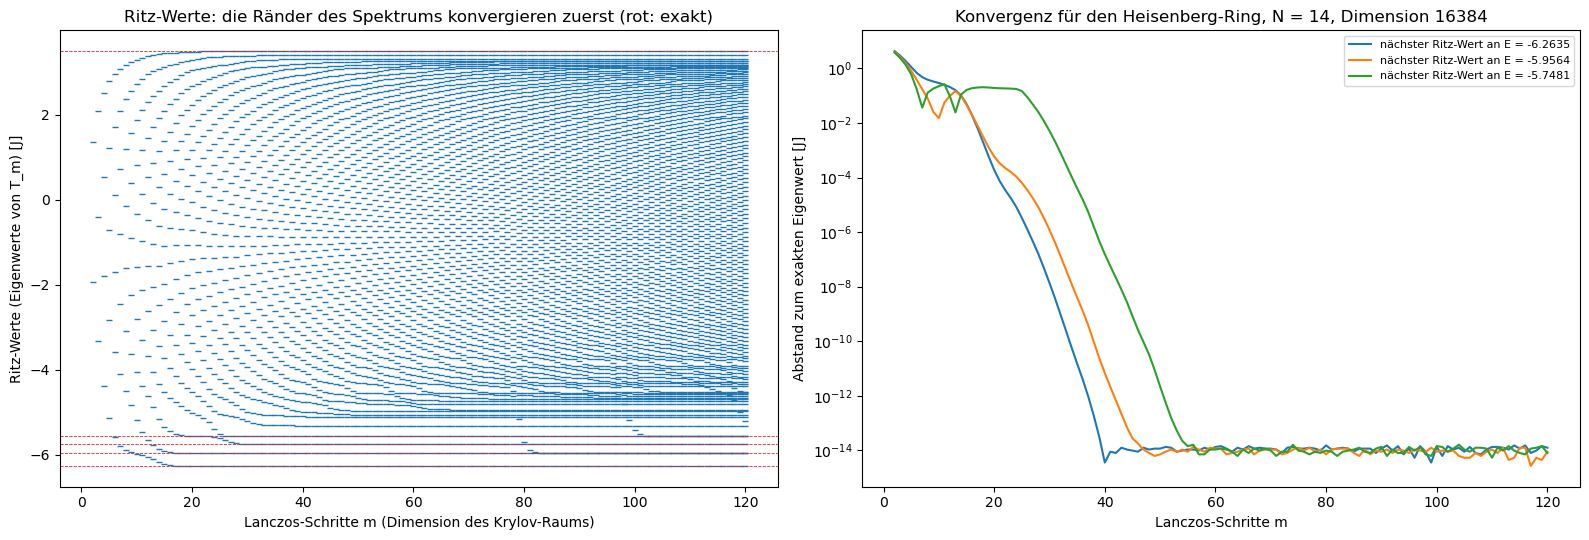

In [13]:
N12 = 14
paare = [(i, (i + 1) % N12) for i in range(N12)]
H12 = sum(operator_kette({i: P, j: P}, N12, sparse=True) for i, j in paare for P in (PAULI_X, PAULI_Y, PAULI_Z)) / 4
H12 = sps.csr_matrix(H12.real)                                            # S_i·S_j mit S = σ/2; alle Einträge reell
print(f"Heisenberg-Ring mit {N12} Spins: Dimension {H12.shape[0]}, {H12.nnz} Einträge ungleich null "
      f"({H12.nnz / H12.shape[0]**2:.1e} der Matrix; dicht wären es {H12.shape[0]**2 * 8 / 1e9:.1f} GB)")
t0_12 = time.time()
ref = np.sort(spsl.eigsh(H12, k=8, which="SA", return_eigenvectors=False))
print(f"scipy eigsh (ARPACK, implizit neugestartetes Lanczos): 8 kleinste Eigenwerte {np.round(ref, 6)} in {time.time() - t0_12:.1f} s")
print(f"  E₀/N = {ref[0] / N12:.6f}; unendlich lange Kette (Bethe-Ansatz): 1/4 − ln 2 = {0.25 - np.log(2):.6f}")
m12 = 120
alpha12, beta12 = lanczos(lambda v: H12 @ v, rng.standard_normal(H12.shape[0]), m12)
ritz = [ritz_werte(alpha12[:m], beta12[:m - 1]) for m in range(2, m12 + 1)]
f_e0 = np.array([abs(r[0] - ref[0]) for r in ritz])
verschieden = ref[np.concatenate([[True], np.diff(ref) > 1e-6])]
print(f"Lanczos: |Ritz₀ − E₀| = {f_e0[18]:.1e} nach 20, {f_e0[38]:.1e} nach 40, {f_e0[58]:.1e} nach 60 Schritten")
print(f"  verschiedene Eigenwerte unter den 8 kleinsten: {np.round(verschieden, 6)}")
for m in (60, m12):
    r = ritz[m - 2]
    print(f"  Ritz-Werte nach {m} Schritten bis {ref[-1]:.4f}: {np.round(r[r < ref[-1] + 1e-6], 6)}")
gesamt = np.array(spsl.eigsh(H12, k=1, which="LA", return_eigenvectors=False))
print(f"  größter Eigenwert {gesamt[0]:.6f} (= N/4, alle Spins parallel); Ritz_max nach {m12} Schritten {ritz[-1][-1]:.6f}")

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
ax = axes[0]
for m, r in zip(range(2, m12 + 1), ritz):
    ax.plot(np.full(len(r), m), r, "_", color="tab:blue", ms=5)
for e in verschieden:
    ax.axhline(e, color="tab:red", lw=0.6, ls="--")
ax.axhline(gesamt[0], color="tab:red", lw=0.6, ls="--")
ax.set_xlabel("Lanczos-Schritte m (Dimension des Krylov-Raums)"); ax.set_ylabel("Ritz-Werte (Eigenwerte von T_m) [J]")
ax.set_title("Ritz-Werte: die Ränder des Spektrums konvergieren zuerst (rot: exakt)")
ax = axes[1]
for j, farbe in enumerate(["tab:blue", "tab:orange", "tab:green"]):
    e = verschieden[j]
    f = [np.min(np.abs(r - e)) for r in ritz]
    ax.semilogy(range(2, m12 + 1), np.maximum(f, 1e-16), color=farbe, label=f"nächster Ritz-Wert an E = {e:.4f}")
ax.set_xlabel("Lanczos-Schritte m"); ax.set_ylabel("Abstand zum exakten Eigenwert [J]"); ax.legend(fontsize=8)
ax.set_title(f"Konvergenz für den Heisenberg-Ring, N = {N12}, Dimension {2**N12}")
plt.tight_layout()
plt.show()

* Die Matrix hat 16 384 Zeilen und 131 072 Einträge ungleich null, im Mittel acht pro Zeile ($5\cdot10^{-4}$ aller Einträge); dicht wären es 2.1 GB. `eigsh` findet die acht kleinsten Eigenwerte in Sekundenbruchteilen: $-6.26355$ (Grundzustand), dreimal $-5.956444$ (ein Triplett), $-5.748063$ und dreimal $-5.558563$. Die Energie pro Spin $-0.4474$ liegt nahe am Wert $-0.4431$ der unendlich langen Kette; der Unterschied kommt von der endlichen Länge.
* Das **linke Bild** zeigt die Ritz-Werte nach jedem Lanczos-Schritt (ein blauer Strich pro Wert), die roten Linien die exakten Eigenwerte. Am unteren und am oberen Rand des Spektrums laufen die Ritz-Werte schnell auf die exakten Werte zu und bleiben dort, oben auf den größten Eigenwert $3.5 = N/4$ (alle Spins parallel). Im Inneren, wo die Eigenwerte dicht liegen, sind die Ritz-Werte nach 120 Schritten noch keine Eigenwerte.
* Das **rechte Bild** zeigt den Abstand des nächsten Ritz-Werts zu den drei kleinsten verschiedenen Eigenwerten. Der Grundzustand ist nach 20 Schritten auf $2\cdot10^{-4}$ genau und nach 40 Schritten auf etwa $10^{-14}$; der zweite und dritte Eigenwert folgen wenige Schritte später. 40 Matrix-Vektor-Produkte reichen also für eine Matrix der Dimension 16 384, weil nur der Rand des Spektrums gesucht ist.
* Nach 60 Schritten sind unterhalb von $-5.5586$ genau die vier verschiedenen Eigenwerte je einmal da, auch die Tripletts nur einfach: Lanczos sieht die Vielfachheit nicht. Nach 120 Schritten tauchen $-5.956444$ und $-5.558563$ ein zweites Mal auf. Das sind keine Geister (die Reorthogonalisierung ist vollständig); Rundungsfehler haben dem Krylov-Raum winzige Anteile der anderen Triplett-Zustände gegeben, die über viele Schritte verstärkt wurden. Die Zahl der Kopien sagt also nichts Verlässliches über die Entartung; dafür nimmt man Block-Lanczos oder nutzt die Symmetrie (hier den Gesamtspin).

##### *13. Wie empfindlich sind Eigenwerte?*

Wie stark verschieben sich Eigenwerte, wenn man die Matrix um $\varepsilon = 10^{-8}$ stört, etwa durch Rundung oder Messfehler in den Einträgen? Vorher überlegen: Ein 8×8-Jordan-Block hat achtmal den Eigenwert 0. Wo liegen seine Eigenwerte nach einer Störung der Größe $10^{-8}$?

Eine zufällige symmetrische 8×8-Matrix und der 8×8-Jordan-Block $J$ (Einsen auf der ersten oberen Nebendiagonale) werden je 300-mal mit zufälligen Matrizen $E$ der Spektralnorm $10^{-8}$ gestört, die symmetrische mit symmetrischem $E$. Dann wird die größte Verschiebung gegen $\varepsilon$ von $10^{-14}$ bis $10^{-2}$ gemessen. Zum Schluss wird die Schranke von Bauer–Fike an einer diagonalisierbaren, aber stark nicht normalen Dreiecksmatrix geprüft.

**Hintergrund & Fachbegriffe:**
- **Normale Matrix:** $AA^\dagger = A^\dagger A$; genau dann gibt es eine Orthonormalbasis aus Eigenvektoren. Hermitesche und unitäre Matrizen sind normal, Jordan-Blöcke und typische Dreiecksmatrizen nicht.
- **Spektralnorm:** $\Vert E\Vert_2 = \max_{\Vert\mathbf x\Vert = 1}\Vert E\mathbf x\Vert$, der größte Singulärwert; die stärkste Streckung, die $E$ bewirkt.
- **Satz von Weyl:** Für hermitesche $A$ und $E$ verschiebt sich jeder (der Größe nach sortierte) Eigenwert höchstens um $\Vert E\Vert_2$. Eigenwerte hermitescher Matrizen sind also bestmöglich konditioniert.
- **Satz von Bauer–Fike:** Ist $A = V\Lambda V^{-1}$ diagonalisierbar, liegt jeder Eigenwert von $A + E$ höchstens $\kappa(V)\Vert E\Vert_2$ von einem Eigenwert von $A$ entfernt, mit der **Konditionszahl** $\kappa(V) = \Vert V\Vert\,\Vert V^{-1}\Vert\ge1$. Fast parallele Eigenvektoren geben großes $\kappa(V)$.
- **Jordan-Block:** $J_n(\lambda) = \lambda I + N$ mit Einsen auf der Nebendiagonale, nicht diagonalisierbar. Stört man den Eintrag unten links um $\varepsilon$, wird das charakteristische Polynom zu $\lambda^n - \varepsilon$, und die Eigenwerte springen auf den Kreis vom Radius $\varepsilon^{1/n}$.
- **Pseudospektrum:** die Menge der $z$, die Eigenwert irgendeiner um höchstens $\varepsilon$ gestörten Matrix sind. Bei normalen Matrizen sind das Kreise vom Radius $\varepsilon$ um die Eigenwerte, bei nicht normalen viel größere Gebiete.

symmetrisch, ‖E‖ = 1e-8: größte Verschiebung eines Eigenwerts 7.3e-09 (Weyl: ≤ ‖E‖)
Jordan-Block 8×8, ‖E‖ = 1e-8: größte Verschiebung 0.093, (1e-8)^(1/8) = 0.100
Steigungen: symmetrisch 1.00, Jordan-Block 0.128 (erwartet 1 und 1/8 = 0.125)
obere Dreiecksmatrix mit Diagonale 1 … 8: κ(V) = 1.1e+02; größte Verschiebung bei ‖E‖ = 1e-8: 1.8e-07, Schranke κ(V)·‖E‖ = 1.1e-06 (symmetrisch: κ(V) = 1)


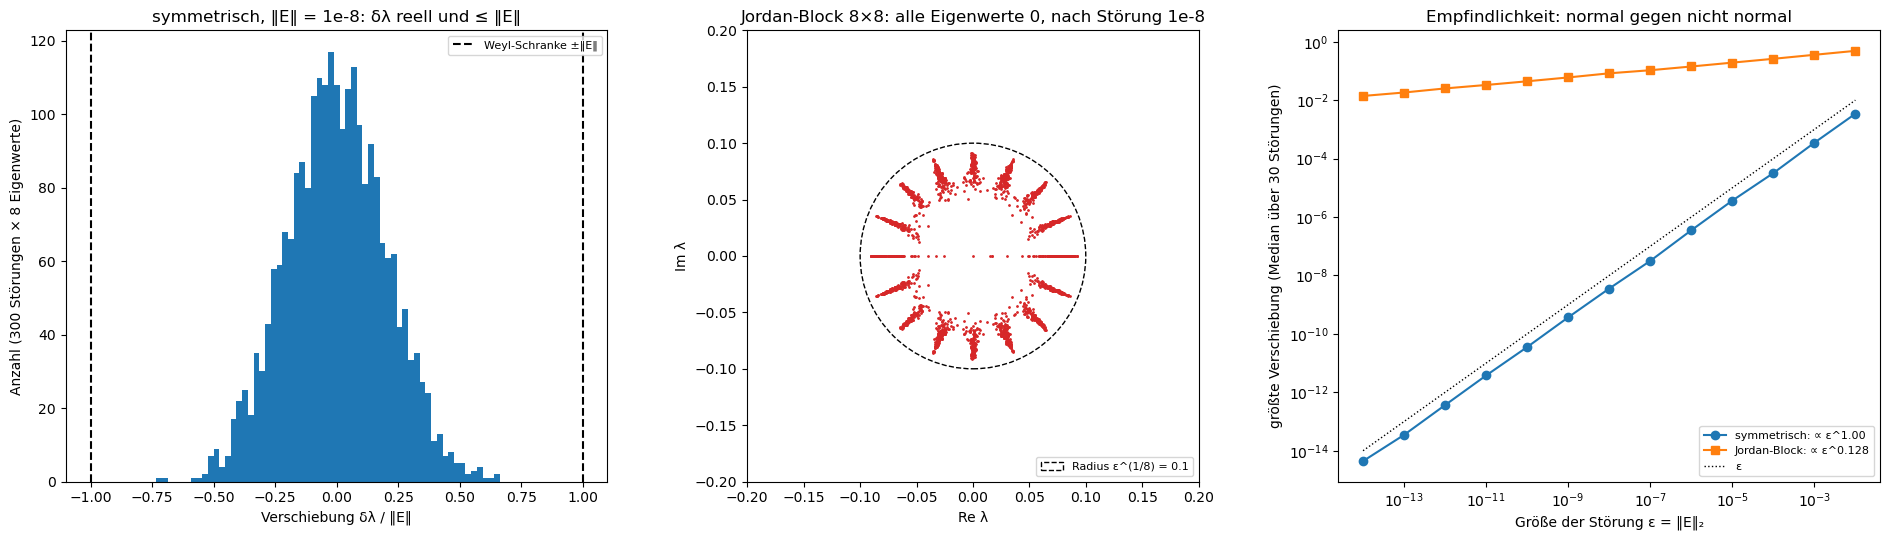

In [14]:
n13 = 8
S13 = rng.standard_normal((n13, n13)); S13 = (S13 + S13.T) / 2
J13 = np.eye(n13, k=1)                                                    # Jordan-Block zum Eigenwert 0
eps13 = 1e-8
wolke_s, wolke_j = [], []
for _ in range(300):
    E = rng.standard_normal((n13, n13)); E *= eps13 / np.linalg.norm(E, 2)
    wolke_s.append(np.linalg.eigvalsh(S13 + (E + E.T) / 2) - np.linalg.eigvalsh(S13))
    wolke_j.append(np.linalg.eigvals(J13 + E))
wolke_s, wolke_j = np.concatenate(wolke_s), np.concatenate(wolke_j)
print(f"symmetrisch, ‖E‖ = 1e-8: größte Verschiebung eines Eigenwerts {np.max(np.abs(wolke_s)):.1e} (Weyl: ≤ ‖E‖)")
print(f"Jordan-Block 8×8, ‖E‖ = 1e-8: größte Verschiebung {np.max(np.abs(wolke_j)):.3f}, (1e-8)^(1/8) = {eps13**(1 / 8):.3f}")
eps_werte = np.logspace(-14, -2, 13)
f_sym, f_jor = [], []
for e in eps_werte:
    a, b = [], []
    for _ in range(30):
        E = rng.standard_normal((n13, n13)); E *= e / np.linalg.norm(E, 2)
        a.append(np.max(np.abs(np.linalg.eigvalsh(S13 + (E + E.T) / 2) - np.linalg.eigvalsh(S13))))
        b.append(np.max(np.abs(np.linalg.eigvals(J13 + E))))
    f_sym.append(np.median(a)); f_jor.append(np.median(b))
st_s = np.polyfit(np.log(eps_werte[2:]), np.log(f_sym[2:]), 1)[0]
st_j = np.polyfit(np.log(eps_werte), np.log(f_jor), 1)[0]
print(f"Steigungen: symmetrisch {st_s:.2f}, Jordan-Block {st_j:.3f} (erwartet 1 und 1/8 = 0.125)")
# Bauer–Fike: |δλ| ≤ κ(V)‖E‖ für diagonalisierbare A = VΛV⁻¹; κ(V) misst, wie schief die Eigenvektoren stehen
D13 = np.diag(np.arange(1, n13 + 1, dtype=float)) + 3 * np.triu(rng.standard_normal((n13, n13)), 1)
_, V13 = np.linalg.eig(D13)
verschiebung = []
for _ in range(100):
    E = rng.standard_normal((n13, n13)); E *= eps13 / np.linalg.norm(E, 2)
    verschiebung.append(np.max(np.abs(np.sort(np.linalg.eigvals(D13 + E).real) - np.arange(1, n13 + 1))))
print(f"obere Dreiecksmatrix mit Diagonale 1 … 8: κ(V) = {np.linalg.cond(V13):.1e}; größte Verschiebung bei ‖E‖ = 1e-8: "
      f"{max(verschiebung):.1e}, Schranke κ(V)·‖E‖ = {np.linalg.cond(V13) * eps13:.1e} (symmetrisch: κ(V) = 1)")

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
ax = axes[0]
ax.hist(wolke_s / eps13, bins=60, color="tab:blue")
ax.axvline(-1, color="k", ls="--", label="Weyl-Schranke ±‖E‖"); ax.axvline(1, color="k", ls="--")
ax.set_xlabel("Verschiebung δλ / ‖E‖"); ax.set_ylabel("Anzahl (300 Störungen × 8 Eigenwerte)")
ax.set_title("symmetrisch, ‖E‖ = 1e-8: δλ reell und ≤ ‖E‖"); ax.legend(fontsize=8)
ax = axes[1]
ax.plot(wolke_j.real, wolke_j.imag, ".", ms=2, color="tab:red")
ax.add_patch(Circle((0, 0), eps13**(1 / 8), fill=False, color="k", ls="--", label="Radius ε^(1/8) = 0.1"))
ax.set_aspect("equal"); ax.set_xlim(-0.2, 0.2); ax.set_ylim(-0.2, 0.2); ax.legend(loc="lower right", fontsize=8)
ax.set_xlabel("Re λ"); ax.set_ylabel("Im λ"); ax.set_title("Jordan-Block 8×8: alle Eigenwerte 0, nach Störung 1e-8")
ax = axes[2]
ax.loglog(eps_werte, f_sym, "o-", label=f"symmetrisch: ∝ ε^{st_s:.2f}")
ax.loglog(eps_werte, f_jor, "s-", label=f"Jordan-Block: ∝ ε^{st_j:.3f}")
ax.loglog(eps_werte, eps_werte, "k:", lw=1, label="ε")
ax.set_xlabel("Größe der Störung ε = ‖E‖₂"); ax.set_ylabel("größte Verschiebung (Median über 30 Störungen)")
ax.set_title("Empfindlichkeit: normal gegen nicht normal"); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

* Das **linke Bild** ist das Histogramm der Verschiebungen aller acht Eigenwerte der symmetrischen Matrix bei 300 Störungen, in Einheiten von $\Vert E\Vert = 10^{-8}$. Alle liegen innerhalb der Weyl-Schranken ±1, die größte bei 0.73; die Eigenwerte bleiben reell.
* Das **mittlere Bild** zeigt die Eigenwerte des gestörten Jordan-Blocks. Statt bei 0 liegen sie auf einer Blume mit acht Blättern innerhalb des Kreises vom Radius $\varepsilon^{1/8} = 0.1$; die größte Verschiebung ist 0.093. Eine Störung der Größe $10^{-8}$ verschiebt die Eigenwerte also um fast $10^{-1}$, sieben Größenordnungen mehr.
* Das **rechte Bild** zeigt die größte Verschiebung (Median über 30 Störungen) gegen $\varepsilon$. Für die symmetrische Matrix ist die Steigung 1.00, die Verschiebung also proportional zu $\varepsilon$; für den Jordan-Block ist sie 0.128, fast $1/8$. Schon bei $\varepsilon = 10^{-14}$, der Größe von Rundungsfehlern, verschieben sich die Eigenwerte des Jordan-Blocks um etwa $10^{-2}$.
* Die Dreiecksmatrix mit der Diagonale 1 bis 8 und einer großen oberen Hälfte ist diagonalisierbar, hat aber $\kappa(V) = 110$; bei $\Vert E\Vert = 10^{-8}$ verschieben sich ihre Eigenwerte um bis zu $1.8\cdot10^{-7}$, unter der Bauer–Fike-Schranke $1.1\cdot10^{-6}$. Folgerung: Eigenwerte hermitescher Matrizen (Observablen, Kovarianzen, Hesse-Matrizen) lassen sich immer genau berechnen. Bei nicht normalen Matrizen (Übergangsmatrizen, linearisierte Strömungen, nicht hermitesche Hamilton-Operatoren) können berechnete Eigenwerte weit danebenliegen, und man sollte das Pseudospektrum ansehen.

##### *14. Quanten: Eigenwerte sind Messwerte*

Was liefert eine einzelne Messung einer Observablen, wie hängen die Wahrscheinlichkeiten mit der Dichtematrix zusammen, und was bedeuten ihre Diagonale und Nebendiagonale? Vorher überlegen: Verändert Dekohärenz in der Eigenbasis von $S_x$ die Statistik einer $S_x$-Messung?

Ein Spin 1 (drei Zustände, $\hbar = 1$) ist im reinen Zustand $\psi\propto(0.7, 0.6, 0.2 + 0.3i)$, geschrieben in der Eigenbasis von $S_z$. Gemessen wird $S_x$ mit den Eigenwerten $-1, 0, 1$. Die Dichtematrix wird in die Eigenbasis von $S_x$ umgerechnet, und 2000 Messungen werden mit den Born-Wahrscheinlichkeiten simuliert. Dann wird $\rho$ in der $S_x$-Eigenbasis dephasiert (Nebendiagonale mal $e^{-\gamma t}$), und $\langle S_x\rangle$, $\langle S_z\rangle$ und die Reinheit werden verfolgt.

**Hintergrund & Fachbegriffe:**
- **Observable:** eine hermitesche Matrix $A = \sum_ka_kP_k$ mit den Eigenwerten $a_k$ und den Projektoren $P_k$ auf die Eigenräume. Die Eigenwerte sind die möglichen Messergebnisse; sie sind reell, weil $A$ hermitesch ist.
- **Born-Regel:** Im Zustand $\rho$ erhält man $a_k$ mit der Wahrscheinlichkeit $p_k = \mathrm{tr}(\rho P_k)$, bei einem reinen Zustand $\vert\langle a_k\vert\psi\rangle\vert^2$; danach ist der Zustand im Eigenraum. Der Erwartungswert ist $\langle A\rangle = \mathrm{tr}(\rho A) = \sum_ka_kp_k$.
- **Dichtematrix in der Eigenbasis:** $\rho_{kl} = \langle a_k\vert\rho\vert a_l\rangle$. Die **Diagonale** sind die Messwahrscheinlichkeiten $p_k$ (Besetzungen), die **Nebendiagonale** die **Kohärenzen**: Sie sagen, ob die Eigenzustände mit fester Phase überlagert sind (Superposition) oder nur zufällig gemischt.
- **Dephasierung:** Wechselwirkung mit einer Umgebung, die die Kohärenzen in einer bestimmten Basis abbaut, $\rho_{kl}\to\rho_{kl}e^{-\gamma t}$ für $k\neq l$, und die Diagonale stehen lässt.
- **Reinheit:** $\mathrm{tr}\rho^2 = \sum_k\lambda_k(\rho)^2$; 1 für reine Zustände. Bei vollständiger Dephasierung bleibt $\sum_kp_k^2$.
- **Spin-1-Matrizen:** $S_x = \frac1{\sqrt2}\begin{pmatrix}0&1&0\\1&0&1\\0&1&0\end{pmatrix}$, $S_z = \mathrm{diag}(1, 0, -1)$; beide haben die Eigenwerte $-1, 0, 1$, aber verschiedene Eigenvektoren.

Eigenwerte von S_x: [-1.  0.  1.]; Born-Wahrscheinlichkeiten = Diagonale von ρ in der Eigenbasis: [0.0236 0.1735 0.8029]
⟨S_x⟩ = tr(ρ S_x) = +0.7793 = Σ a_k p_k = +0.7793
2000 Messungen: nur die Werte [-1.  0.  1.] kommen vor, Häufigkeiten [0.029  0.1795 0.7915]; Mittelwert +0.7625 ± 0.0109
Dephasierung: ⟨S_x⟩ bleibt +0.7793 … +0.7793, ⟨S_z⟩ fällt von +0.3673 auf +0.0067, Reinheit tr ρ² von 1.0000 auf 0.6754 (Σp_k² = 0.6753)
⟨a_k|S_z|a_k⟩ für die drei Eigenvektoren von S_x: [-0.  0.  0.]


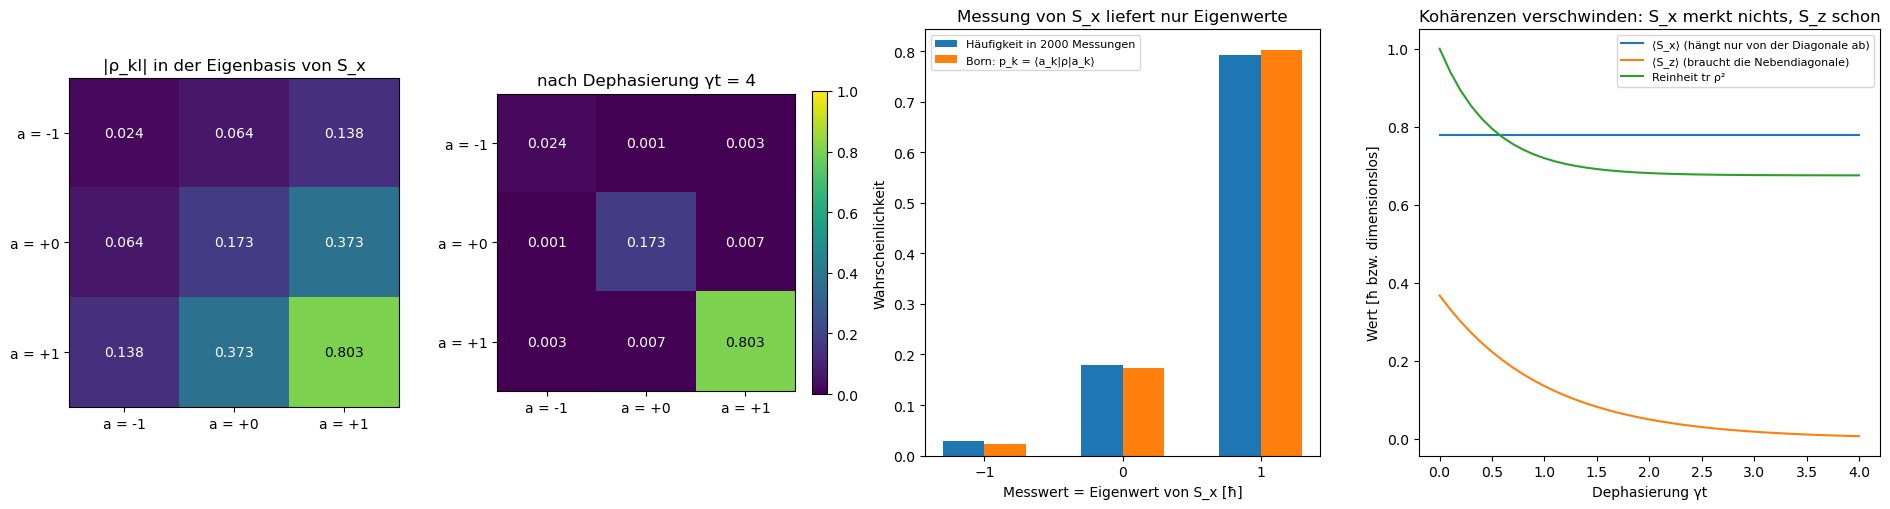

In [15]:
s2 = 1 / np.sqrt(2)
SX = np.array([[0, s2, 0], [s2, 0, s2], [0, s2, 0]], dtype=complex)        # Spin 1, ħ = 1
SZ = np.diag([1.0, 0.0, -1.0]).astype(complex)
a14, V14 = np.linalg.eigh(SX)                                              # Eigenwerte −1, 0, 1
psi14 = np.array([0.7, 0.6, 0.2 + 0.3j]); psi14 /= np.linalg.norm(psi14)
rho14 = np.outer(psi14, psi14.conj())
rho_eig = V14.conj().T @ rho14 @ V14                                       # ρ in der Eigenbasis von S_x
p_born = np.real(np.diag(rho_eig))
a14 = np.round(a14, 12) + 0.0                                              # −0 vermeiden
print(f"Eigenwerte von S_x: {a14}; Born-Wahrscheinlichkeiten = Diagonale von ρ in der Eigenbasis: {np.round(p_born, 4)}")
print(f"⟨S_x⟩ = tr(ρ S_x) = {np.real(np.trace(rho14 @ SX)):+.4f} = Σ a_k p_k = {a14 @ p_born:+.4f}")
N14 = 2000
schuesse = rng.choice(a14, size=N14, p=p_born)
werte14, zaehl = np.unique(np.round(schuesse, 9), return_counts=True)
print(f"{N14} Messungen: nur die Werte {werte14} kommen vor, Häufigkeiten {np.round(zaehl / N14, 4)}; "
      f"Mittelwert {schuesse.mean():+.4f} ± {schuesse.std(ddof=1) / np.sqrt(N14):.4f}")
gammas = np.linspace(0, 4, 41)
erw_sx, erw_sz, reinheit = [], [], []
for g in gammas:
    daempf = np.full((3, 3), np.exp(-g)); np.fill_diagonal(daempf, 1.0)
    r = V14 @ (rho_eig * daempf) @ V14.conj().T                            # Dephasierung in der Eigenbasis von S_x
    erw_sx.append(np.real(np.trace(r @ SX))); erw_sz.append(np.real(np.trace(r @ SZ))); reinheit.append(np.real(np.trace(r @ r)))
print(f"Dephasierung: ⟨S_x⟩ bleibt {erw_sx[0]:+.4f} … {erw_sx[-1]:+.4f}, ⟨S_z⟩ fällt von {erw_sz[0]:+.4f} auf {erw_sz[-1]:+.4f},"
      f" Reinheit tr ρ² von {reinheit[0]:.4f} auf {reinheit[-1]:.4f} (Σp_k² = {np.sum(p_born**2):.4f})")
print(f"⟨a_k|S_z|a_k⟩ für die drei Eigenvektoren von S_x: {np.round(np.real(np.diag(V14.conj().T @ SZ @ V14)), 12)}")

fig = plt.figure(figsize=(19, 5.2))
gs14 = GridSpec(1, 4, figure=fig, width_ratios=[1, 1, 1.2, 1.4])
daempf = np.full((3, 3), np.exp(-4.0)); np.fill_diagonal(daempf, 1.0)
for i, (titel, r) in enumerate([("|ρ_kl| in der Eigenbasis von S_x", rho_eig), ("nach Dephasierung γt = 4", rho_eig * daempf)]):
    ax = fig.add_subplot(gs14[0, i])
    im = ax.imshow(np.abs(r), cmap="viridis", vmin=0, vmax=1)
    for (k, l), w in np.ndenumerate(np.abs(r)):
        ax.text(l, k, f"{w:.3f}", ha="center", va="center", color="w" if w < 0.6 else "k", fontsize=10)
    ax.set_xticks(range(3), [f"a = {int(round(a)):+d}" for a in a14]); ax.set_yticks(range(3), [f"a = {int(round(a)):+d}" for a in a14])
    ax.set_title(titel)
fig.colorbar(im, ax=ax, fraction=0.046)
ax = fig.add_subplot(gs14[0, 2])
ax.bar(werte14 - 0.15, zaehl / N14, width=0.3, label=f"Häufigkeit in {N14} Messungen")
ax.bar(a14 + 0.15, p_born, width=0.3, label="Born: p_k = ⟨a_k|ρ|a_k⟩")
ax.set_xticks(a14); ax.set_xlabel("Messwert = Eigenwert von S_x [ħ]"); ax.set_ylabel("Wahrscheinlichkeit")
ax.set_title("Messung von S_x liefert nur Eigenwerte"); ax.legend(fontsize=8)
ax = fig.add_subplot(gs14[0, 3])
ax.plot(gammas, erw_sx, label="⟨S_x⟩ (hängt nur von der Diagonale ab)")
ax.plot(gammas, erw_sz, label="⟨S_z⟩ (braucht die Nebendiagonale)")
ax.plot(gammas, reinheit, label="Reinheit tr ρ²")
ax.set_xlabel("Dephasierung γt"); ax.set_ylabel("Wert [ħ bzw. dimensionslos]")
ax.set_title("Kohärenzen verschwinden: S_x merkt nichts, S_z schon"); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

* Die **beiden linken Bilder** zeigen $\vert\rho_{kl}\vert$ in der Eigenbasis von $S_x$. Auf der Diagonale stehen die Born-Wahrscheinlichkeiten 0.024, 0.173 und 0.803 für die Messwerte $-1, 0, +1$; die Nebendiagonale ist voll, weil der Zustand eine Überlagerung der drei Eigenzustände ist. Nach der Dephasierung mit $\gamma t = 4$ ist die Diagonale unverändert, und die Nebendiagonale ist auf $e^{-4}\approx1.8\,\%$ geschrumpft.
* Das **dritte Bild** zeigt die Häufigkeiten von 2000 simulierten Messungen neben den Born-Wahrscheinlichkeiten. Es kommen nur die drei Eigenwerte vor, nie ein Wert dazwischen. Die Häufigkeiten 0.029, 0.180, 0.792 schwanken um die Wahrscheinlichkeiten; der Mittelwert $0.763\pm0.011$ trifft $\langle S_x\rangle = \mathrm{tr}(\rho S_x) = 0.779$ im Rahmen von 1.5 Standardfehlern. Eine Messung gibt also nie den Erwartungswert und nie die Wahrscheinlichkeiten, sondern einen Eigenwert; beides muss man aus vielen Wiederholungen schätzen, mit dem Fehler $\sigma/\sqrt N$.
* Das **rechte Bild** zeigt, was die Dephasierung bewirkt. $\langle S_x\rangle$ bleibt 0.7793, weil es nur von der Diagonale in der $S_x$-Basis abhängt. $\langle S_z\rangle$ fällt von 0.367 auf 0.007: In jedem Eigenzustand von $S_x$ ist $\langle S_z\rangle = 0$, also steckt der ganze Wert in den Kohärenzen. Die Reinheit fällt von 1 auf $0.675 = \sum_kp_k^2$. Kohärenzen sind für die gemessene Observable unsichtbar, für jede nicht vertauschende Observable aber nicht; darauf beruhen Interferenz und die Unterscheidung zwischen Überlagerung und Gemisch.

##### *15. Spektroskopie auf dem Quantencomputer: Hadamard-Test und Fourier-Transformation*

Kann man die Eigenwerte eines Hamilton-Operators messen, ohne seine Eigenzustände präparieren zu können? Vorher überlegen: Welche Frequenzen enthält $\langle\psi\vert e^{-iHt}\vert\psi\rangle$, und wovon hängt die Höhe der Spitzen ab?

Ein Ising-Modell im Transversalfeld mit drei Qubits, $H = -\sum_iZ_iZ_{i+1} - 0.8\sum_iX_i - 0.3Z_0$ (der letzte Term bricht eine Symmetrie, damit mehr Eigenwerte sichtbar werden), und der Anfangszustand $\vert000\rangle$. Der Hadamard-Test wird einmal als echte Schaltung mit Hilfsqubit simuliert und mit der Formel verglichen. Dann wird die Autokorrelation $g(t) = \langle\psi\vert e^{-iHt}\vert\psi\rangle$ an 256 Zeitpunkten im Abstand $\Delta t = 0.25$ „gemessen“: Real- und Imaginärteil mit je 400 Schüssen, also mit Binomialrauschen. Die Fourier-Transformation (mit Hann-Fenster) zeigt die Eigenwerte.

**Hintergrund & Fachbegriffe:**
- **Hadamard-Test:** Ein Hilfsqubit wird in $\vert+\rangle$ gebracht, steuert $U$ auf dem System im Zustand $\vert\psi\rangle$, wird mit $H$ gedreht und gemessen: $P(0) = \frac12(1 + \mathrm{Re}\langle\psi\vert U\vert\psi\rangle)$. Mit einem $S^\dagger$-Gatter vor dem $H$ erhält man den Imaginärteil. Ist $\vert\psi\rangle$ ein Eigenzustand mit $U\vert\psi\rangle = e^{i\phi}\vert\psi\rangle$, misst man $\cos\phi$ und $\sin\phi$.
- **Autokorrelation:** Mit $\vert\psi\rangle = \sum_jc_j\vert E_j\rangle$ ist $g(t) = \sum_j\vert c_j\vert^2e^{-iE_jt}$, eine Summe von Schwingungen mit den Eigenwerten als Frequenzen und den Überlappen $\vert c_j\vert^2$ als Gewichten. Eigenwerte, deren Eigenzustand im Anfangszustand nicht vorkommt, sieht man nicht.
- **Auflösung und Nyquist-Grenze:** Mit $K$ Zeitpunkten im Abstand $\Delta t$ trennt die Fourier-Transformation Frequenzen, die mehr als etwa $2\pi/(K\Delta t)$ auseinanderliegen, und eindeutig nur im Bereich $\vert E\vert<\pi/\Delta t$; größere Frequenzen werden zurückgefaltet (Aliasing).
- **Schuss (shot):** eine Wiederholung der Schaltung mit einer Messung. $P(0)$ wird als Häufigkeit geschätzt, mit dem Fehler $\sqrt{P(1 - P)/n}$.
- **Ising-Modell im Transversalfeld:** $ZZ$-Kopplung (diagonal in der Rechenbasis, die klassische Energie) plus ein Feld in $x$-Richtung (Nebendiagonale, die Quantenfluktuation); das Standardbeispiel der Quantensimulation.

Eigenwerte von H: [-3.1067 -2.3682 -0.873  -0.1345  0.1345  0.873   2.3682  3.1067]
Gewichte |⟨E_j|000⟩|²: [5.895e-01 2.219e-01 2.290e-02 1.190e-01 1.340e-02 1.000e-04 1.580e-02
 1.730e-02]
Hadamard-Test (Re) bei t = 0.7: 2 P(0) − 1 = -0.214546, Re⟨ψ|U|ψ⟩ = -0.214546
Hadamard-Test (Im) bei t = 0.7: 2 P(0) − 1 = +0.699381, Im⟨ψ|U|ψ⟩ = +0.699381
256 Zeitpunkte, Δt = 0.25, je 400 Schüsse für Re und Im; Messrauschen pro Punkt 0.062
Auflösung 2π/(K Δt) = 0.098, Nyquist-Grenze ±π/Δt = ±12.57
Spitzen des gemessenen Spektrums bei ω = [-3.106 -2.37  -0.132]
Eigenwerte mit Gewicht über 5 %:        [-3.107 -2.368 -0.135]


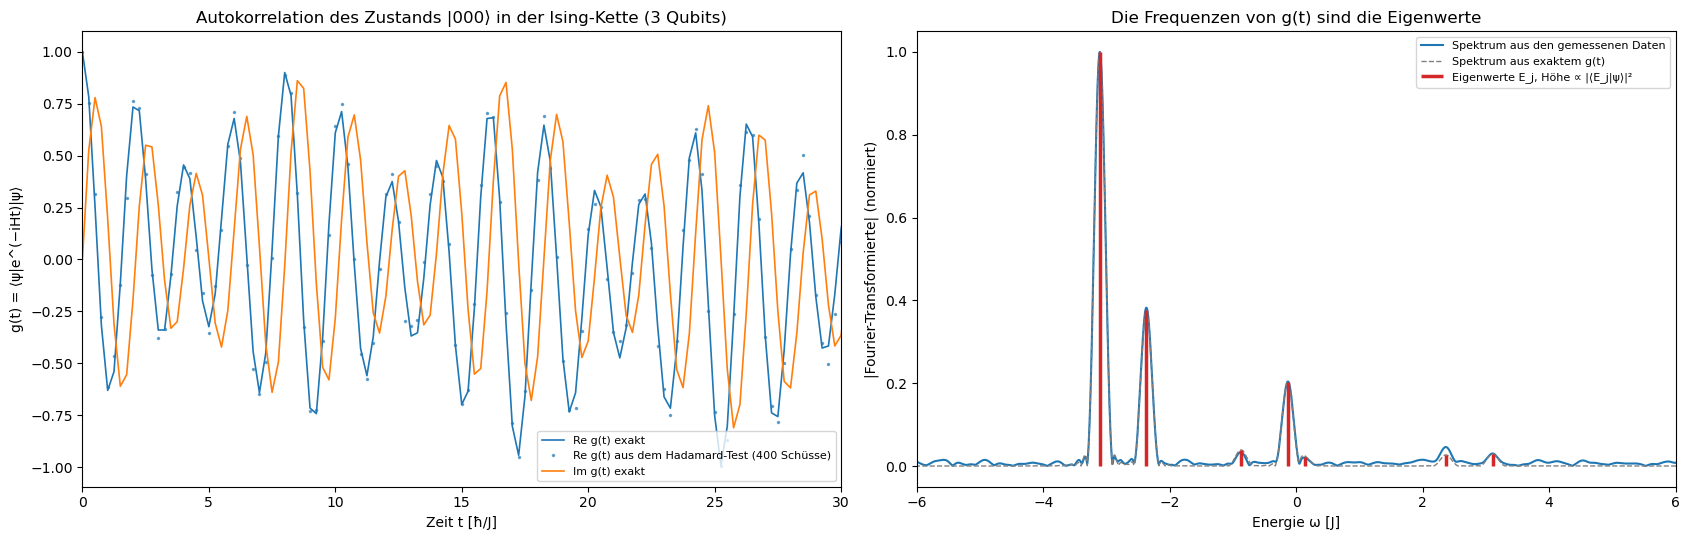

In [16]:
n15 = 3
H15 = (-sum(operator_kette({i: PAULI_Z, i + 1: PAULI_Z}, n15) for i in range(n15 - 1))
       - 0.8 * sum(operator_kette({i: PAULI_X}, n15) for i in range(n15)) - 0.3 * operator_kette({0: PAULI_Z}, n15))
E15, V15 = np.linalg.eigh(H15)
psi15 = np.zeros(2**n15, dtype=complex); psi15[0] = 1.0                   # |000⟩
c15 = np.abs(V15.conj().T @ psi15)**2
print("Eigenwerte von H:", np.round(E15, 4))
print("Gewichte |⟨E_j|000⟩|²:", np.round(c15, 4))

# Hadamard-Test, einmal als echte Schaltung: Hilfsqubit |+⟩, kontrolliertes U, H, messen. P(0) = (1 + Re⟨ψ|U|ψ⟩)/2.
t_test = 0.7
U_test = expm(-1j * H15 * t_test)
dim15 = 2**n15
CU = np.block([[np.eye(dim15), np.zeros((dim15, dim15))], [np.zeros((dim15, dim15)), U_test]])
for name, S_gate in [("Re", np.eye(2)), ("Im", np.diag([1, -1j]))]:
    z = np.kron(HADAMARD @ np.array([1, 0]), psi15)
    z = CU @ z
    z = np.kron(HADAMARD @ S_gate, np.eye(dim15)) @ z
    p0 = np.sum(np.abs(z[:dim15])**2)
    wert = np.vdot(psi15, U_test @ psi15)
    print(f"Hadamard-Test ({name}) bei t = {t_test}: 2 P(0) − 1 = {2 * p0 - 1:+.6f}, "
          f"{name}⟨ψ|U|ψ⟩ = {(wert.real if name == 'Re' else wert.imag):+.6f}")

dt15, K15, schuesse15 = 0.25, 256, 400
t15 = dt15 * np.arange(K15)
g_exakt = np.array([np.vdot(psi15, V15 @ (np.exp(-1j * E15 * t) * (V15.conj().T @ psi15))) for t in t15])
re_mess = 2 * rng.binomial(schuesse15, np.clip((1 + g_exakt.real) / 2, 0, 1)) / schuesse15 - 1   # P(0) beim Hadamard-Test
im_mess = 2 * rng.binomial(schuesse15, np.clip((1 + g_exakt.imag) / 2, 0, 1)) / schuesse15 - 1
g_mess = re_mess + 1j * im_mess
print(f"{K15} Zeitpunkte, Δt = {dt15}, je {schuesse15} Schüsse für Re und Im; Messrauschen pro Punkt {np.std(g_mess - g_exakt):.3f}")
nfft15 = 2**14
fenster15 = np.hanning(K15)
omega15 = -2 * np.pi * np.fft.fftshift(np.fft.fftfreq(nfft15, dt15))     # Vorzeichen: g(t) = Σ|c|² e^(−iEt)
spek_exakt = np.abs(np.fft.fftshift(np.fft.fft(g_exakt * fenster15, nfft15)))
spek_mess = np.abs(np.fft.fftshift(np.fft.fft(g_mess * fenster15, nfft15)))
spitzen15, _ = find_peaks(spek_mess, height=0.15 * spek_mess.max())
gefunden = np.sort(omega15[spitzen15])
print(f"Auflösung 2π/(K Δt) = {2 * np.pi / (K15 * dt15):.3f}, Nyquist-Grenze ±π/Δt = ±{np.pi / dt15:.2f}")
print("Spitzen des gemessenen Spektrums bei ω =", np.round(gefunden, 3))
sichtbar = E15[c15 > 0.05]
print("Eigenwerte mit Gewicht über 5 %:       ", np.round(np.sort(sichtbar), 3))

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
ax = axes[0]
ax.plot(t15, g_exakt.real, color="tab:blue", lw=1.2, label="Re g(t) exakt")
ax.plot(t15, re_mess, ".", ms=3, color="tab:blue", alpha=0.6, label=f"Re g(t) aus dem Hadamard-Test ({schuesse15} Schüsse)")
ax.plot(t15, g_exakt.imag, color="tab:orange", lw=1.2, label="Im g(t) exakt")
ax.set_xlim(0, 30); ax.set_xlabel("Zeit t [ħ/J]"); ax.set_ylabel("g(t) = ⟨ψ|e^(−iHt)|ψ⟩")
ax.set_title("Autokorrelation des Zustands |000⟩ in der Ising-Kette (3 Qubits)"); ax.legend(fontsize=8, loc="lower right")
ax = axes[1]
ax.plot(omega15, spek_mess / spek_mess.max(), color="tab:blue", label="Spektrum aus den gemessenen Daten")
ax.plot(omega15, spek_exakt / spek_exakt.max(), color="0.5", ls="--", lw=1, label="Spektrum aus exaktem g(t)")
ax.vlines(E15, 0, c15 / c15.max(), color="tab:red", lw=2.5, label="Eigenwerte E_j, Höhe ∝ |⟨E_j|ψ⟩|²")
ax.set_xlim(-6, 6); ax.set_xlabel("Energie ω [J]"); ax.set_ylabel("|Fourier-Transformierte| (normiert)")
ax.set_title("Die Frequenzen von g(t) sind die Eigenwerte"); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

* Die echte Schaltung mit Hilfsqubit gibt bei $t = 0.7$ die Werte $2P(0) - 1 = -0.214546$ und $+0.699381$, genau Real- und Imaginärteil von $\langle\psi\vert e^{-iHt}\vert\psi\rangle$. Für die Zeitreihe wird deshalb nur noch $P(0)$ ausgerechnet und mit 400 Schüssen gewürfelt.
* Das **linke Bild** zeigt die ersten 30 Zeiteinheiten der Autokorrelation, exakt (Linien) und aus dem simulierten Hadamard-Test (Punkte, nur der Realteil). Das Signal ist eine unregelmäßige Schwingung; das Messrauschen pro Punkt ist 0.06, sichtbar als Streuung der Punkte um die Kurve.
* Das **rechte Bild** zeigt den Betrag der Fourier-Transformation. Die drei großen Spitzen liegen bei $-3.106$, $-2.370$ und $-0.132$; die Eigenwerte mit Gewicht über 5 % sind $-3.107$ (Gewicht 0.59), $-2.368$ (0.22) und $-0.135$ (0.12). Die Abweichungen von höchstens 0.003 sind viel kleiner als die Auflösung $2\pi/(K\Delta t) = 0.098$, weil jede Spitze für sich gut bestimmt ist. Die kleinen Spitzen bei $-0.873$, $2.368$ und $3.107$ (Gewichte 1.6 bis 2.3 %) heben sich gerade noch vom Rauschen ab. Der Eigenwert $+0.135$ (1.3 %) liegt nur 0.27 neben der großen Spitze bei $-0.135$ und ist kaum zu trennen, $0.873$ hat praktisch kein Gewicht ($10^{-4}$). Die Höhen der Spitzen folgen den Gewichten $\vert\langle E_j\vert000\rangle\vert^2$ (rote Striche).
* So misst man Eigenwerte, ohne Eigenzustände zu kennen: Man braucht einen Anfangszustand mit genug Überlapp und die kontrollierte Zeitentwicklung. Die Kosten wachsen mit der gewünschten Auflösung (längere Zeiten) und der Genauigkeit pro Punkt (mehr Schüsse).

##### *16. Quantenphasenschätzung (QPE)*

Wie genau liest die Phasenschätzung einen Eigenwert ab, was passiert, wenn die Phase nicht auf das Gitter passt oder die Eingabe kein Eigenzustand ist, und warum ist sie besser als der wiederholte Hadamard-Test? Vorher überlegen: Mit $t$ Register-Qubits gibt es $2^t$ mögliche Ergebnisse. Wie viele Anwendungen von $U$ kostet das, und welcher Fehler ist zu erwarten?

Drei Teile. (1) Die Verteilung der Registerwerte für $t = 5$ und die Phasen $\varphi = 10/32$ (auf dem Gitter), $10.4/32$ und $10.5/32$ (genau dazwischen). (2) Eine vollständige Zustandsvektor-Simulation mit $t = 7$ für eine zufällige unitäre 4×4-Matrix mit den Phasen 0.2, 0.65, 0.41, 0.87 und der Eingabe $\sqrt{0.7}\vert u_1\rangle + \sqrt{0.3}\vert u_2\rangle$; nach der Messung des Registers wird geprüft, in welchem Zustand das System ist. (3) Der Median des Phasenfehlers gegen die Zahl $M$ der Anwendungen von $U$: für den Hadamard-Test mit $M$ Schüssen (jeder wendet $U$ einmal an) und für QPE mit $t = 3$ bis $14$ ($M = 2^t - 1$), über 100 bzw. 300 zufällige Phasen.

**Hintergrund & Fachbegriffe:**
- **Phase eines Eigenwerts:** Eine unitäre Matrix hat Eigenwerte $e^{2\pi i\varphi}$ mit $\varphi\in[0, 1)$. Für $U = e^{iHt_0}$ ist $\varphi = Et_0/2\pi$ (modulo 1); aus der Phase folgt also der Eigenwert von $H$.
- **QPE-Schaltung:** $t$ Register-Qubits in $\vert+\rangle$; Qubit $i$ steuert $U^{2^i}$. Danach steht im Register $\frac1{\sqrt T}\sum_ke^{2\pi i\varphi k}\vert k\rangle$ mit $T = 2^t$, und die **inverse Quanten-Fourier-Transformation** macht daraus einen Zustand, der um $\vert\varphi T\rangle$ konzentriert ist. Die Messung gibt $j$, die Schätzung ist $j/T$.
- **Fejér-Kern:** Mit $\delta = \varphi - j/T$ ist $P(j) = \frac{\sin^2(\pi T\delta)}{T^2\sin^2(\pi\delta)}$. Liegt $\varphi$ auf dem Gitter, ist das Ergebnis sicher; sonst trifft man den nächsten Gitterwert mit Wahrscheinlichkeit mindestens $4/\pi^2\approx0.405$ und einen der beiden nächsten mit mindestens $8/\pi^2\approx0.81$.
- **QPE als Messung:** Ist die Eingabe $\sum_kc_k\vert u_k\rangle$, gibt das Register mit Wahrscheinlichkeit $\vert c_k\vert^2$ einen Wert nahe $\varphi_k$, und das System ist danach (nahezu) im Eigenzustand $\vert u_k\rangle$: eine projektive Messung von $U$ in seiner Eigenbasis.
- **Standardquantengrenze und Heisenberg-Grenze:** Mit $M$ unabhängigen Anwendungen (Hadamard-Test) fällt der Fehler wie $1/\sqrt M$, weil man Häufigkeiten schätzt. QPE wendet $U$ kohärent hintereinander an ($U^{2^i}$ sammelt die Phase $2^i\varphi$) und erreicht $1/M$, die bestmögliche Skalierung.

φ = 10.0/32: P(nächster Gitterwert) = 1.0000, P(einer der zwei nächsten) = 1.0000
φ = 10.4/32: P(nächster Gitterwert) = 0.5731, P(einer der zwei nächsten) = 0.8279
φ = 10.5/32: P(nächster Gitterwert) = 0.4056, P(einer der zwei nächsten) = 0.8112
untere Schranke 4/π² = 0.4053 für den nächsten, 8/π² = 0.8106 für die zwei nächsten
Register zeigt 26/128 = 0.2031 (Phase 0.2): Wahrscheinlichkeit um die Spitze 0.663 (|c|² = 0.7), Überlapp des Systems danach mit dem Eigenvektor 0.999984
Register zeigt 83/128 = 0.6484 (Phase 0.65): Wahrscheinlichkeit um die Spitze 0.294 (|c|² = 0.3), Überlapp des Systems danach mit dem Eigenvektor 0.999849


Fehler gegen Zahl der Anwendungen von U: Hadamard-Test ∝ M^-0.51, QPE ∝ M^-0.99
  bei etwa 16 000 Anwendungen: Hadamard-Test 1.1e-03, QPE (t = 14) 1.7e-05


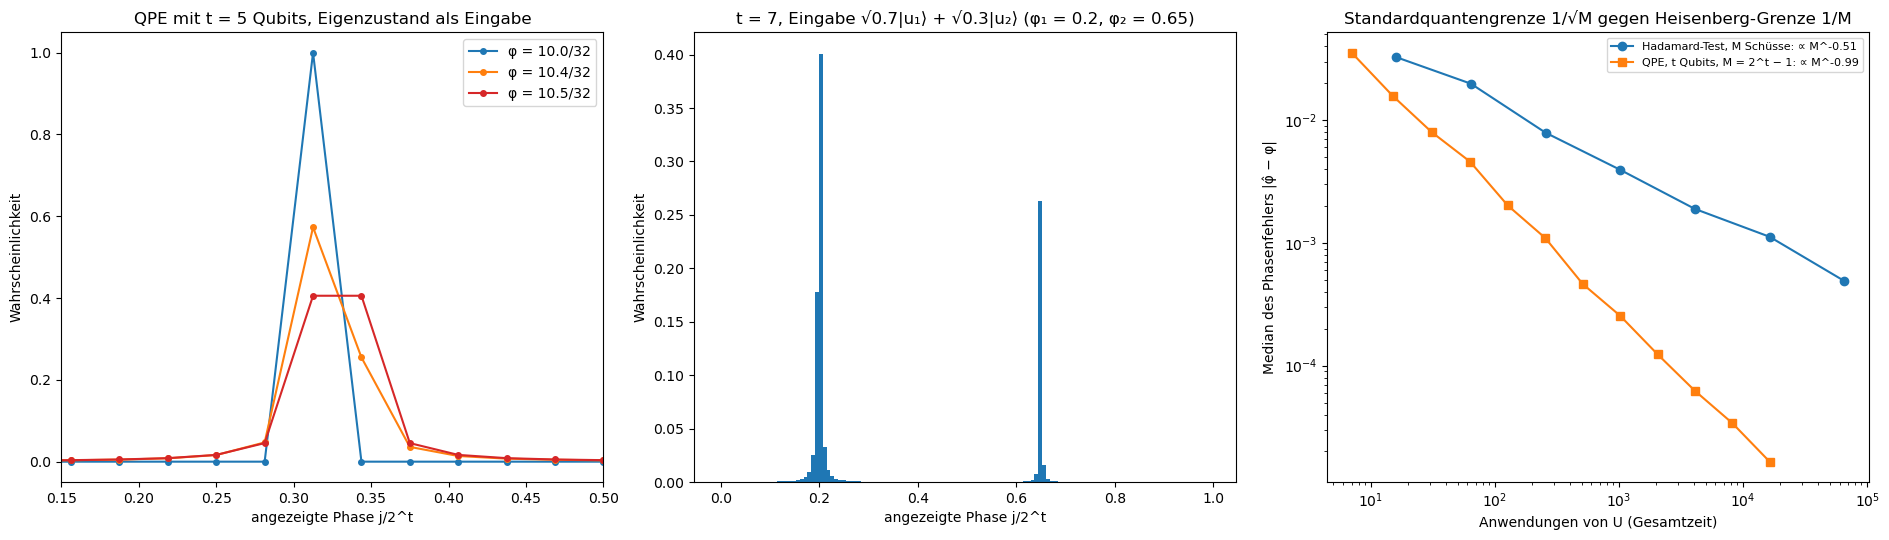

In [17]:
t16 = 5
T16 = 2**t16
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
ax = axes[0]
for phi, farbe in [(10 / T16, "tab:blue"), (10.4 / T16, "tab:orange"), (10.5 / T16, "tab:red")]:
    p = qpe_verteilung(phi, t16)
    ax.plot(np.arange(T16) / T16, p, "o-", ms=4, color=farbe, label=f"φ = {phi * T16:.1f}/32")
    naechst = int(np.round(phi * T16)) % T16
    print(f"φ = {phi * T16:.1f}/32: P(nächster Gitterwert) = {p[naechst]:.4f}, P(einer der zwei nächsten) = "
          f"{np.sort(p)[-2:].sum():.4f}")
print(f"untere Schranke 4/π² = {4 / np.pi**2:.4f} für den nächsten, 8/π² = {8 / np.pi**2:.4f} für die zwei nächsten")
ax.set_xlim(0.15, 0.5); ax.set_xlabel("angezeigte Phase j/2^t"); ax.set_ylabel("Wahrscheinlichkeit")
ax.set_title(f"QPE mit t = {t16} Qubits, Eigenzustand als Eingabe"); ax.legend()

# Überlagerung zweier Eigenzustände: die Messung des Registers wählt einen aus
phasen16 = np.array([0.2, 0.65, 0.41, 0.87])
Q16 = zufalls_unitaer(4, rng)
U16 = (Q16 * np.exp(2j * np.pi * phasen16)) @ Q16.conj().T
psi16 = np.sqrt(0.7) * Q16[:, 0] + np.sqrt(0.3) * Q16[:, 1]
zustand16 = phasenschaetzung(U16, psi16, 7)
p16 = np.sum(np.abs(zustand16)**2, axis=1)
ax = axes[1]
ax.bar(np.arange(128) / 128, p16, width=1 / 128, color="tab:blue")
for j0, k in [(int(np.argmax(p16[:64])), 0), (64 + int(np.argmax(p16[64:])), 1)]:
    nach = zustand16[j0] / np.linalg.norm(zustand16[j0])
    masse = p16[max(j0 - 3, 0):j0 + 4].sum()
    print(f"Register zeigt {j0}/128 = {j0 / 128:.4f} (Phase {phasen16[k]}): Wahrscheinlichkeit um die Spitze {masse:.3f}"
          f" (|c|² = {[0.7, 0.3][k]}), Überlapp des Systems danach mit dem Eigenvektor {abs(np.vdot(Q16[:, k], nach))**2:.6f}")
ax.set_xlabel("angezeigte Phase j/2^t"); ax.set_ylabel("Wahrscheinlichkeit")
ax.set_title("t = 7, Eingabe √0.7|u₁⟩ + √0.3|u₂⟩ (φ₁ = 0.2, φ₂ = 0.65)")

# Kosten gegen Genauigkeit: Hadamard-Test mit U allein gegen QPE mit U^(2^i)
ax = axes[2]
phis = rng.random(300)
kosten_h, fehler_h, kosten_q, fehler_q = [], [], [], []
for M in [16, 64, 256, 1024, 4096, 16384, 65536]:
    f = []
    for phi in phis[:100]:
        re = 2 * rng.binomial(M // 2, (1 + np.cos(2 * np.pi * phi)) / 2) / (M // 2) - 1
        im = 2 * rng.binomial(M // 2, (1 + np.sin(2 * np.pi * phi)) / 2) / (M // 2) - 1
        d = (np.arctan2(im, re) / (2 * np.pi) - phi + 0.5) % 1 - 0.5
        f.append(abs(d))
    kosten_h.append(M); fehler_h.append(np.median(f))
for t in range(3, 15):
    f = []
    for phi in phis:
        j = rng.choice(2**t, p=qpe_verteilung(phi, t))
        f.append(abs((j / 2**t - phi + 0.5) % 1 - 0.5))
    kosten_q.append(2**t - 1); fehler_q.append(np.median(f))
st_h = np.polyfit(np.log(kosten_h), np.log(fehler_h), 1)[0]
st_q = np.polyfit(np.log(kosten_q), np.log(fehler_q), 1)[0]
print(f"Fehler gegen Zahl der Anwendungen von U: Hadamard-Test ∝ M^{st_h:.2f}, QPE ∝ M^{st_q:.2f}")
print(f"  bei etwa 16 000 Anwendungen: Hadamard-Test {fehler_h[5]:.1e}, QPE (t = 14) {fehler_q[-1]:.1e}")
ax.loglog(kosten_h, fehler_h, "o-", label=f"Hadamard-Test, M Schüsse: ∝ M^{st_h:.2f}")
ax.loglog(kosten_q, fehler_q, "s-", label=f"QPE, t Qubits, M = 2^t − 1: ∝ M^{st_q:.2f}")
ax.set_xlabel("Anwendungen von U (Gesamtzeit)"); ax.set_ylabel("Median des Phasenfehlers |φ̂ − φ|")
ax.set_title("Standardquantengrenze 1/√M gegen Heisenberg-Grenze 1/M"); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

* Das **linke Bild** zeigt die Verteilung der Registerwerte für drei Phasen. Bei $\varphi = 10/32$ ist das Ergebnis sicher (Wahrscheinlichkeit 1.0000). Bei $10.4/32$ trifft man den nächsten Gitterwert mit 0.573 und einen der beiden nächsten mit 0.828. Bei $10.5/32$, genau zwischen zwei Gitterwerten, ist es mit 0.406 und 0.811 der ungünstigste Fall, gerade über den Schranken $4/\pi^2 = 0.405$ und $8/\pi^2 = 0.811$. Dazu kommen kleine Ausläufer zu weiter entfernten Werten (Fejér-Kern); für eine zuverlässige Schätzung nimmt man deshalb einige Register-Qubits mehr oder wiederholt und nimmt den Median.
* Das **mittlere Bild** zeigt die vollständig simulierte QPE mit $t = 7$ für die Überlagerung zweier Eigenzustände. Es gibt zwei Gruppen von Ergebnissen, um 0.2 und um 0.65, mit den Wahrscheinlichkeiten 0.663 und 0.294 in den sieben Registerwerten um jede Spitze; erwartet sind 0.7 und 0.3, der Rest liegt in den Ausläufern. Nach dem Ergebnis $26/128 = 0.203$ ist das System zu 0.999984 im Eigenzustand $\vert u_1\rangle$, nach $83/128 = 0.648$ zu 0.999849 in $\vert u_2\rangle$. QPE misst also nicht nur den Eigenwert, sondern präpariert auch den Eigenzustand.
* Das **rechte Bild** zeigt den Median des Phasenfehlers gegen die Zahl der Anwendungen von $U$. Beim Hadamard-Test fällt er wie $M^{-0.51}$, bei QPE wie $M^{-0.99}$. Bei etwa 16 000 Anwendungen ist QPE rund 65-mal genauer ($1.7\cdot10^{-5}$ gegen $1.1\cdot10^{-3}$). Der Preis: QPE braucht $U^{2^{13}}$ als zusammenhängende, kohärente Schaltung und einen Eigenzustand oder guten Überlapp als Eingabe; deshalb ist sie ein Algorithmus für fehlerkorrigierte Quantencomputer.

##### *17. HHL: lineare Gleichungssysteme über die Eigenwerte*

Wie löst der HHL-Algorithmus $A\mathbf x = \mathbf b$, wovon hängt seine Genauigkeit ab, und wie wahrscheinlich ist ein Erfolg? Vorher überlegen: In der Eigenbasis ist $A^{-1}$ einfach. Was muss man mit jeder Komponente von $\mathbf b$ tun?

HHL wird als Zustandsvektor vollständig simuliert: QPE mit $U = e^{iAt_0}$ und $t$ Register-Qubits, Drehung eines Hilfsqubits um $C/\tilde\lambda$, QPE rückwärts, dann Nachweis von Hilfsqubit $= 1$ und Register $= 0$. Drei Matrizen: eine 4×4-Matrix mit den Eigenwerten 1, 2, 3, 4 (sie passen mit $t_0 = 2\pi/8$ genau auf das Gitter), eine 4×4-Matrix mit zufälligen Eigenwerten in $[1, 4]$ und die 8×8-Matrix $\mathrm{tridiag}(-1, 2, -1)$ der Poisson-Gleichung $-u'' = 1$ auf acht inneren Gitterpunkten mit Randwerten null. Gemessen werden die Treue $\vert\langle x\vert\tilde x\rangle\vert^2$ zur exakten normierten Lösung und die Erfolgswahrscheinlichkeit, für $t = 3$ bis 10.

**Hintergrund & Fachbegriffe:**
- **Idee:** $A^{-1} = \sum_j\lambda_j^{-1}\vert u_j\rangle\langle u_j\vert$. Mit $\vert b\rangle = \sum_j\beta_j\vert u_j\rangle$ ist $A^{-1}\vert b\rangle = \sum_j\frac{\beta_j}{\lambda_j}\vert u_j\rangle$: Jede Eigenkomponente wird durch ihren Eigenwert geteilt. Dazu muss man $\lambda_j$ kennen, ohne $\vert u_j\rangle$ zu kennen; das leistet die QPE.
- **Ablauf:** (1) QPE: $\sum_j\beta_j\vert\tilde\lambda_j\rangle\vert u_j\rangle$. (2) Ein Hilfsqubit wird abhängig vom Register gedreht: $\sqrt{1 - C^2/\tilde\lambda^2}\,\vert0\rangle + \frac C{\tilde\lambda}\vert1\rangle$ mit $C\le\lambda_{\min}$. (3) QPE rückwärts setzt das Register auf $\vert0\rangle$ zurück. (4) Wird das Hilfsqubit als 1 gemessen, ist das System $\propto\sum_j\beta_j\frac C{\lambda_j}\vert u_j\rangle\propto A^{-1}\vert b\rangle$.
- **Erfolgswahrscheinlichkeit und Kondition:** $p = \Vert CA^{-1}\mathbf b\Vert^2$ für normiertes $\mathbf b$, im ungünstigsten Fall $(\lambda_{\min}/\lambda_{\max})^2 = 1/\kappa^2$ mit der **Konditionszahl** $\kappa = \lambda_{\max}/\lambda_{\min}$. Mit Amplitudenverstärkung braucht man etwa $\kappa$ statt $\kappa^2$ Wiederholungen.
- **Ausgabe:** Das Ergebnis ist der Quantenzustand $\vert x\rangle$ mit $2^n$ Amplituden, nicht der Vektor $\mathbf x$. Man kann ihn weiterverarbeiten oder Erwartungswerte $\langle x\vert M\vert x\rangle$ messen; alle Einträge auszulesen kostet so viele Wiederholungen, dass jeder Vorteil verschwindet.
- **Poisson-Gleichung:** $-u'' = f$ mit $u(0) = u(1) = 0$. Mit zentralen Differenzen und $h = 1/9$ wird daraus $A\mathbf u = h^2\mathbf f$ mit $A = \mathrm{tridiag}(-1, 2, -1)$. Die Eigenwerte $2 - 2\cos(k\pi/9)$ liegen zwischen 0.12 und 3.88, und $\kappa$ wächst wie $N^2$ mit der Zahl $N$ der Gitterpunkte.

Poisson: Eigenwerte [0.1206 0.4679 1.     1.6527 2.3473 3.     3.5321 3.8794], Kondition κ = 32.2
A (zufällig): Eigenwerte [1.7659 3.0744 3.3689 3.4622]
A mit Eigenwerten 1, 2, 3, 4: 1 − Treue für t = 3 … 10: 4e-16, 0e+00, 2e-16, 0e+00, 0e+00, 0e+00, 2e-16, 0e+00; Erfolgswahrscheinlichkeit bei t = 10: 0.4991
    erwartet für ideales HHL: Σ|β_j|²(C/λ_j)² = ‖C A⁻¹ b‖² = 0.4991
A mit zufälligen Eigenwerten in [1, 4]: 1 − Treue für t = 3 … 10: 6e-04, 8e-05, 1e-05, 5e-06, 4e-06, 1e-06, 8e-08, 5e-09; Erfolgswahrscheinlichkeit bei t = 10: 0.0905
    erwartet für ideales HHL: Σ|β_j|²(C/λ_j)² = ‖C A⁻¹ b‖² = 0.0904
Poisson-Matrix 8×8 (3 Qubits): 1 − Treue für t = 3 … 10: 1e+00, 7e-01, 2e-02, 2e-06, 3e-06, 3e-06, 2e-06, 1e-07; Erfolgswahrscheinlichkeit bei t = 10: 0.7103
    erwartet für ideales HHL: Σ|β_j|²(C/λ_j)² = ‖C A⁻¹ b‖² = 0.7247


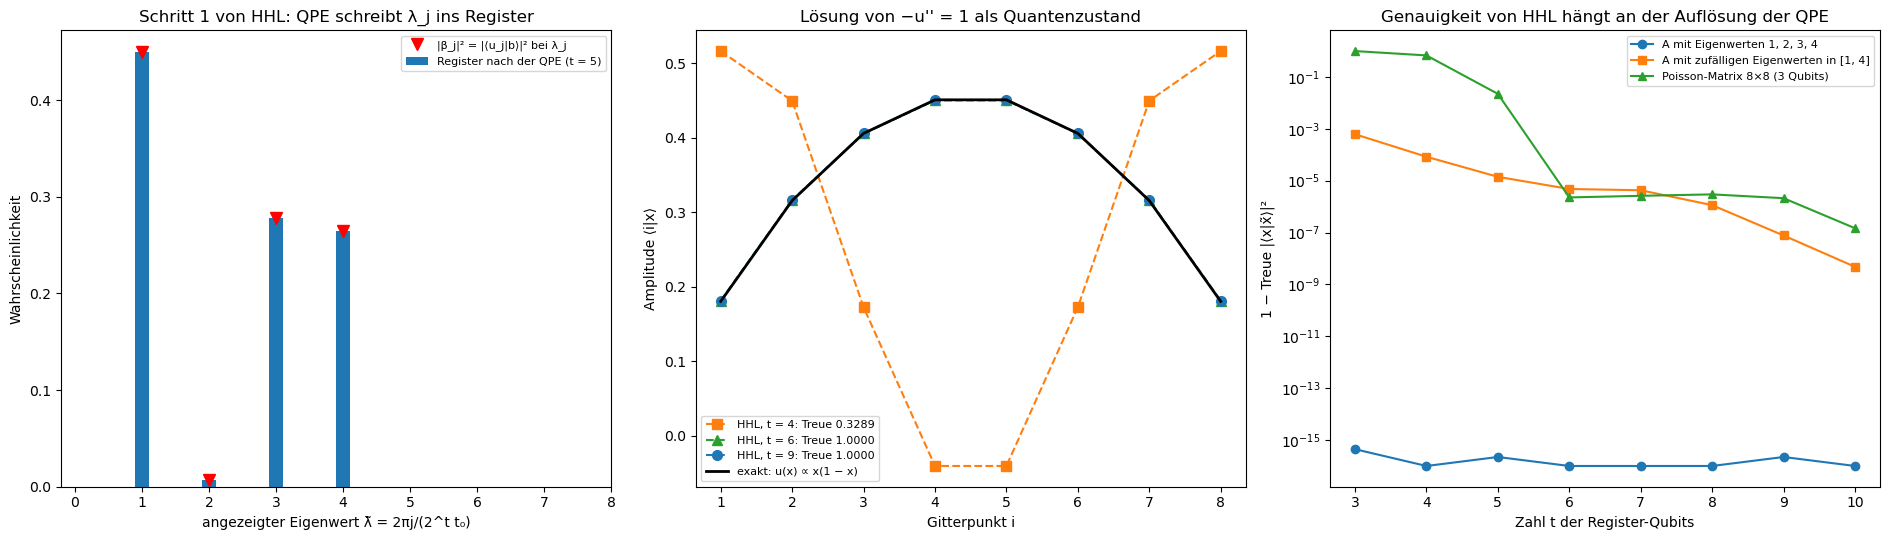

In [18]:
def hhl(A, b, t, t0, C):
    """HHL als Zustandsvektor: QPE mit U = e^(iAt0), Drehung des Hilfsqubits um C/λ̃, QPE rückwärts, Hilfsqubit = 1
    und Register = 0 nachweisen. Rückgabe: normierter Lösungszustand, Erfolgswahrscheinlichkeit, Registerverteilung."""
    T = 2**t
    U = expm(1j * A * t0)
    b = b / np.linalg.norm(b)
    z = phasenschaetzung(U, b, t)
    lam_schaetz = 2 * np.pi * np.arange(T) / (T * t0)                      # Registerwert j → λ̃ = 2πj/(T t0)
    amplitude = np.zeros(T)
    amplitude[1:] = np.minimum(1.0, C / lam_schaetz[1:])                    # Hilfsqubit: |0⟩ → √(1 − (C/λ̃)²)|0⟩ + C/λ̃ |1⟩
    x = phasenschaetzung_rueckwaerts(z * amplitude[:, None], U)
    p_erfolg = np.linalg.norm(x)**2
    return x / np.linalg.norm(x), p_erfolg, np.sum(np.abs(z)**2, axis=1)


def treue(x_quanten, A, b):
    x = np.linalg.solve(A, b)
    return abs(np.vdot(x / np.linalg.norm(x), x_quanten))**2


A_dyad = mit_spektrum([1.0, 2.0, 3.0, 4.0], rng)                            # exakt darstellbare Eigenwerte
A_zuf = mit_spektrum(rng.uniform(1.0, 4.0, 4), rng)
n_p = 8
A_pois = 2 * np.eye(n_p) - np.eye(n_p, k=1) - np.eye(n_p, k=-1)           # −u'' auf 8 inneren Punkten (·h²)
b4 = rng.standard_normal(4)
b_pois = np.ones(n_p)                                                       # konstante Quelle f = 1
ew_pois = np.linalg.eigvalsh(A_pois)
print(f"Poisson: Eigenwerte {np.round(ew_pois, 4)}, Kondition κ = {ew_pois[-1] / ew_pois[0]:.1f}")
print(f"A (zufällig): Eigenwerte {np.round(np.linalg.eigvalsh(A_zuf), 4)}")
faelle = {"A mit Eigenwerten 1, 2, 3, 4": (A_dyad, b4, 2 * np.pi / 8, 1.0),
          "A mit zufälligen Eigenwerten in [1, 4]": (A_zuf, b4, 2 * np.pi / 8, 1.0),
          "Poisson-Matrix 8×8 (3 Qubits)": (A_pois, b_pois, np.pi / 4, 0.9 * ew_pois[0])}
ergebnis17 = {}
for name, (A, b, t0, C) in faelle.items():
    werte = []
    for t in range(3, 11):
        xq, p, _ = hhl(A, b, t, t0, C)
        werte.append((t, 1 - treue(xq, A, b), p))
    ergebnis17[name] = np.array(werte)
    print(f"{name}: 1 − Treue für t = 3 … 10: " + ", ".join(f"{w[1]:.0e}" for w in werte)
          + f"; Erfolgswahrscheinlichkeit bei t = 10: {werte[-1][2]:.4f}")
    x_klass = np.linalg.solve(A, b / np.linalg.norm(b))
    print(f"    erwartet für ideales HHL: Σ|β_j|²(C/λ_j)² = ‖C A⁻¹ b‖² = {np.linalg.norm(C * x_klass)**2:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
ax = axes[0]
_, _, reg = hhl(A_dyad, b4, 5, 2 * np.pi / 8, 1.0)
beta2 = np.abs(np.linalg.eigh(A_dyad)[1].T @ (b4 / np.linalg.norm(b4)))**2
ax.bar(2 * np.pi * np.arange(32) / (32 * 2 * np.pi / 8), reg, width=0.2, label="Register nach der QPE (t = 5)")
ax.plot(np.linalg.eigvalsh(A_dyad), beta2, "rv", ms=9, label="|β_j|² = |⟨u_j|b⟩|² bei λ_j")
ax.set_xlabel("angezeigter Eigenwert λ̃ = 2πj/(2^t t₀)"); ax.set_ylabel("Wahrscheinlichkeit")
ax.set_title("Schritt 1 von HHL: QPE schreibt λ_j ins Register"); ax.legend(fontsize=8); ax.set_xlim(-0.2, 8)
ax = axes[1]
x_exakt = np.linalg.solve(A_pois, b_pois); x_exakt /= np.linalg.norm(x_exakt)
for t, m, farbe in [(4, "s", "tab:orange"), (6, "^", "tab:green"), (9, "o", "tab:blue")]:
    xq, p, _ = hhl(A_pois, b_pois, t, np.pi / 4, 0.9 * ew_pois[0])
    xq = xq * np.exp(-1j * np.angle(np.vdot(x_exakt, xq)))
    ax.plot(np.arange(1, n_p + 1), xq.real, m + "--", color=farbe, ms=7, label=f"HHL, t = {t}: Treue {treue(xq, A_pois, b_pois):.4f}")
ax.plot(np.arange(1, n_p + 1), x_exakt, "k-", lw=2, label="exakt: u(x) ∝ x(1 − x)")
ax.set_xlabel("Gitterpunkt i"); ax.set_ylabel("Amplitude ⟨i|x⟩"); ax.legend(fontsize=8)
ax.set_title("Lösung von −u'' = 1 als Quantenzustand")
ax = axes[2]
for (name, w), m in zip(ergebnis17.items(), ["o", "s", "^"]):
    ax.semilogy(w[:, 0], np.maximum(w[:, 1], 1e-16), m + "-", label=name)
ax.set_xlabel("Zahl t der Register-Qubits"); ax.set_ylabel("1 − Treue |⟨x|x̃⟩|²")
ax.set_title("Genauigkeit von HHL hängt an der Auflösung der QPE"); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

* Das **linke Bild** zeigt das Register nach dem QPE-Schritt für die Matrix mit den Eigenwerten 1, 2, 3, 4 und ein zufälliges $\mathbf b$. Die Balken stehen genau bei den Eigenwerten, und ihre Höhen sind $\vert\beta_j\vert^2 = \vert\langle u_j\vert b\rangle\vert^2$ (rote Dreiecke): Die QPE hat $\vert b\rangle$ nach Eigenwerten zerlegt. In diesem Fall ist die HHL-Lösung für jedes $t\ge3$ exakt ($1 - $ Treue unter $10^{-15}$), weil alle Eigenwerte auf das Gitter passen; die Erfolgswahrscheinlichkeit 0.4991 ist genau $\Vert CA^{-1}\mathbf b\Vert^2$.
* Das **mittlere Bild** zeigt die HHL-Lösung der Poisson-Gleichung als Amplituden $\langle i\vert x\rangle$. Mit $t = 4$ Register-Qubits ist sie falsch (Treue 0.33): Der kleinste Eigenwert 0.12 ist kleiner als der Gitterabstand $2\pi/(16\,t_0) = 0.5$, landet beim Registerwert 0 und fällt weg, und damit fehlt die wichtigste Komponente der Lösung. Mit $t = 6$ und $t = 9$ liegt die Lösung auf der exakten Parabel $u\propto x(1 - x)$ (Treue 1.0000 auf vier Stellen).
* Das **rechte Bild** zeigt $1 - $ Treue gegen $t$. Die Matrix mit Gitter-Eigenwerten ist immer exakt. Bei zufälligen Eigenwerten fällt der Fehler von $6\cdot10^{-4}$ ($t = 3$) auf $5\cdot10^{-9}$ ($t = 10$). Bei der Poisson-Matrix ist HHL bis $t = 5$ unbrauchbar und ab $t = 6$ auf etwa $2\cdot10^{-6}$ genau, weil erst dann der kleinste Eigenwert aufgelöst wird; allgemein braucht man etwa $\log_2(\kappa/\varepsilon)$ Register-Qubits. Die Erfolgswahrscheinlichkeiten bei $t = 10$ sind 0.499, 0.091 und 0.710, nahe an den Idealwerten $\Vert CA^{-1}\mathbf b\Vert^2$ (0.499, 0.090, 0.725). Bei der Poisson-Matrix ist sie trotz $\kappa = 32$ hoch, weil die konstante Quelle fast ganz in der untersten Mode liegt, also in der Komponente, die durch den kleinsten Eigenwert geteilt wird.
* Was die Simulation nicht zeigt: Hier ist $\vert b\rangle$ einfach gegeben, $e^{iAt_0}$ wird exakt angewendet, und die Lösung wird als ganzer Vektor abgelesen. Auf einem Quantencomputer kostet jeder dieser Schritte, und ein exponentieller Vorteil bleibt nur, wenn alle drei effizient sind und nur eine Kenngröße der Lösung gebraucht wird (Theorie, Abschnitt 11).

##### *18. Variational Quantum Eigensolver (VQE)*

Kann man den kleinsten Eigenwert eines Hamilton-Operators mit kurzen Schaltungen finden, und was kostet das Messrauschen? Vorher überlegen: Kann ein VQE eine Energie unterhalb des wahren Grundzustands liefern?

Das Ising-Modell im Transversalfeld mit vier Qubits, $H = -\sum_iZ_iZ_{i+1} - h\sum_iX_i$ mit $h = 1$ und offenen Enden, hat $E_0 = -4.7588$. Der Ansatz ist ein Hardware-effizienter Schaltkreis: drei Lagen aus $R_Y$-Drehungen auf allen Qubits und einer CNOT-Leiter, dazu eine letzte $R_Y$-Lage, zusammen 16 Parameter. Optimiert wird einmal mit exakten Erwartungswerten (COBYLA, 3000 Auswertungen) und einmal mit simulierten Messungen: pro Energieschätzung 1000 Schüsse in der $Z$-Basis für $\sum Z_iZ_{i+1}$ und 1000 in der $X$-Basis für $\sum X_i$, Optimierer SPSA mit 600 Schritten. Zum Schluss die Einzelschüsse am Optimum und die Streuung der Energieschätzung gegen die Zahl der Schüsse.

**Hintergrund & Fachbegriffe:**
- **Variationsprinzip (Rayleigh–Ritz):** Für jeden normierten Zustand ist $\langle\psi\vert H\vert\psi\rangle\ge E_0$, mit Gleichheit nur im Grundzustand. Minimiert man den Erwartungswert über eine Familie $\vert\psi(\boldsymbol\theta)\rangle$, erhält man eine obere Schranke für $E_0$, die so gut ist wie die Familie.
- **Ansatz:** ein parametrisierter Schaltkreis $\vert\psi(\boldsymbol\theta)\rangle = U(\boldsymbol\theta)\vert0000\rangle$. $R_Y(\theta) = e^{-i\theta Y/2}$ dreht ein Qubit, CNOT-Gatter verschränken Nachbarn. Mit $R_Y$ allein bleiben die Amplituden reell; das reicht hier, weil $H$ reell ist.
- **Messung über die Pauli-Zerlegung:** $H = \sum_jc_jP_j$ mit Pauli-Strings $P_j$, die alle die Eigenwerte ±1 haben. Vertauschende Strings misst man gemeinsam: alle $Z_iZ_{i+1}$ in der Rechenbasis, alle $X_i$ nach einem Hadamard-Gatter auf jedem Qubit. Jeder Schuss liefert einen Eigenwert der gemessenen Summe, der Mittelwert schätzt den Erwartungswert.
- **Messrauschen:** Mit $n$ Schüssen pro Basis ist die Standardabweichung der Energieschätzung $\sqrt{(\mathrm{Var}\sum ZZ + h^2\mathrm{Var}\sum X)/n}$. Für Fehler von $10^{-3}$ braucht man schnell Millionen Schüsse pro Energie.
- **SPSA** (Simultaneous Perturbation Stochastic Approximation): schätzt den Gradienten aus nur zwei Energiemessungen bei $\boldsymbol\theta\pm c\boldsymbol\Delta$ mit zufälligen Vorzeichen $\boldsymbol\Delta$; robust gegen Rauschen und deshalb üblich für VQE auf echter Hardware. **COBYLA** ist ein ableitungsfreies Verfahren mit linearen Näherungen in einem Vertrauensbereich.

Ising-Kette mit 4 Spins, h = 1.0: E₀ = -4.758770, E₁ = -4.064178


VQE exakt (COBYLA): E = -4.758111, Fehler 6.6e-04, Überlapp mit dem Grundzustand 0.999879, 3000 Auswertungen


VQE mit SPSA und Schüssen: wahre Energie am Ende -4.7248 (Fehler 0.034)  Schüsse insgesamt 2 400 000
unter E₁ nach 14 Auswertungen (COBYLA) bzw. 38 Auswertungen (SPSA)
gemessene SPSA-Schätzungen unter E₀: 9 von 600; Streuung der Schätzungen in den letzten 100 Schritten 0.063
Variationsprinzip: kleinste wahre Energie aller Auswertungen -4.758111 ≥ E₀ = -4.758770
Einzelschüsse am Optimum: Σ Z_iZ_(i+1) ∈ [-3, -1, 1, 3], Σ X_i ∈ [-4, 0, 4]


Streuung der Energieschätzung: [0.7559 0.3731 0.2384 0.1346 0.0699 0.0371 0.0234]; Formel √((Var ZZ + Var X)/n) bei n = 1000: 0.0712


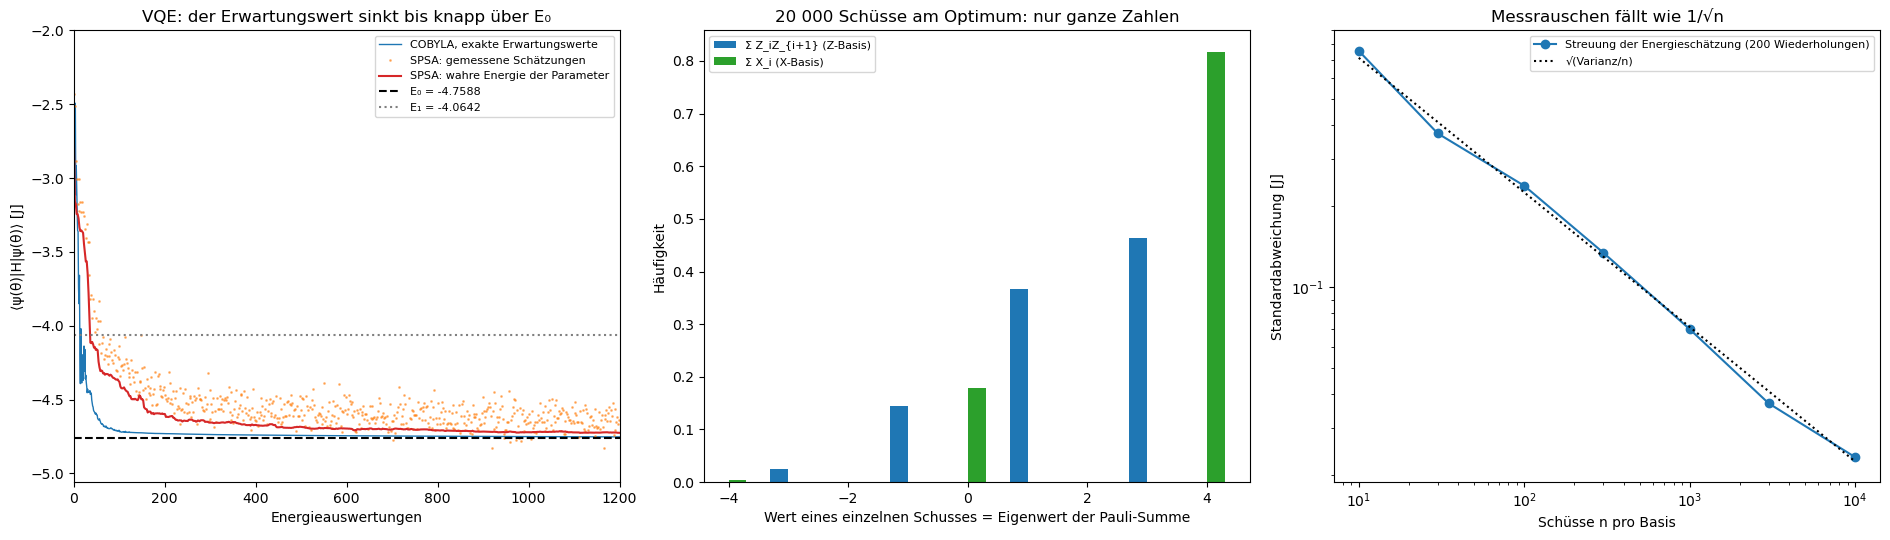

Laufzeit des ganzen Notebooks bis hier: 9 s


In [19]:
n18, h18 = 4, 1.0
H18 = (-sum(operator_kette({i: PAULI_Z, i + 1: PAULI_Z}, n18) for i in range(n18 - 1))
       - h18 * sum(operator_kette({i: PAULI_X}, n18) for i in range(n18))).real
E18 = np.linalg.eigvalsh(H18)
print(f"Ising-Kette mit 4 Spins, h = {h18}: E₀ = {E18[0]:.6f}, E₁ = {E18[1]:.6f}")
ZZ_diag = np.real(sum(np.diag(operator_kette({i: PAULI_Z, i + 1: PAULI_Z}, n18)) for i in range(n18 - 1)))  # Werte −3, −1, 1, 3
X_diag = np.real(sum(np.diag(operator_kette({i: PAULI_Z}, n18)) for i in range(n18)))                     # Σ Z nach Basiswechsel H
H_alle = operator_kette({i: HADAMARD for i in range(n18)}, n18).real
lagen18 = 3


def ansatz(theta):
    """RY-Drehungen auf allen Qubits, dann eine CNOT-Leiter, das Ganze 'lagen18'-mal, zum Schluss noch eine RY-Lage."""
    psi = np.zeros(2**n18); psi[0] = 1.0
    theta = theta.reshape(lagen18 + 1, n18)
    for lage in range(lagen18 + 1):
        psi = psi.reshape([2] * n18)
        for q in range(n18):
            c, s = np.cos(theta[lage, q] / 2), np.sin(theta[lage, q] / 2)
            psi = np.moveaxis(np.tensordot(np.array([[c, -s], [s, c]]), np.moveaxis(psi, q, 0), axes=1), 0, q)
        if lage < lagen18:
            for q in range(n18 - 1):                                      # CNOT q → q+1
                psi = psi.copy()
                idx = [slice(None)] * n18; idx[q] = 1
                psi[tuple(idx)] = np.flip(psi[tuple(idx)], axis=q)              # Ziel q+1 ist im Teilfeld Achse q
        psi = psi.reshape(-1)
    return psi


def energie_exakt(theta):
    psi = ansatz(theta)
    return psi @ H18 @ psi


def energie_schuesse(theta, n, rng, einzeln=False):
    """⟨H⟩ aus Messungen: n Schüsse in der Z-Basis für Σ Z_i Z_(i+1), n Schüsse nach H^⊗4 für Σ X_i. Jeder Schuss
    liefert einen Eigenwert der gemessenen Pauli-Summe."""
    psi = ansatz(theta)
    zz = ZZ_diag[rng.choice(2**n18, size=n, p=psi**2)]
    xx = X_diag[rng.choice(2**n18, size=n, p=(H_alle @ psi)**2)]
    if einzeln:
        return zz, xx
    return -zz.mean() - h18 * xx.mean()


theta0 = rng.uniform(-0.1, 0.1, (lagen18 + 1) * n18)
verlauf_exakt = []
res = minimize(lambda th: verlauf_exakt.append(energie_exakt(th)) or verlauf_exakt[-1], theta0, method="COBYLA",
               options={"maxiter": 3000, "rhobeg": 0.5, "tol": 1e-10})
psi_opt = ansatz(res.x)
grund = np.linalg.eigh(H18)[1][:, 0]
print(f"VQE exakt (COBYLA): E = {res.fun:.6f}, Fehler {res.fun - E18[0]:.1e}, Überlapp mit dem Grundzustand "
      f"{abs(grund @ psi_opt)**2:.6f}, {len(verlauf_exakt)} Auswertungen")

# SPSA mit Messrauschen: pro Schritt zwei Energieschätzungen mit je 1000 Schüssen pro Basis
theta, schuss_n = theta0.copy(), 1000
spsa_mess, spsa_wahr = [], []
for k in range(600):
    a_k, c_k = 0.3 / (k + 1 + 30)**0.602, 0.15 / (k + 1)**0.101
    delta = rng.choice([-1, 1], size=theta.size)
    e_plus = energie_schuesse(theta + c_k * delta, schuss_n, rng)
    e_minus = energie_schuesse(theta - c_k * delta, schuss_n, rng)
    theta = theta - a_k * (e_plus - e_minus) / (2 * c_k) * delta
    spsa_mess.append((e_plus + e_minus) / 2); spsa_wahr.append(energie_exakt(theta))
print(f"VQE mit SPSA und Schüssen: wahre Energie am Ende {spsa_wahr[-1]:.4f} (Fehler {spsa_wahr[-1] - E18[0]:.3f}), "
      f"Schüsse insgesamt {600 * 2 * 2 * schuss_n:,}".replace(",", " "))
unter_e1 = lambda f: next((k + 1 for k, w in enumerate(f) if w < E18[1]), None)
print(f"unter E₁ nach {unter_e1(verlauf_exakt)} Auswertungen (COBYLA) bzw. {2 * unter_e1(spsa_wahr)} Auswertungen (SPSA)")
print(f"gemessene SPSA-Schätzungen unter E₀: {np.sum(np.array(spsa_mess) < E18[0])} von {len(spsa_mess)}; "
      f"Streuung der Schätzungen in den letzten 100 Schritten {np.std(np.array(spsa_mess[-100:]) - np.array(spsa_wahr[-100:])):.3f}")
print(f"Variationsprinzip: kleinste wahre Energie aller Auswertungen {min(min(verlauf_exakt), min(spsa_wahr)):.6f} ≥ E₀ = {E18[0]:.6f}")
zz1, xx1 = energie_schuesse(res.x, 20000, rng, einzeln=True)
print(f"Einzelschüsse am Optimum: Σ Z_iZ_(i+1) ∈ {sorted(set(zz1.astype(int)))}, Σ X_i ∈ {sorted(set(xx1.astype(int)))}")
n_liste = np.array([10, 30, 100, 300, 1000, 3000, 10000])
streuung = [np.std([energie_schuesse(res.x, n, rng) for _ in range(200)]) for n in n_liste]
var_formel = np.var(zz1) + h18**2 * np.var(xx1)
print(f"Streuung der Energieschätzung: {np.round(streuung, 4)}; Formel √((Var ZZ + Var X)/n) bei n = 1000: "
      f"{np.sqrt(var_formel / 1000):.4f}")

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
ax = axes[0]
ax.plot(np.arange(1, len(verlauf_exakt) + 1), verlauf_exakt, color="tab:blue", lw=1, label="COBYLA, exakte Erwartungswerte")
ax.plot(np.arange(1, 1201, 2), spsa_mess, ".", ms=2, color="tab:orange", alpha=0.5, label="SPSA: gemessene Schätzungen")
ax.plot(np.arange(1, 1201, 2), spsa_wahr, color="tab:red", lw=1.5, label="SPSA: wahre Energie der Parameter")
ax.axhline(E18[0], color="k", ls="--", label=f"E₀ = {E18[0]:.4f}")
ax.axhline(E18[1], color="0.5", ls=":", label=f"E₁ = {E18[1]:.4f}")
ax.set_xlim(0, 1200); ax.set_ylim(E18[0] - 0.3, -2.0)
ax.set_xlabel("Energieauswertungen"); ax.set_ylabel("⟨ψ(θ)|H|ψ(θ)⟩ [J]"); ax.legend(fontsize=8)
ax.set_title("VQE: der Erwartungswert sinkt bis knapp über E₀")
ax = axes[1]
for werte, farbe, name in [(zz1, "tab:blue", "Σ Z_iZ_{i+1} (Z-Basis)"), (xx1, "tab:green", "Σ X_i (X-Basis)")]:
    u, c = np.unique(werte, return_counts=True)
    ax.bar(u + (0.15 if farbe == "tab:green" else -0.15), c / len(werte), width=0.3, color=farbe, label=name)
ax.set_xlabel("Wert eines einzelnen Schusses = Eigenwert der Pauli-Summe"); ax.set_ylabel("Häufigkeit")
ax.set_title("20 000 Schüsse am Optimum: nur ganze Zahlen"); ax.legend(fontsize=8)
ax = axes[2]
ax.loglog(n_liste, streuung, "o-", label="Streuung der Energieschätzung (200 Wiederholungen)")
ax.loglog(n_liste, np.sqrt(var_formel / n_liste), "k:", label="√(Varianz/n)")
ax.set_xlabel("Schüsse n pro Basis"); ax.set_ylabel("Standardabweichung [J]"); ax.legend(fontsize=8)
ax.set_title("Messrauschen fällt wie 1/√n")
plt.tight_layout()
plt.show()
print(f"Laufzeit des ganzen Notebooks bis hier: {time.time() - t_start:.0f} s")

* Das **linke Bild** zeigt die Energie gegen die Zahl der Energieauswertungen. COBYLA mit exakten Erwartungswerten (blau) fällt nach 14 Auswertungen unter die Energie $E_1 = -4.064$ des ersten angeregten Zustands und endet nach 3000 Auswertungen bei $-4.75811$, $6.6\cdot10^{-4}$ über $E_0$; der Überlapp mit dem Grundzustand ist 0.99988. SPSA mit Messrauschen (orange Punkte: die gemessenen Schätzungen, rot: die wahre Energie der aktuellen Parameter) ist nach 38 Auswertungen unter $E_1$, kommt danach langsamer voran und endet bei $-4.725$, 0.034 über $E_0$. Die gemessenen Werte streuen um etwa 0.06, und 9 von 600 liegen sogar unter $E_0$; die wahren Energien nie (die kleinste ist $-4.758111\ge E_0 = -4.758770$). Das Variationsprinzip gilt für Zustände, nicht für verrauschte Schätzungen.
* Das **mittlere Bild** zeigt 20 000 Einzelschüsse am Optimum. In der $Z$-Basis liefert jeder Schuss für $\sum Z_iZ_{i+1}$ einen der Eigenwerte $-3, -1, 1, 3$, in der $X$-Basis für $\sum X_i$ nur $-4, 0, 4$. Dass $\pm2$ fehlt, ist kein Zufall: Der Grundzustand ist Eigenzustand der Parität $\prod_iX_i$ zum Eigenwert $+1$, also ist die Zahl der Qubits mit $X = -1$ immer gerade, und der gefundene Zustand hat diese Symmetrie übernommen. Die Energie entsteht erst als Mittelwert über viele ganzzahlige Ergebnisse.
* Das **rechte Bild** zeigt die Standardabweichung der Energieschätzung (aus 200 Wiederholungen) gegen die Zahl der Schüsse pro Basis. Sie fällt wie $1/\sqrt n$ und stimmt mit der Formel überein (bei $n = 1000$ gemessen 0.070, berechnet 0.071). Für einen Fehler von $10^{-3}$ bräuchte man etwa 5 Millionen Schüsse pro Energieschätzung. Das ist der Hauptaufwand von VQE und der Grund, warum SPSA hier nach 2.4 Millionen Schüssen insgesamt nur auf 0.03 genau ist.

#### **Ergebnis**

Beim Lauf vom 2026-10-23 (Laufzeit etwa 10 s):

- **Geometrie:** Die symmetrische Matrix hat die senkrechten Eigenrichtungen $(1, 1)$ und $(-1, 1)$ ($\lambda = 3, 1$), die Dreiecksmatrix die schiefen $(1, 0)$ und $(3/2, 1)$ ($\lambda = 1, 2$), die Scherung den doppelten Eigenwert 1 mit nur einem Eigenvektor, die Drehstreckung $0.9\,e^{\pm i\pi/3}$ und keine reelle Eigenrichtung.
- **Potenzen:** $F_{30} = 832040 = \varphi^{30}/\sqrt5$ auf sechs Nachkommastellen. Die Markov-Ketten konvergieren mit den Raten $\vert\lambda_2\vert$: 0.213 (gut gemischt, nach 20 Schritten $2\cdot10^{-14}$), 0.9825 (zwei Gruppen, nach 79 Schritten noch 0.23), 0.835 mit Dämpfung 0.85. Die Irrfahrt mit 200 000 Schritten trifft $\boldsymbol\pi$ auf 0.004, weil sie wegen $\lambda_2\approx0.98$ nur etwa 1800 effektiv unabhängige Stichproben enthält.
- **Differentialgleichungen:** Alle sechs Typen (stabiler und instabiler Knoten, Sattel, stabiler und instabiler Strudel, Zentrum) liegen in der Spur-Determinanten-Ebene, wo die Formel $(\tau\pm\sqrt{\tau^2 - 4\Delta})/2$ sie hinsetzt.
- **Schwingungen:** Aus dem Spektrum der Bewegung einer einzigen Masse folgen alle acht Eigenfrequenzen $2\sin(k\pi/18)$ auf $1.8\cdot10^{-5}$, bei einer Auflösung von $0.0105$.
- **PCA:** Die Punktwolke gibt die Varianzen 8.53 und 0.91 (wahr 9 und 1) und die Achse 29.2° (wahr 30°). Bei den Ziffern erklären 21 von 64 Komponenten 90 % der Varianz; der Rekonstruktionsfehler ist auf alle Stellen die Summe der weggelassenen Eigenwerte (859.4 bei $k = 2$, 49.2 bei $k = 30$).
- **Spur und Determinante:** Unter 300 Ähnlichkeitstransformationen streuen die Diagonaleinträge zwischen −9.1 und 9.2, Spur und Eigenwerte bleiben auf $10^{-14}$ gleich. Die Newton-Identitäten geben das charakteristische Polynom aus vier Spuren; die GOE-Momente 0.999, 1.996, 4.986, 13.958, 41.895 liegen nahe an den Catalan-Zahlen.
- **Diagonale:** Die Gershgorin-Kreise enthalten alle Eigenwerte, die isolierten Kreise genau einen; eine antisymmetrische Kopplung $a_{34} = -a_{43} = 2$ macht aus zwei reellen Eigenwerten das Paar $2.46\pm1.26i$. Alle 6000 zufälligen Diagonalen von $U\,\mathrm{diag}(1, 2, 4)\,U^\dagger$ liegen im Permutaeder, 49 % davon im inneren Viertel der Fläche.
- **Nebendiagonale:** Die Lücke an der vermiedenen Kreuzung ist genau $2g$; Hellmann–Feynman stimmt auf acht Stellen. Der Fehler der Diagonale als Näherung wächst wie $g^{1.99}$, mit der zweiten Ordnung wie $g^{3.01}$.
- **Jacobi:** $\mathrm{off}(A)$ fällt in sechs Sweeps auf $5\cdot10^{-16}$, ab dem dritten quadratisch; die Frobenius-Norm bleibt auf $6\cdot10^{-14}$ gleich, die Diagonale trifft `eigvalsh` auf zehn Stellen.
- **Potenzmethode:** Rayleigh-Quotient auf $10^{-14}$ nach 19 Schritten bei $\lambda_2/\lambda_1 = 0.5$ und nach 115 bei 0.9; bei 0.99 nach 200 Schritten noch $2.4\cdot10^{-3}$ daneben. Inverse Iteration mit Shift: linear mit dem Faktor 1/9 pro Schritt; RQI: $6\cdot10^{-5}\to2\cdot10^{-11}\to2\cdot10^{-16}$, kubisch.
- **QR:** Ohne Shift fallen die Nebendiagonaleinträge mit den Raten 0.7501, 0.4985, 0.8381, 0.3989, 0.5000 (erwartet $\lambda_{i+1}/\lambda_i$); mit Wilkinson-Shift reichen 11 Schritte für alle sechs Eigenwerte.
- **Lanczos:** Für den Heisenberg-Ring mit 16 384 Zuständen ist der Grundzustand ($E_0 = -6.26355$, pro Spin $-0.4474$ gegen $-0.4431$ für $N\to\infty$) nach 40 Schritten auf etwa $10^{-14}$ genau. Entartete Eigenwerte erscheinen nach 60 Schritten nur einfach, nach 120 Schritten zum Teil doppelt, durch Rundung.
- **Empfindlichkeit:** Symmetrisch: Verschiebung höchstens $0.73\,\Vert E\Vert$, Steigung 1.00. Jordan-Block 8×8: Verschiebung 0.093 bei $\Vert E\Vert = 10^{-8}$, Steigung 0.128 ≈ 1/8. Dreiecksmatrix mit $\kappa(V) = 110$: $1.8\cdot10^{-7}$ unter der Bauer–Fike-Schranke $1.1\cdot10^{-6}$.
- **Messwerte:** 2000 Messungen von $S_x$ geben nur die Eigenwerte $-1, 0, 1$, mit Häufigkeiten nahe den Diagonaleinträgen 0.024, 0.173, 0.803 der Dichtematrix; Mittelwert $0.763\pm0.011$ gegen $\langle S_x\rangle = 0.779$. Dephasierung lässt $\langle S_x\rangle$ unverändert und treibt $\langle S_z\rangle$ von 0.367 gegen 0 und die Reinheit von 1 auf $0.675 = \sum p_k^2$.
- **Spektroskopie:** Der Hadamard-Test als Schaltung trifft $\langle\psi\vert U\vert\psi\rangle$ exakt. Aus 256 verrauschten Zeitpunkten liegen die drei großen Spitzen bei $-3.106$, $-2.370$, $-0.132$, die Eigenwerte sind $-3.107$, $-2.368$, $-0.135$; Auflösung 0.098.
- **QPE:** Treffer des nächsten Gitterwerts mit 1.000, 0.573 und 0.406 (Schranke 0.405); nach der Messung ist das System zu 0.99998 bzw. 0.99985 im passenden Eigenzustand. Fehler ∝ $M^{-0.99}$ gegen $M^{-0.51}$ beim Hadamard-Test, bei 16 000 Anwendungen 65-mal kleiner.
- **HHL:** Mit Gitter-Eigenwerten exakt; mit zufälligen Eigenwerten $1 - $ Treue von $6\cdot10^{-4}$ ($t = 3$) bis $5\cdot10^{-9}$ ($t = 10$); bei der Poisson-Matrix ($\kappa = 32$) unbrauchbar bis $t = 5$, ab $t = 6$ auf $2\cdot10^{-6}$. Erfolgswahrscheinlichkeiten 0.499, 0.091, 0.710, nahe an $\Vert CA^{-1}\mathbf b\Vert^2$.
- **VQE:** COBYLA erreicht $E_0 + 6.6\cdot10^{-4}$ mit Überlapp 0.99988; SPSA mit 2.4 Millionen Schüssen $E_0 + 0.034$. Einzelschüsse liefern nur Eigenwerte der Pauli-Summen ($-3, -1, 1, 3$ und $-4, 0, 4$); das Rauschen der Energieschätzung fällt wie $1/\sqrt n$ (0.070 bei $n = 1000$, Formel 0.071).

#### **Variationen**

Jeweils zuerst die Vorhersage aufschreiben, dann den Code ändern.

1. **Spiegelung** (Experiment 1): $A = \begin{pmatrix}0&1\\1&0\end{pmatrix}$. *(Vorhersage: $\lambda = \pm1$; die Diagonale $(1, 1)$ bleibt, die Richtung $(1, -1)$ wird umgeklappt. Der Winkel in der unteren Reihe springt dort auf ±180°.)*
2. **Stärkere Dämpfung** (Experiment 2): $\alpha = 0.5$ statt 0.85. *(Vorhersage: $\vert\lambda_2\vert = 0.5\cdot0.9825 = 0.49$, Konvergenz auf $10^{-15}$ in etwa 50 Schritten; die stationäre Verteilung rückt näher an die Gleichverteilung.)*
3. **Auf der Parabel** (Experiment 3): $A = \begin{pmatrix}-1&1\\0&-1\end{pmatrix}$. *(Vorhersage: $\tau^2 = 4\Delta$, doppelter Eigenwert −1 mit nur einer Eigenrichtung; ein „entarteter Knoten“, alle Bahnen kommen tangential zu dieser Richtung herein.)*
4. **Freie Enden** (Experiment 4): $K_{11} = K_{NN} = 1$ statt 2. *(Vorhersage: Eine Eigenfrequenz ist 0, die Translation der ganzen Kette; die anderen sind $2\sin(k\pi/2N)$, $k = 1\dots N - 1$. Im Spektrum wandert die erste Spitze nach $\omega = 0$.)*
5. **Runde Wolke** (Experiment 5): Varianzen 1 und 1. *(Vorhersage: zwei fast gleiche Eigenwerte; die Richtung der „Hauptachse“ ist bei jeder neuen Stichprobe eine andere, weil sie bei Entartung nicht festgelegt ist.)*
6. **Nilpotente Matrix** (Experiment 6): obere Dreiecksmatrix mit Nullen auf der Diagonale. *(Vorhersage: $\mathrm{tr}A^k = 0$ für alle $k$, also nach Newton das Polynom $\lambda^n$ und alle Eigenwerte 0, obwohl die Matrix nicht null ist.)*
7. **Schwache Kopplung** (Experiment 7): Nebendiagonale mal 0.3. *(Vorhersage: Alle fünf Kreise sind getrennt, jeder enthält genau einen Eigenwert, und alle Eigenwerte sind reell: Ein isolierter Kreis um einen reellen Mittelpunkt enthält genau einen Eigenwert, mit einem komplexen aber auch dessen konjugierten.)*
8. **Nahe Niveaus** (Experiment 8): $d_4 = 2.6$ statt 3.2. *(Vorhersage: Der Nenner $d_3 - d_4$ schrumpft von 0.7 auf 0.1, die Korrektur zweiter Ordnung für die Niveaus 3 und 4 wird etwa siebenmal größer; die Störungsreihe versagt schon bei kleinerem $g$, das rechte Bild knickt früher ab.)*
9. **Gleich große Eigenwerte** (Experiment 10): $\lambda_2 = -1$. *(Vorhersage: Die Potenzmethode konvergiert nicht, $\mathbf x_k$ springt zwischen zwei Richtungen hin und her; der Rayleigh-Quotient bleibt zwischen −1 und 1 hängen.)*
10. **Kleine Lücke im QR** (Experiment 11): Eigenwerte 3 und 2.9 statt 3 und 2.5. *(Vorhersage: Rate $0.967$ für diesen Eintrag, ohne Shift nach 60 Schritten erst etwa $10^{-1}$; mit Shift trotzdem nur wenige Schritte.)*
11. **Offene Kette** (Experiment 12): ohne die Bindung $(N - 1, 0)$. *(Vorhersage: Die Energie pro Spin liegt höher, weil eine Bindung fehlt; die Tripletts bleiben, weil auch die offene Kette unter Drehungen aller Spins symmetrisch ist; Lanczos konvergiert ähnlich schnell.)*
12. **Kleinerer Jordan-Block** (Experiment 13): $n = 4$. *(Vorhersage: Steigung 1/4, bei $\varepsilon = 10^{-8}$ eine Verschiebung von $10^{-2}$.)*
13. **Zu großer Zeitschritt** (Experiment 15): $\Delta t = 1.2$. *(Vorhersage: Nyquist-Grenze $\pi/1.2 = 2.6$; der Eigenwert −3.107 erscheint zurückgefaltet bei $-3.107 + 2\pi/1.2 = 2.13$.)*
14. **Schlechter Überlapp** (Experiment 16): Eingabe $\sqrt{0.05}\vert u_1\rangle + \sqrt{0.95}\vert u_3\rangle$. *(Vorhersage: Die Phase 0.2 erscheint nur in 5 % der Läufe; um sie sicher zu sehen, braucht man etwa 20 Wiederholungen. Das ist die Abhängigkeit vom Überlapp, die QPE für Grundzustände teuer macht.)*
15. **Kleineres C** (Experiment 17): $C = 0.5\lambda_{\min}$. *(Vorhersage: Treue unverändert, Erfolgswahrscheinlichkeit ein Viertel.)*
16. **Schwaches Feld** (Experiment 18): $h = 0.2$. *(Vorhersage: Die Lücke $E_1 - E_0$ wird winzig (ungefähr proportional zu $h^4$), VQE findet die Energie gut, aber der Überlapp mit dem exakten Grundzustand kann schlecht sein, weil eine Mischung der beiden fast entarteten Zustände fast dieselbe Energie hat.)*

#### **Wiederholung**

Erst selbst antworten, dann aufklappen.

<details><summary>1. Was ist ein Eigenvektor anschaulich, und was sagt sein Eigenwert?</summary>

Ein Vektor, dessen Richtung $A$ nicht ändert: $A\mathbf v = \lambda\mathbf v$. Der Eigenwert ist der Streckfaktor; negativ heißt umgeklappt, komplex heißt, dass $A$ in einer Ebene dreht und es dort keine reelle Eigenrichtung gibt.
</details>

<details><summary>2. Warum vereinfacht die Eigenbasis fast jedes lineare Problem?</summary>

In ihr ist $A$ diagonal; jede Koordinate wird nur mit ihrem Eigenwert multipliziert. Potenzen, Exponentiale und Funktionen von $A$ werden zu Potenzen, Exponentialen und Funktionen von Zahlen: $A^k = V\Lambda^kV^{-1}$, $e^{tA} = Ve^{t\Lambda}V^{-1}$.
</details>

<details><summary>3. Wann ist eine Matrix nicht diagonalisierbar, und was tritt an die Stelle?</summary>

Wenn ein Eigenwert weniger Eigenvektoren hat, als seine Vielfachheit als Nullstelle verlangt (Beispiel Scherung). Dann gibt es die Jordan-Form mit Termen wie $te^{\lambda t}$; numerisch nimmt man die Schur-Form $A = QTQ^\dagger$.
</details>

<details><summary>4. Was garantiert der Spektralsatz, und für welche Matrizen gilt er?</summary>

Für hermitesche (reell symmetrische) Matrizen: reelle Eigenwerte und eine Orthonormalbasis aus Eigenvektoren, $A = \sum_k\lambda_kP_k$. Unitär diagonalisierbar sind genau die normalen Matrizen; unitäre haben Eigenwerte vom Betrag 1.
</details>

<details><summary>5. Warum bestimmt |λ₂| die Geschwindigkeit der Potenzmethode und einer Markov-Kette?</summary>

$A^k\mathbf x = \sum c_j\lambda_j^k\mathbf v_j$; nach Normierung bleibt der Anteil von $\mathbf v_2$ relativ zu $\mathbf v_1$ wie $\vert\lambda_2/\lambda_1\vert^k$ übrig. Bei einer Markov-Kette ist $\lambda_1 = 1$, also fällt der Abstand zur stationären Verteilung wie $\vert\lambda_2\vert^k$.
</details>

<details><summary>6. Wie liest man aus Spur und Determinante einer 2×2-Matrix ab, ob ẋ = Ax stabil ist und ob es schwingt?</summary>

$\lambda = (\tau\pm\sqrt{\tau^2 - 4\Delta})/2$. Stabil genau bei $\tau<0$ und $\Delta>0$; Schwingung bei $\tau^2<4\Delta$; Sattel bei $\Delta<0$; Zentrum bei $\tau = 0$, $\Delta>0$.
</details>

<details><summary>7. Warum ist die Spur gleich der Summe der Eigenwerte, obwohl die Diagonaleinträge selbst keine Eigenwerte sind?</summary>

Die Spur ist ein Koeffizient des charakteristischen Polynoms und damit basisunabhängig ($\mathrm{tr}SAS^{-1} = \mathrm{tr}A$); in der Eigenbasis ist sie die Summe der Eigenwerte. Die einzelnen Diagonaleinträge hängen von der Basis ab, nur ihre Summe nicht. Ebenso ist $\det A = \prod\lambda$ und $\mathrm{tr}A^k = \sum\lambda^k$.
</details>

<details><summary>8. Was verrät die Diagonale einer Matrix über ihre Eigenwerte?</summary>

Gershgorin: Jeder Eigenwert liegt in einem Kreis um ein $a_{ii}$ mit dem Radius $\sum_{j\neq i}\vert a_{ij}\vert$. Bei hermiteschen Matrizen: $\lambda_{\min}\le a_{ii}\le\lambda_{\max}$, und nach Schur–Horn wird die Diagonale von den Eigenwerten majorisiert. Ist die Nebendiagonale klein, sind die Eigenwerte die Diagonaleinträge plus Korrekturen zweiter Ordnung.
</details>

<details><summary>9. Was bewirkt ein Nebendiagonaleintrag g zwischen zwei Niveaus ±ε?</summary>

Die Eigenwerte werden $\pm\sqrt{\varepsilon^2 + g^2}$: Die Niveaus stoßen sich ab, statt sich zu kreuzen, die kleinste Lücke ist $2g$, und die Eigenvektoren mischen über einen Bereich der Breite $\sim g$. Für $\vert\varepsilon\vert\gg g$ ist die Verschiebung etwa $g^2/(2\varepsilon)$.
</details>

<details><summary>10. Warum ist der Rayleigh-Quotient genauer als der Eigenvektor, aus dem er berechnet wird?</summary>

Weil er an Eigenvektoren stationär ist (Ableitung null): Ein Fehler $\varepsilon$ im Vektor gibt bei hermiteschen Matrizen nur einen Fehler $O(\varepsilon^2)$ im Eigenwert. Darauf beruhen die Rayleigh-Quotienten-Iteration und das Variationsprinzip (VQE).
</details>

<details><summary>11. Warum berechnet man Eigenwerte nicht als Nullstellen des charakteristischen Polynoms, und was tut man stattdessen?</summary>

Für $n\ge5$ gibt es keine Lösungsformel, und Polynomnullstellen reagieren extrem empfindlich auf die Koeffizienten. Stattdessen: Hessenberg- bzw. Tridiagonalform, dann QR-Schritte mit Shift und Deflation ($O(n^3)$, LAPACK); für große dünnbesetzte Matrizen Lanczos oder Arnoldi mit nur Matrix-Vektor-Produkten.
</details>

<details><summary>12. Welche Eigenwerte findet Lanczos zuerst, und was sieht es nicht?</summary>

Die am Rand des Spektrums, besonders isolierte. Vielfachheiten sieht es nicht: Der Krylov-Raum enthält zu jedem Eigenwert nur eine Richtung; Kopien entstehen höchstens durch Rundung.
</details>

<details><summary>13. Warum sind Eigenwerte nicht normaler Matrizen empfindlich?</summary>

Bei schiefen Eigenvektoren ist $\kappa(V)$ groß, und nach Bauer–Fike verschiebt eine Störung $\varepsilon$ die Eigenwerte bis zu $\kappa(V)\varepsilon$; beim Jordan-Block der Größe $n$ sogar um $\varepsilon^{1/n}$. Hermitesche Matrizen: höchstens $\varepsilon$ (Weyl).
</details>

<details><summary>14. Was liefert eine einzelne Messung einer Observablen, und welche Rolle spielen Diagonale und Nebendiagonale der Dichtematrix?</summary>

Einen Eigenwert $a_k$, mit Wahrscheinlichkeit $p_k = \langle a_k\vert\rho\vert a_k\rangle$, der Diagonale von $\rho$ in der Eigenbasis. Erwartungswerte braucht viele Wiederholungen. Die Nebendiagonale (Kohärenzen) beeinflusst die Statistik dieser Observablen nicht, wohl aber die jeder nicht vertauschenden; Dephasierung zerstört sie.
</details>

<details><summary>15. Wie misst man Eigenwerte mit dem Hadamard-Test, ohne Eigenzustände zu präparieren?</summary>

Man misst $g(t) = \langle\psi\vert e^{-iHt}\vert\psi\rangle = \sum\vert c_j\vert^2e^{-iE_jt}$ an vielen Zeitpunkten und transformiert Fourier: Spitzen bei den $E_j$ mit Höhen $\vert c_j\vert^2$. Auflösung $2\pi/t_{\max}$, Schrittweite unter $\pi/\Vert H\Vert$.
</details>

<details><summary>16. Warum erreicht QPE einen Fehler ∝ 1/M und der wiederholte Hadamard-Test nur 1/√M?</summary>

QPE wendet $U$ kohärent bis zu $2^{t-1}$-mal hintereinander an, die Phase sammelt sich auf und wird mit der QFT auf $t$ Bits abgelesen: Fehler $\sim2^{-t}\sim1/M$. Der Hadamard-Test schätzt eine Wahrscheinlichkeit aus $M$ unabhängigen Schüssen, deren Fehler wie $1/\sqrt M$ fällt.
</details>

<details><summary>17. Was macht HHL mit den Eigenwerten, und wo sind die Haken?</summary>

QPE schreibt $\lambda_j$ ins Register, ein Hilfsqubit wird um $C/\lambda_j$ gedreht, die QPE wird rückgängig gemacht: Jede Eigenkomponente von $\vert b\rangle$ wird durch $\lambda_j$ geteilt. Haken: Zustandspräparation von $\vert b\rangle$, effiziente Simulation von $e^{iAt}$, Aufwand mit $\kappa$, Register mit $\log_2(\kappa/\varepsilon)$ Qubits, und das Ergebnis ist ein Zustand, aus dem man nur Erwartungswerte ausliest.
</details>

<details><summary>18. Warum liefert VQE eine obere Schranke für E₀, und was begrenzt seine Genauigkeit?</summary>

Variationsprinzip: $\langle\psi\vert H\vert\psi\rangle\ge E_0$ für jeden Zustand. Begrenzt wird es durch den Ansatz (wie nahe er an den Grundzustand kommt), den Optimierer (lokale Minima, flache Landschaften) und vor allem durch das Messrauschen: Fehler $\propto1/\sqrt n$, also $n\propto1/\varepsilon^2$ Schüsse pro Energieschätzung.
</details>

#### **Nächste Schritte**

- **Singulärwertzerlegung:** Eigenwerte für nicht quadratische Matrizen, Approximation mit kleinem Rang (Eckart–Young), Polarzerlegung, Schmidt-Zerlegung verschränkter Zustände, randomisierte SVD.
- **Unendlich viele Dimensionen:** Sturm–Liouville-Probleme, Spektralsatz für selbstadjungierte Operatoren, kontinuierliches Spektrum (der Ortsoperator hat keine normierbaren Eigenvektoren), Weyl-Gesetz für die Eigenwerte des Laplace-Operators („Can one hear the shape of a drum?“).
- **Verallgemeinerte und nichtlineare Eigenwertprobleme:** $K\mathbf v = \omega^2M\mathbf v$, quadratische Eigenwertprobleme bei gedämpften Schwingungen, Pseudospektren und vorübergehendes Wachstum bei nicht normalen Matrizen (Trefethen–Embree).
- **Große Spektren:** stochastische Lanczos-Quadratur und Kernel-Polynom-Methode für Eigenwertdichten (etwa das Spektrum der Hesse-Matrix neuronaler Netze), Zufallsmatrizen im Notebook [Zufallsmatrizen](https://github.com/deltorobarba/science/blob/main/maths/randommatrices.ipynb), Graphspektren in [Komplexe Netzwerke](https://github.com/deltorobarba/science/blob/main/maths/complexnetworks.ipynb).
- **Quantenalgorithmen:** robuste und iterative Phasenschätzung, Quantum Signal Processing und QSVT (Eigenwerttransformation als Polynom), Quanten-Krylov-Diagonalisierung, Grundzustandspräparation und die Rolle des Überlapps, verbesserte lineare Löser mit optimaler Abhängigkeit von $\kappa$.
- **Dichtematrix-Spektren:** Schätzung des Spektrums von $\rho$ aus mehreren Kopien (Keyl–Werner), Rényi-Entropien aus $\mathrm{tr}\rho^k$ mit zufälligen Messungen, Verschränkungsspektrum.

#### **Referenzen**

- G. Strang: *Introduction to Linear Algebra*, 5. Aufl., Wellesley-Cambridge Press 2016, Kapitel 6 (Eigenwerte und Eigenvektoren, Diagonalisierung, Differentialgleichungen, symmetrische Matrizen) und 7 (SVD, PCA).
- R. A. Horn, C. R. Johnson: *Matrix Analysis*, 2. Aufl., Cambridge 2013, Kapitel 1 (Eigenwerte, Ähnlichkeit), 2 (Schur-Zerlegung, normale Matrizen), 3 (Jordan-Form), 4 (hermitesche Matrizen, Rayleigh-Quotient, Courant–Fischer, Weyl, Majorisierung und Schur–Horn) und 6 (Gershgorin, Bauer–Fike).
- L. N. Trefethen, D. Bau: *Numerical Linear Algebra*, SIAM 1997, Lectures 24–31 (Eigenwertprobleme, Hessenberg-Form, Rayleigh-Quotient und inverse Iteration, QR-Algorithmus ohne und mit Shift, Jacobi) und 32–36 (Krylov-Verfahren, Arnoldi, Lanczos).
- G. H. Golub, C. F. Van Loan: *Matrix Computations*, 4. Aufl., Johns Hopkins 2013, Kapitel 7 (unsymmetrisches Eigenwertproblem), 8 (symmetrisches Eigenwertproblem, Jacobi) und 10 (Lanczos).
- B. N. Parlett: *The Symmetric Eigenvalue Problem*, SIAM 1998.
- L. N. Trefethen, M. Embree: *Spectra and Pseudospectra*, Princeton 2005.
- C. G. J. Jacobi: *Über ein leichtes Verfahren, die in der Theorie der Säcularstörungen vorkommenden Gleichungen numerisch aufzulösen*, J. reine angew. Math. 30, 51 (1846).
- S. Gerschgorin: *Über die Abgrenzung der Eigenwerte einer Matrix*, Izv. Akad. Nauk SSSR, Ser. Mat. 6, 749 (1931).
- I. Schur: *Über eine Klasse von Mittelbildungen mit Anwendungen auf die Determinantentheorie*, Sitzungsber. Berl. Math. Ges. 22, 9 (1923); A. Horn: *Doubly stochastic matrices and the diagonal of a rotation matrix*, Amer. J. Math. 76, 620 (1954).
- J. von Neumann, E. Wigner: *Über das Verhalten von Eigenwerten bei adiabatischen Prozessen*, Phys. Z. 30, 467 (1929).
- C. Lanczos: *An iteration method for the solution of the eigenvalue problem of linear differential and integral operators*, J. Res. Natl. Bur. Stand. 45, 255 (1950).
- J. G. F. Francis: *The QR transformation*, Comput. J. 4, 265 und 332 (1961/62); V. N. Kublanovskaya: *On some algorithms for the solution of the complete eigenvalue problem*, USSR Comput. Math. Math. Phys. 1, 637 (1962).
- C. Eckart, G. Young: *The approximation of one matrix by another of lower rank*, Psychometrika 1, 211 (1936); K. Pearson: *On lines and planes of closest fit to systems of points in space*, Phil. Mag. 2, 559 (1901).
- L. Page, S. Brin, R. Motwani, T. Winograd: *The PageRank citation ranking: Bringing order to the web*, Stanford InfoLab Technical Report 1999-66; T. Haveliwala, S. Kamvar: *The second eigenvalue of the Google matrix*, Stanford Technical Report (2003).
- L. Hulthén: *Über das Austauschproblem eines Kristalles*, Ark. Mat. Astron. Fys. 26A, No. 11 (1938).
- M. A. Nielsen, I. L. Chuang: *Quantum Computation and Quantum Information*, Cambridge 2010, Abschnitte 2.2 (Postulate, Messung), 2.4 (Dichteoperator), 5.1–5.2 (Quanten-Fourier-Transformation, Phasenschätzung).
- A. Yu. Kitaev: *Quantum measurements and the Abelian stabilizer problem*, arXiv:quant-ph/9511026 (1995).
- R. Cleve, A. Ekert, C. Macchiavello, M. Mosca: *Quantum algorithms revisited*, Proc. R. Soc. A 454, 339 (1998).
- D. S. Abrams, S. Lloyd: *Quantum algorithm providing exponential speed increase for finding eigenvalues and eigenvectors*, Phys. Rev. Lett. 83, 5162 (1999).
- L. Lin, Y. Tong: *Heisenberg-limited ground-state energy estimation for early fault-tolerant quantum computers*, PRX Quantum 3, 010318 (2022).
- A. W. Harrow, A. Hassidim, S. Lloyd: *Quantum algorithm for linear systems of equations*, Phys. Rev. Lett. 103, 150502 (2009).
- A. M. Childs, R. Kothari, R. D. Somma: *Quantum algorithm for systems of linear equations with exponentially improved dependence on precision*, SIAM J. Comput. 46, 1920 (2017).
- P. C. S. Costa, D. An, Y. R. Sanders, Y. Su, R. Babbush, D. W. Berry: *Optimal scaling quantum linear-systems solver via discrete adiabatic theorem*, PRX Quantum 3, 040303 (2022).
- S. Aaronson: *Read the fine print*, Nat. Phys. 11, 291 (2015).
- E. Tang: *A quantum-inspired classical algorithm for recommendation systems*, STOC 2019; N.-H. Chia, A. Gilyén, T. Li, H.-H. Lin, E. Tang, C. Wang: *Sampling-based sublinear low-rank matrix arithmetic framework for dequantizing quantum machine learning*, J. ACM 69, 33 (2022).
- A. Peruzzo u. a.: *A variational eigenvalue solver on a photonic quantum processor*, Nat. Commun. 5, 4213 (2014); A. Kandala u. a.: *Hardware-efficient variational quantum eigensolver for small molecules and quantum magnets*, Nature 549, 242 (2017).
- J. C. Spall: *Multivariate stochastic approximation using a simultaneous perturbation gradient approximation*, IEEE Trans. Autom. Control 37, 332 (1992).
- L. Lin: *Lecture notes on quantum algorithms for scientific computation*, arXiv:2201.08309 (2022), Kapitel zu Phasenschätzung und linearen Gleichungssystemen.